# A beginner-friendly guide to a multi-sensor adaptive-Kalman-filter pipeline

You do *not* need to know anything about sensor fusion, Kalman filters, rotation matrices
or Python. Every idea is introduced from scratch (possibly).

In this project. four small motion sensors (IMUs) are fixed on the same object. Each sensor gives noisy measurements. The pipeline *cleans* each sensor reading, *merges them into one best answer*, and finally turns that answer into **where the object is and how it is rotated, seen from the Earth** (plus animated GIFs of the motion).

---

### How to read this notebook (three levels, pick yours)

| If you want... | Read... |
|---|---|
| the big picture only | the **grey/blue explanation boxes** and the pictures; skip formulas and code |
| to understand *why* it works | also read the **formulas** -- every symbol is defined right next to it |
| to understand *the program* | also read the **code cells**; every line has a plain-English `#` comment |

**Conventions.** A line starting with `#` in a code cell is a *comment*: the computer ignores it, it is there
only for you. Blocks like `🧠 Intuition` give the everyday picture; `📐 Formula` give the maths;
`💻 Code` introduce the program; `⚠️ Watch out` flag classic traps.

**Running it.** Execute the cells from top to bottom (`Run -> Run All Cells`). Everything works on
*simulated* data that is created inside the notebook, so you need no files. At the end there is an
optional section to run your real CSV, and **Part III (Chapters 17–24)** validates the pipeline on the real measurement tests stored in the folder `DATA`.

The final sections now compare two alternatives with the main pipeline: **Part IV** implements the Sola 2017 error-state Kalman filter (ESKF) with dynamic-axis registration, while **Part V** tests the simpler static-gravity calibration and gyro-integration proposal. CSV input is treated as 120 Hz after consecutive repeated rows are removed using the reference IMU’s six-axis channels.


## 0. The whole pipeline on one page

```
 CSV file  (4 IMUs: accelerometer + gyroscope numbers, one row per instant; consecutive repeated s1 six-axis rows are dropped)
     ▼
     1. remove consecutive duplicate rows (reference IMU s1: six axes), then convert units (g → m/s², deg/s → rad/s)
     |
     ▼
     2. ONE adaptive Kalman filter PER IMU ("clean this sensor numbers")
        + backward smoother (RTS). We get acceleration, rotation rate, biases, gravity
     |
     ▼
     3. REGISTRATION: find how each IMU is mounted relative to IMU #1  (Wahba problem)
     ▼
     4. CONSENSUS: merge the 4 gravity/rotation-rate estimates -> one common body orientation
     ▼
     5. EARTH FRAME: rotate everything from "sensor axes" into "Earth axes" (X,Y horizontal, Z up)
     ▼
     6. FUSION: merge the 4 Earth-frame estimates with matrix-weighted averaging
     ▼
     7. second smoother on the merged curve (removes numerical leftovers)
     ▼
     8. INTEGRATE:  acceleration -> velocity -> position ;  rotation rate -> orientation angle
     ▼
 plots (PNG), numbers (NPZ/CSV), and animated GIFs creation, with each IMU versus the fused result
```

**Mini-glossary** (there is a longer one at the end)

* **IMU** - *Inertial Measurement Unit*: a chip with an **accelerometer** and a **gyroscope**.
* **State** - the list of unknown numbers we want to know at each instant (e.g. the true acceleration).
* **Estimate** - our best guess of a state, given noisy data.
* **Covariance** - a table that says *how unsure* we are about the estimate (and how the uncertainties are linked).
* **Body frame** - directions attached to the sensor (it turns when the sensor turns).
* **Earth frame** - fixed directions: X, Y horizontal, **Z pointing up**. This is the *inertial* reference.

# Chapter 1 - What does an IMU measure?

### 🧠 Intuition
Imagine you are blindfolded inside a car.

* Your **inner ear for turning** tells you *how fast you are rotating* (https://en.wikipedia.org/wiki/Vestibular_system#HeroSection) -> this is the **gyroscope**.
* Your **sense of being pushed into the seat** tells you *how hard you are accelerating* -> the **accelerometer**.

The accelerometer feels, even when perfectly still, **gravity**, as it measure the acceleration due to a net force acting on it. Thus, a still accelerometer reads "1 g pointing up" (the floor pushes you up).
So, the accelerometer mixes *two* things: the real movement **and** gravity. Separating them is part of our job.

### 📐 What the two sensors read

Let (all vectors written in the **body frame**, i.e. along the sensor's own axes):

| Symbol | Meaning | Units |
|---|---|---|
| $\mathbf a$ | *true* acceleration of the sensor (without gravity) | m/s² |
| $\boldsymbol\omega$ | *true* angular velocity (how fast it rotates) | rad/s |
| $\mathbf g$ | gravity vector (points **down**, length $G_0 = 9.80665$ m/s²) | m/s² |
| $\mathbf b_a,\ \mathbf b_\omega$ | **biases**: constant-ish offsets of each sensor | m/s², rad/s |
| $\mathbf v_a,\ \mathbf v_\omega$ | **noise**: random, different at every instant | m/s², rad/s |

$$
\underbrace{\mathbf z_\omega}_{\text{gyro reading}} = \boldsymbol\omega + \mathbf b_\omega + \mathbf v_\omega ,
\qquad
\underbrace{\mathbf z_a}_{\text{accelerometer reading}} = \mathbf a + \mathbf b_a - \mathbf g + \mathbf v_a .
$$

Why the **minus** sign in front of $\mathbf g$? Because an accelerometer measures the *push of the floor*,
which is opposite to the gravity vector. At rest, $\mathbf a = 0$ so the reading is $-\mathbf g$ (pointing up).

### Noise vs. bias
* **Noise** jitters up and down around the truth. Averaging many readings removes most of it. It is stochastic
* **Bias** is the contribution of deterministic slowly wandering (and constant) errors. Averaging does **not** remove it and, worse, it *accumulates* when you integrate.

The next cell shows why this matters.

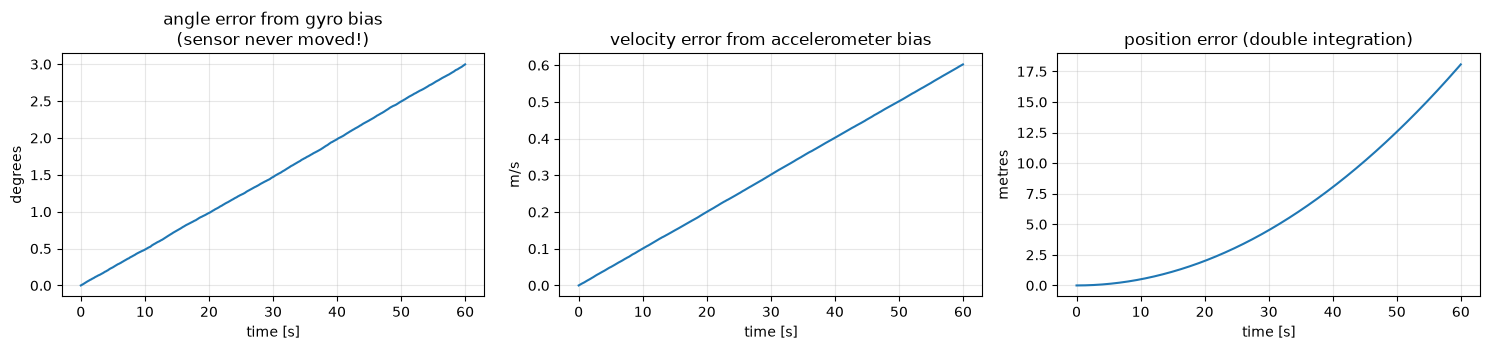

After 60 s of doing NOTHING:  angle error = 3.00 deg,  position error = 18.1 m
(theory: position error = 0.5 * bias * t^2 = 18.0 m)


In [2]:
from __future__ import annotations           # (technical: lets us write type hints freely)

# ---- Chapter 1 demo: why a tiny bias ruins a naive integration -------------------------
import numpy as np                      # numpy = the library for fast maths on arrays of numbers
import matplotlib.pyplot as plt         # matplotlib = the library that draws plots

rng = np.random.default_rng(0)          # a random-number generator (seed 0 => same numbers every run)
dt = 0.01                               # time between two samples: 0.01 s  (100 samples per second)
t = np.arange(0, 60, dt)                # time axis: 0, 0.01, 0.02, ... 59.99 seconds

# A sensor lying perfectly still: the TRUE rotation rate and the TRUE acceleration are both zero.
gyro_bias  = np.deg2rad(0.05)           # gyroscope bias: 0.05 degrees/second (a very good gyro!)
gyro_noise = np.deg2rad(0.03)           # gyroscope noise: 0.03 degrees/second (std. deviation)
acc_bias   = 0.01                       # accelerometer bias: 0.01 m/s^2 (about 1 milli-g)
acc_noise  = 0.003                      # accelerometer noise: 0.003 m/s^2

# What the sensor reports = truth (0) + bias + noise
# Here we are just considering white noise
gyro_reading = gyro_bias + gyro_noise * rng.standard_normal(len(t))
acc_reading  = acc_bias  + acc_noise  * rng.standard_normal(len(t))

# "Integrating" = adding up, step by step:  angle = sum(rate*dt),  speed = sum(acc*dt),  position = sum(speed*dt)
angle    = np.cumsum(gyro_reading) * dt
velocity = np.cumsum(acc_reading)  * dt
position = np.cumsum(velocity)     * dt

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(t, np.rad2deg(angle));  ax[0].set_title("angle error from gyro bias\n(sensor never moved!)")
ax[0].set_ylabel("degrees")
ax[1].plot(t, velocity);           ax[1].set_title("velocity error from accelerometer bias"); ax[1].set_ylabel("m/s")
ax[2].plot(t, position);           ax[2].set_title("position error (double integration)");    ax[2].set_ylabel("metres")
for a in ax: a.set_xlabel("time [s]"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"After 60 s of doing NOTHING:  angle error = {np.rad2deg(angle[-1]):.2f} deg,  "
      f"position error = {position[-1]:.1f} m")
print(f"(theory: position error = 0.5 * bias * t^2 = {0.5*acc_bias*60**2:.1f} m)")

### 🔑 What we learnt
A bias of only 1 milli-g makes the *position* wrong by **18 m after one minute**, although nothing moved.
Double integration is brutal: the error grows like $\tfrac12\,b\,t^2$.
Therefore the whole pipeline has two goals:

1. **estimate the biases** (so we can subtract them), and
2. **use several sensors and smoothing** so the remaining errors are as small as possible.

The tool that does this is the **Kalman filter**. But first we need two more ingredients:
reference frames and rotations.

# Chapter 2 - Reference frames and rotations

### 🧠 Intuition: two ways of describing the same arrow
Hold a pencil. Tell a friend "it points to *my right*" - that is described in **your** frame
(it changes when you turn). Tell them "it points **north-east and slightly up**" - described in the
**Earth** frame (it does not change when you turn).

* **Body frame (B):** axes $x_B, y_B, z_B$ glued to the sensor. The sensor always reads its numbers here.
* **Earth frame (E):** axes $X, Y$ horizontal and $Z$ **up**. Inertial reference system (fixed). The GIFs and final plots are drawn here.

A **rotation matrix** $R$ is a $3\times 3$ table of numbers that converts a vector written in the body frame
into the same vector written in the Earth frame:

$$
\mathbf v_E = R\,\mathbf v_B .
$$

Its inverse is simply the transpose: $\mathbf v_B = R^{\mathsf T}\mathbf v_E$.

### 📐 Formula

**(a) The cross product as a matrix - the `skew` function.**
For a vector $\mathbf v=(v_1,v_2,v_3)$ define
$$
[\mathbf v]_\times=\begin{pmatrix}0&-v_3&v_2\\ v_3&0&-v_1\\ -v_2&v_1&0\end{pmatrix},
\qquad [\mathbf v]_\times\,\mathbf u=\mathbf v\times\mathbf u .
$$
This lets us write "cross product with $\mathbf v$" as an ordinary matrix multiplication, which matrices-based
filters need.

**(b) Rotation vector and the exponential map - `exp_so3`.**
A rotation can be described by a vector $\boldsymbol\phi$: its **direction** is the axis you rotate about,
its **length** is the angle (in radians). The matrix of that rotation is
$$
R=\operatorname{Exp}(\boldsymbol\phi)=\exp\!\big([\boldsymbol\phi]_\times\big)
= I+\frac{\sin\theta}{\theta}[\boldsymbol\phi]_\times+\frac{1-\cos\theta}{\theta^{2}}[\boldsymbol\phi]_\times^{2},
\quad\theta=\|\boldsymbol\phi\|.
$$

**(c) How gravity looks from a turning sensor.**
Gravity is fixed in the Earth, but the sensor rotates, so the *body-frame* gravity vector rotates the
opposite way:
$$
\dot{\mathbf g}_B=-\boldsymbol\omega_B\times\mathbf g_B=-[\boldsymbol\omega_B]_\times\,\mathbf g_B .
$$
This single equation is the **link between the gyroscope and the accelerometer**: the gyro tells how
the gravity direction must change, and the accelerometer measures that direction. The filter exploits it.

### Watch out! You cannot add rotation matrices
Adding two rotation matrices gives a matrix that is not a rotation. Rotations are *composed* by
multiplication, and a small turn is applied as $R_{k+1}=R_k\,\operatorname{Exp}(\boldsymbol\omega\,\Delta t)$.
That is why the code uses `exp_so3` instead of "$R+\dots$".

skew(v)@u   = [  6.5 -10.    4.5]
np.cross    = [  6.5 -10.    4.5]    <- identical

rotate (1,0,0) by 90 deg about Z -> [0. 1. 0.]


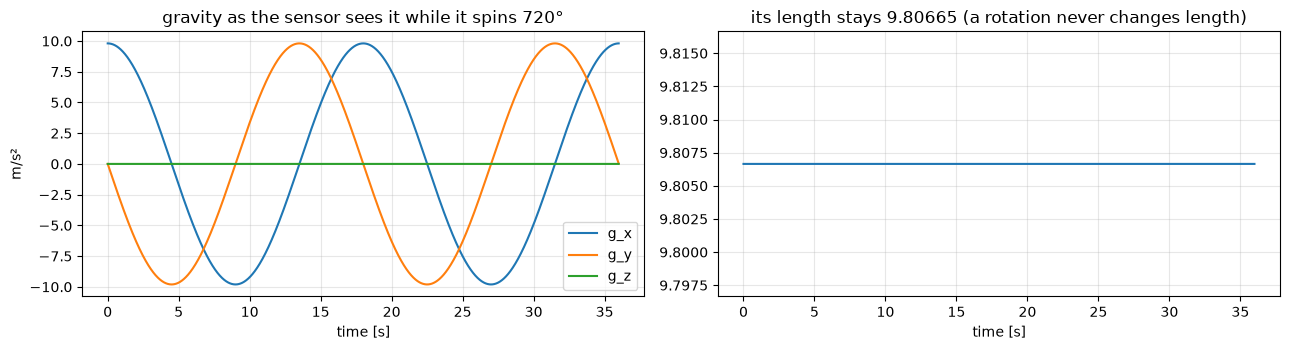

max difference step-by-step vs exact: 3.019806626980426e-13


In [3]:
# ---- Chapter 2 demo: skew matrix, rotation, and the gravity equation g_dot = -w x g --------
from scipy.spatial.transform import Rotation as Rot    # a ready-made, reliable rotation toolbox

def skew(v):
    # Build the 3x3 'cross-product matrix' of a 3-vector v (see formula (a) above).
    v = np.asarray(v, float)                  # make sure v is a numpy array of decimal numbers
    return np.array([[0.0,  -v[2],  v[1]],    # first row
                     [v[2],  0.0,  -v[0]],    # second row
                     [-v[1], v[0],  0.0]])    # third row

def exp_so3(phi):
    # Turn a rotation vector (axis * angle) into a 3x3 rotation matrix (formula (b)).
    return Rot.from_rotvec(np.asarray(phi, float)).as_matrix()

# 1) skew(v) @ u really is the cross product v x u
v, u = np.array([1., 2., 3.]), np.array([-2., 0.5, 4.])
print("skew(v)@u   =", skew(v) @ u)
print("np.cross    =", np.cross(v, u), "   <- identical")

# 2) Rotate the x-axis by 90 degrees about the vertical axis Z: it should become the y-axis
R = exp_so3([0, 0, np.deg2rad(90)])
print("\nrotate (1,0,0) by 90 deg about Z ->", np.round(R @ np.array([1., 0., 0.]), 6))

# 3) Gravity seen by a sensor that spins about its own z axis at 20 deg/s:
#    Earth gravity is (0,0,-G0).  We integrate g_dot = -w x g step by step and compare with
#    the exact answer  g_B(t) = R(t)^T g_E.
G0 = 9.80665
w_B = np.deg2rad([0, 0, 20.0])                     # constant body-frame rotation rate (rad/s)
g0_B = np.array([G0, 0.0, 0.0])                    # at t=0 gravity points along the body x axis
dt, T = 0.01, 36.0                                 # 36 s at 20 deg/s = 720 degrees = two full turns
tt = np.arange(0, T, dt)
g_num = np.empty((len(tt), 3)); g_num[0] = g0_B
for k in range(len(tt) - 1):
    g_num[k + 1] = exp_so3(-w_B * dt) @ g_num[k]   # rotate g backwards by w*dt each step
g_exact = np.array([exp_so3(-w_B * s) @ g0_B for s in tt])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(tt, g_num[:, 0], label="g_x"); ax[0].plot(tt, g_num[:, 1], label="g_y"); ax[0].plot(tt, g_num[:, 2], label="g_z")
ax[0].set_title("gravity as the sensor sees it while it spins 720°"); ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("m/s²")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(tt, np.linalg.norm(g_num, axis=1)); ax[1].set_ylim(G0 - 0.01, G0 + 0.01)
ax[1].set_title("its length stays 9.80665 (a rotation never changes length)"); ax[1].set_xlabel("time [s]"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("max difference step-by-step vs exact:", np.abs(g_num - g_exact).max())

### 🔑 What we learnt
* While the sensor turns, the accelerometer's gravity reading **draws a circle** (two full turns here).
  That is how the gravity direction looks to an accelerometer when the support turns about a horizontal axis, as in the rotation tests of your data: it draws a circle.
* The **length** of $\mathbf g$ never changes. This is the physical fact behind the "gravity-modulus
  constraint" $\|\mathbf g\|=G_0$ that we impose later (Chapter 9).

# Chapter 3 - The Kalman filter, from scratch

### 🧠 Intuition
You want to know the temperature. You have

* a **forecast** ("prediction"): 20 °C, but forecasts can be off by $\pm$ 2 °C;
* a **thermometer** ("measurement"): 23 °C, but it is noisy by $\pm$ 1 °C.

Which do you trust? The **more precise** one - so you take a *weighted average*, weighing each witness by
**how reliable it is**. The result is both closer to the truth and **more certain** than either alone.
That is the entire idea of the Kalman filter, repeated at every time step:

> **1. Predict** what the world should look like now (using physics/known dynamics) -> uncertainty grows.
> **2. Update** the prediction with the new measurement (weighted average) -> uncertainty shrinks.

### 📐 Formula (scalar version)

State estimate $\hat x$ with variance $P$ (variance = standard deviation squared = "how unsure"):

**Predict** (the true value drifts a little each step; $Q$ = variance added by that drift):
$$ \hat x^- = \hat x, \qquad P^- = P + Q . $$
**Update** with a measurement $z$ of variance $R$:
$$
K=\frac{P^-}{P^-+R}\ \ (\text{Kalman gain}),\qquad
\hat x=\hat x^-+K\,(z-\hat x^-),\qquad
P=(1-K)\,P^- .
$$
* $z-\hat x^-$ is the **innovation** ("surprise"): measurement minus prediction.
* $K$ is between 0 and 1. If the sensor is very noisy ($R$ large) then $K\approx0$: *ignore the measurement*.
  If the prediction is very uncertain ($P^-$ large) then $K\approx1$: *believe the measurement*.

### 📐 Formula (vector version)
Now the state is a **vector** $\mathbf x$ (15 numbers) and the uncertainty is a **covariance matrix** $P$
($15\times15$; diagonal = variances, off-diagonal = "if this is wrong, that is probably wrong too").

$$
\begin{aligned}
&\textbf{Predict:} && \mathbf x^-=F\,\mathbf x,\qquad P^-=F\,P\,F^{\mathsf T}+Q\\[2pt]
&\textbf{Update:}  && S=H P^- H^{\mathsf T}+R,\qquad K=P^-H^{\mathsf T}S^{-1}\\
&                  && \mathbf x=\mathbf x^-+K\,\boldsymbol\nu,\quad \boldsymbol\nu=\mathbf z-h(\mathbf x^-),\qquad
                      P=(I-KH)\,P^-\,(I-KH)^{\mathsf T}+K R K^{\mathsf T}
\end{aligned}
$$
* $F$ - how the state evolves in one step; $Q$ - "process noise": how much the state is allowed to wander.
* $h(\mathbf x)$ - what the sensors *should* read for state $\mathbf x$; $H$ - its slope (Jacobian).
* $R$ - measurement noise; $S$ - total uncertainty of the innovation.
* The last form of $P$ is the **Joseph form**: mathematically equal to $(I-KH)P^-$ but numerically safer
  (it keeps $P$ a valid covariance despite rounding).

### Extended Kalman Filter (EKF)
If $h$ (or the dynamics) is *not* a straight line - here $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$
multiplies two unknowns - we replace it by its **tangent line** at the current estimate ($H$ = slope).
That is the "Extended" in EKF.

### Adaptive
$Q$ and $R$ are never perfectly known. An *adaptive* filter watches the innovations: if the surprises are
consistently bigger than expected, it increases the noise values; if smaller, it decreases them.

### Smoother (RTS)
The filter only uses the **past**. But the data *after* an instant also tell something about it.
The **Rauch–Tung–Striebel (RTS) smoother** runs *backward* after the filter and revises every estimate using
the future. When the model is right, a smoothed estimate is at least as accurate as the filtered one (we will see in Chapter 5 that, with an imperfect model, this is not guaranteed). We will use it twice.

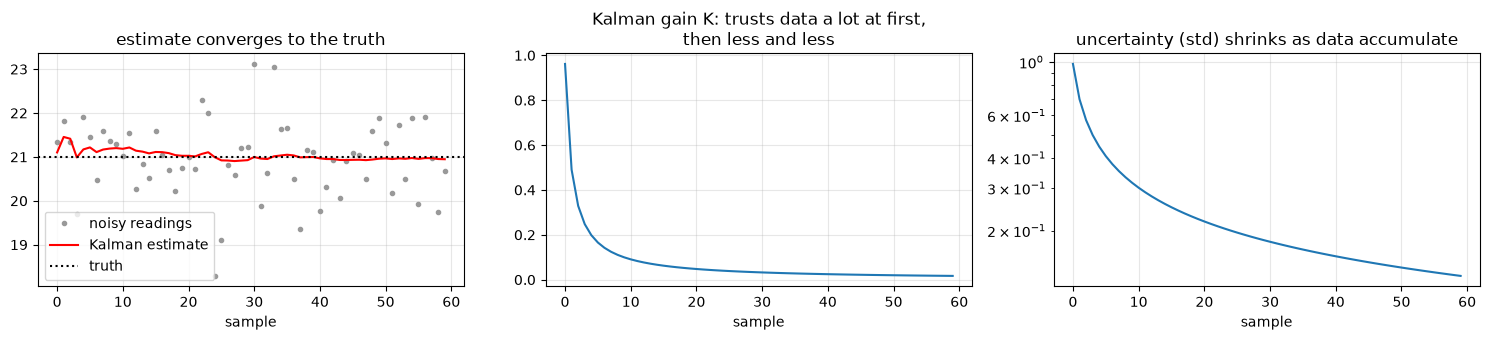

final estimate 20.95 C, +/- 0.13 C (plain average of data: 20.95)


In [4]:
# ---- Chapter 3 demo A: a scalar Kalman filter measuring a constant temperature ----------------
rng = np.random.default_rng(1)
true_T = 21.0                      # the real (unknown to the filter) temperature
R = 1.0 ** 2                       # thermometer noise variance (std 1 degree)
Q = 1e-5                           # the temperature is almost constant -> tiny process noise
n = 60
z = true_T + np.sqrt(R) * rng.standard_normal(n)      # the noisy thermometer readings

x_hat, P = 15.0, 5.0 ** 2          # a bad first guess (15 C) that we admit is very uncertain (std 5)
xs, Ps, Ks = [], [], []
for k in range(n):
    # PREDICT: the value is unchanged, but our uncertainty grows slightly
    P = P + Q
    # UPDATE: weighted average of prediction and measurement
    K = P / (P + R)                # Kalman gain: how much to trust the new measurement (0..1)
    x_hat = x_hat + K * (z[k] - x_hat)   # move toward the measurement by a fraction K
    P = (1 - K) * P                # uncertainty shrinks
    xs.append(x_hat); Ps.append(P); Ks.append(K)
xs, Ps, Ks = map(np.array, (xs, Ps, Ks))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(z, ".", color="0.6", label="noisy readings"); ax[0].plot(xs, "r", label="Kalman estimate")
ax[0].axhline(true_T, color="k", ls=":", label="truth"); ax[0].legend(); ax[0].set_title("estimate converges to the truth")
ax[1].plot(Ks); ax[1].set_title("Kalman gain K: trusts data a lot at first,\nthen less and less")
ax[2].semilogy(np.sqrt(Ps)); ax[2].set_title("uncertainty (std) shrinks as data accumulate")
for a in ax: a.set_xlabel("sample"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"final estimate {xs[-1]:.2f} C, +/- {np.sqrt(Ps[-1]):.2f} C (plain average of data: {z.mean():.2f})")

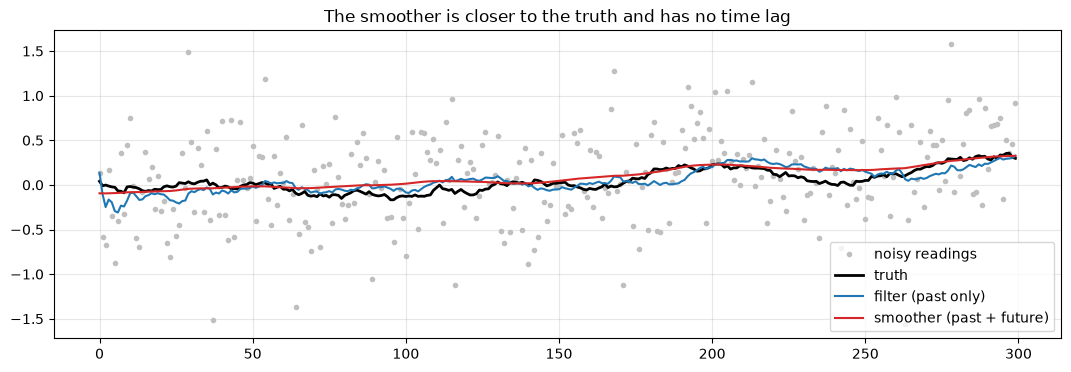

RMS error  raw data 0.488   filter 0.098   smoother 0.078


In [5]:
# ---- Chapter 3 demo B: Filter vs Smoother on a wandering quantity ----------------------------
# The true quantity does a random walk (it wanders); we only see noisy readings of it.
rng = np.random.default_rng(3)
n = 300
Q, R = 0.02 ** 2, 0.5 ** 2
truth = np.cumsum(np.sqrt(Q) * rng.standard_normal(n))     # random walk
z = truth + np.sqrt(R) * rng.standard_normal(n)            # noisy readings

# ---- forward pass = ordinary Kalman filter, remembering what the RTS smoother will need
xf = np.zeros(n); Pf = np.zeros(n)      # filtered estimate and variance (after the update)
xp = np.zeros(n); Pp = np.zeros(n)      # predicted estimate and variance (before the update)
x, P = z[0], R
for k in range(n):
    xp[k], Pp[k] = x, P + Q             # predict: same value, bigger uncertainty
    K = Pp[k] / (Pp[k] + R)             # gain
    x = xp[k] + K * (z[k] - xp[k])      # update
    P = (1 - K) * Pp[k]
    xf[k], Pf[k] = x, P

# ---- backward pass = RTS smoother: walk from the end back to the start
xs, Ps = xf.copy(), Pf.copy()
for k in range(n - 2, -1, -1):
    C = Pf[k] / Pp[k + 1]                          # smoother gain: how much the future informs the past
    xs[k] = xf[k] + C * (xs[k + 1] - xp[k + 1])    # correct with the future's "surprise"
    Ps[k] = Pf[k] + C * C * (Ps[k + 1] - Pp[k + 1])

plt.figure(figsize=(13, 4))
plt.plot(z, ".", color="0.75", label="noisy readings")
plt.plot(truth, "k", lw=2, label="truth")
plt.plot(xf, "tab:blue", label="filter (past only)")
plt.plot(xs, "tab:red", label="smoother (past + future)")
plt.legend(); plt.grid(alpha=0.3); plt.title("The smoother is closer to the truth and has no time lag"); plt.show()
rms = lambda e: np.sqrt(np.mean(e ** 2))
print(f"RMS error  raw data {rms(z-truth):.3f}   filter {rms(xf-truth):.3f}   smoother {rms(xs-truth):.3f}")

### 🔑 What we learn
* The filter is a **running weighted average** whose weights come from the uncertainties.
* The smoother removes the **lag** of the filter (the blue line trails behind) because it also looks ahead. (This demo has a perfect model; Chapter 5 shows what happens when the model is only approximate.)
* Everything in the project is a bigger version of exactly these two demos: more numbers per state,
  matrices instead of scalars, and physics (gravity + rotation) inside the "predict" step.

# Chapter 4 - Modelling one IMU: the 15 unknowns

We now describe, with equations, *everything the filter believes* about one sensor.

### 4.1 The state: 15 numbers that we want to know at every instant

$$
\mathbf x=\big[\;\underbrace{\mathbf a}_{3},\ \underbrace{\boldsymbol\omega}_{3},\ \underbrace{\mathbf b_a}_{3},\
\underbrace{\mathbf b_\omega}_{3},\ \underbrace{\mathbf g}_{3}\;\big]\in\mathbb R^{15}
$$

| Slice in the code | Symbol | Meaning | Units |
|---|---|---|---|
| `SL["a"]`  = 0:3   | $\mathbf a$ | **true** acceleration (gravity removed), in the body frame | m/s² |
| `SL["w"]`  = 3:6   | $\boldsymbol\omega$ | **true** rotation rate, body frame | rad/s |
| `SL["ba"]` = 6:9   | $\mathbf b_a$ | accelerometer bias | m/s² |
| `SL["bw"]` = 9:12  | $\mathbf b_\omega$ | gyroscope bias | rad/s |
| `SL["g"]`  = 12:15 | $\mathbf g$ | gravity vector, body frame | m/s² |

*Note what is missing:* there is **no orientation in the state**. The filter never tracks angles; it tracks the
*gravity direction* instead, which carries the tilt information. Orientation is rebuilt later (Chapter 7).

### 4.2 How the unknowns are allowed to change between two samples (the "predict" model)

| Quantity | Model | In plain words |
|---|---|---|
| $\mathbf a$ | $\mathbf a_{k+1}=e^{-\Delta t/\tau_a}\,\mathbf a_k+\text{jump}$ | acceleration fades to 0 unless data keep it alive (**Gauss–Markov**, $\tau_a=2$ s) |
| $\boldsymbol\omega$ | $\boldsymbol\omega_{k+1}=e^{-\Delta t/\tau_\omega}\,\boldsymbol\omega_k+\text{jump}$ | same for rotation rate ($\tau_\omega=2$ s) |
| $\mathbf b_a,\ \mathbf b_\omega$ | $\mathbf b_{k+1}=\mathbf b_k+\text{tiny noise}$ | biases are almost constant (**random walk**) |
| $\mathbf g$ | $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$ | gravity turns opposite to the sensor (Chapter 2) |

"Jump" means: a *random kick* each step, with a size we call the **process-noise standard deviation**.
If the kick is large the filter reacts quickly to changes; if small it is smooth but slow.

### 4.3 What the sensors should read (the "update" models)

$$
\mathbf z_\omega=\boldsymbol\omega+\mathbf b_\omega+\mathbf v_\omega,\qquad
\mathbf z_a=\mathbf a+\mathbf b_a-\mathbf g+\mathbf v_a,\qquad
\underbrace{\|\mathbf g\|=G_0}_{\text{extra "pseudo-measurement"}}
$$

The last line is a **known fact** (gravity has a fixed strength, for assumption) that we feed to the
filter as if it were a measurement with a small noise $\sigma_{\|g\|}=0.05$ m/s². It helps the filter
separate gravity from acceleration.

### 4.4 The order of operations for each new sample (important!)

```
for every row k of the CSV:
    1. PREDICT      a, w fade slightly; uncertainty grows            (state a, w, biases)
    2. UPDATE GYRO  compare gyro reading with  w + bw                (fixes w and bw)
    3. GRAVITY STEP rotate g by the freshly corrected w:  g_dot = -w x g
    4. UPDATE ACC   compare accelerometer with  a + ba - g           (fixes a, ba, g)
                    plus the pseudo-measurement ||g|| = G0
    5. ADAPT        look at the recent "surprises" and re-tune the noise levels
```
Why gyro first? Because the gyro gives $\boldsymbol\omega$, and $\boldsymbol\omega$ is needed to move $\mathbf g$
forward correctly *before* we compare $\mathbf g$ with the accelerometer.

### 4.5 Process noise $Q$ in more detail
A kick in $\boldsymbol\omega$ also disturbs $\mathbf g$ (because $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$),
so the noises are **correlated**. The code builds
$$
Q = G\,\operatorname{diag}(\sigma_a^2,\sigma_\omega^2)\,G^{\mathsf T}+\operatorname{diag}(\text{random-walk variances}),
\quad
G=\begin{pmatrix} I & 0\\ 0& I\\ 0&\Delta t\,[\mathbf g]_\times\end{pmatrix}\text{(rows for a, w, g)} .
$$

### 4.6 Adaptive noise (how the filter re-tunes itself)
Let $\boldsymbol\nu$ be the innovations (surprises). Over a rolling window of the last 100 samples we measure their
average square $F=\overline{\nu^2}$. Surprises that are bigger than the filter expected mean "my noise
settings are too small". The code moves each standard deviation toward the level implied by $F$ with an
exponential moving average:
$$
\sigma_{\text{new}}=(1-d_k)\,\sigma_{\text{old}}+d_k\,\sigma_{\text{target}},\qquad d_k=\frac{1-b}{1-b^{k+1}},\ b=0.98 .
$$
**Safeguards for dynamic motion** (very important in this project): a real, fast rotation produces large
gyro innovations. A naive adaptive filter would conclude "the gyro is noisy!" and stop trusting it, making
$\boldsymbol\omega$ collapse to zero. Therefore (a) the gyro noise $R_\omega$ is **frozen**, (b) the bias
random walks are **frozen**, and (c) the rotation-rate process noise is kept between 0.5°/s and 5°/s.

### 4.7 The smoother in more detail ("extended RTS")
During the forward pass we store, for every sample $k$: the filtered state $\mathbf x_f(k)$ and covariance $P_f(k)$,
the prediction $\mathbf x_p(k),P_p(k)$ made just before the accelerometer update, and the combined step matrix
$\Phi(k)=F_3\,(I-K_gH_g)\,F_1$ (predict → gyro update → gravity step). Then, going **backward**:
$$
\begin{align}
C_k=P_f(k)\,\Phi(k{+}1)^{\mathsf T}\,P_p(k{+}1)^{-1},\\
\mathbf x_s(k)=\mathbf x_f(k)+C_k\big[\mathbf x_s(k{+}1)-\mathbf x_p(k{+}1)\big],\\
P_s(k)=P_f(k)+C_k\big[P_s(k{+}1)-P_p(k{+}1)\big]C_k^{\mathsf T}.
\end{align}
$$
It is the scalar smoother of Chapter 3 with matrices.

### 4.8 Starting values from a stationary interval
At the beginning the sensor is **still** (hopefully). Then $\mathbf a=0$, $\boldsymbol\omega=0$ and
$\mathbf z_a=\mathbf b_a-\mathbf g$, $\mathbf z_\omega=\mathbf b_\omega$. So the average readings give:
gravity direction $=-$(mean accelerometer), gyro bias $=$ mean gyro, accelerometer bias $=$ whatever is left after
removing gravity of length $G_0$.

# Chapter 5 — The code: one adaptive EKF + smoother

### 💻 5.1 Imports and constants
First the "toolbox" (imports) and the fixed numbers the project uses. Read the comments: each constant is explained.

In [6]:
# ======================= imports: the tools we borrow from other people's code =======================
import argparse                              # reads options typed in the command line (used by main())
import re                                    # 're' = regular expressions: pattern matching in text (column names)
import warnings                              # lets the program print warnings
import sys, types                            # small system helpers (used once, to register the GIF code below)
from collections import deque                # 'deque' = a list that forgets its oldest items (rolling window)
from dataclasses import dataclass            # lets us define a settings container compactly
from pathlib import Path                     # file and folder paths that work on any computer
from typing import Dict, List, Optional, Sequence, Tuple   # only for documentation of what a function expects

import numpy as np                           # fast maths on arrays of numbers
import pandas as pd                          # reads tables (CSV files)
import matplotlib.pyplot as plt              # plotting
from scipy.spatial.transform import Rotation as Rot   # reliable 3-D rotation maths
from IPython.display import Image, display   # shows pictures / GIFs inside the notebook

plt.rcParams["figure.dpi"] = 100             # sharper plots in the notebook

# ======================= constants of the AEKF module (aekf_rts.py) =======================
I3 = np.eye(3)                               # the 3x3 identity matrix ("do nothing" matrix)
N_X = 15                                     # number of unknowns per sensor: a(3)+w(3)+ba(3)+bw(3)+g(3)

SL = {                                       # SL = "slices": which positions of the 15-vector belong to what
    "a":  slice(0, 3),                       # positions 0,1,2   -> true acceleration
    "w":  slice(3, 6),                       # positions 3,4,5   -> true angular velocity
    "ba": slice(6, 9),                       # positions 6,7,8   -> accelerometer bias
    "bw": slice(9, 12),                      # positions 9,10,11 -> gyroscope bias
    "g":  slice(12, 15),                     # positions 12,13,14-> gravity vector (body frame)
}
IU = {3: np.triu_indices(3)}                 # (unused helper index table kept from the original file)

# ======================= constants of the runner (run_general_multisensor_dynamic.py) =======================
G0 = 9.80665                                 # standard gravity [m/s^2]
DT_FALLBACK = 1.0 / 120.0                    # sample period used if nothing else is specified (120 Hz sensor)
DEFAULT_ALIGN_S = 10.0                       # length [s] of the initial 'sensor is still' interval used for start values
SECOND_RTS_DEFAULT = True                    # run the second smoother after the fusion?
SECOND_RTS_R_INFLATION = 10.0                # second smoother: trust the fused data 10x less (variance x10)
SECOND_RTS_Q_SCALE = 1.0                     # second smoother: how freely the curve may wiggle (x1 = as individual filters)
REGISTRATION_STRIDE = 5                      # registration uses every 5th sample (speed)
REGISTRATION_MIN_ACTIVE_DPS = 1.0            # a sample counts as 'moving' above 1 deg/s (diagnostic only)
EIG_FLOOR = 1e-10                            # smallest allowed 'eigenvalue' when inverting covariances (numerical safety)
R0_WINDOW_S = 5.0                            # seconds at the start used to measure the sensors' noise level

ACC_RE = re.compile(r"^(s\d+)_acc_([xyz]) \[mg\]$")    # pattern of accelerometer column names, e.g. 's1_acc_x [mg]'
GYR_RE = re.compile(r"^(s\d+)_gyro_([xyz]) \[dps\]$")  # pattern of gyroscope column names, e.g. 's2_gyro_z [dps]'

AXES = ("X", "Y", "Z")                       # axis names used in plots
COLORS = {"fused": "black", "fused_rts": "tab:purple", "gravity": "tab:cyan"}   # plot colours

QTY = {                                      # for each plotted quantity: (title, key, display scale, display unit)
    "a":   ("acceleration", "aE", 1e6, r"$\mu$m/s$^2$"),
    "w":   ("angular velocity", "wE", 1e3 * np.degrees(1.0), "mdps"),
    "ba":  ("accelerometer bias", "baE", 1e6, r"$\mu$m/s$^2$"),
    "bw":  ("gyroscope bias", "bwE", 1e3 * np.degrees(1.0), "mdps"),
    "g":   ("gravity vector", "gE", 1e6, r"$\mu$m/s$^2$"),
    "v":   ("velocity", "v", 1e3, "mm/s"),
    "p":   ("position", "p", 1e3, "mm"),
    "theta": ("angular position", "theta", 1e3 * np.degrees(1.0), "mdeg"),
}
print("constants defined; state has", N_X, "numbers per sensor")

constants defined; state has 15 numbers per sensor


### 💻 5.2 Two tiny helper functions

* `skew` — the cross-product matrix of Chapter 2.
* `rk4_phi` — computes "how much does a quantity rotate in one time step?" For $\dot{\mathbf g}=A\mathbf g$ the exact
  answer is the matrix exponential $e^{A\Delta t}$; `rk4_phi` approximates it with a polynomial of degree 4
  (the same formula used by the classical Runge–Kutta-4 integrator). For our tiny $\Delta t$ it is essentially exact.

In [7]:
def skew(v: np.ndarray) -> np.ndarray:
    """Return [v]_x such that [v]_x u = v x u."""
    # Make sure v is an array of decimal numbers.
    v = np.asarray(v, float)
    # Write the 3x3 table row by row (zeros on the diagonal, +/- components elsewhere).
    return np.array([
        [0.0,  -v[2],  v[1]],
        [v[2],  0.0, -v[0]],
        [-v[1], v[0],  0.0],
    ])

In [8]:
def rk4_phi(A: np.ndarray, dt: float) -> np.ndarray:
    """RK4 polynomial map for x_dot = A x with constant A over dt."""
    # n = size of the square matrix A (3 for gravity).
    n = A.shape[0]
    # M = A * dt : the 'amount of change' during one step.
    M = dt * A
    # Powers of M, needed for the polynomial: M^2 ...
    M2 = M @ M
    # exp(M) ~ I + M + M^2/2 + M^3/6 + M^4/24   (a truncated Taylor series; very accurate for small M).
    return (
        np.eye(n)
        + M
        + 0.5 * M2
        + (M2 @ M) / 6.0
        + (M2 @ M2) / 24.0
    )

### 💻 5.3 The settings container: `AEKFConfig`
A *dataclass* is just a labelled box of settings. Each line below declares one setting, its type, and a default value.
The lists with 15 entries are in the order `[a(3), w(3), ba(3), bw(3), g(3)]`.

In [9]:
@dataclass
    # SETTINGS BOX. Nothing is computed here: it only stores numbers that tune the filter.
    # std = standard deviation = typical size of an uncertainty.  Variance = std**2.
class AEKFConfig:
    dt: float
    G0: float = 9.80665

    # Gauss-Markov time constants for a and w.
    tau_a: float = 2.0
    tau_w: float = 2.0

    # Initial state/covariance scales, all length 15:
    # [a(3), w(3), ba(3), bw(3), g(3)].
    P0_std: Optional[np.ndarray] = None

    # Adaptive process-variance vector, length 15:
    # a,w = piecewise-white-noise jump stds;
    # ba,bw,g = random-walk stds.
    Q0_std: Optional[np.ndarray] = None

    # Measurement stds [acc xyz, gyro xyz].
    R0_std: Optional[np.ndarray] = None

    # Optional gravity-magnitude pseudo-measurement ||g|| = G0.
    # Set to 0 to disable it.
    sigma_gnorm: float = 0.05

    # Adaptive noise.
    enable_adaptive: bool = True
    window: int = 100
    b: float = 0.98
    min_eig_floor: float = 1e-12

    # Stationary floors for adaptive process / measurement stds.
    Q_min_std: Optional[np.ndarray] = None   # length 15
    R_min_std: Optional[np.ndarray] = None   # length 6

    # Selective adaptation.  In dynamic experiments the gyro residual contains
    # real angular motion, so adapting R_gyr directly from that residual can
    # create a positive-feedback failure: large motion -> large R_gyr -> small
    # K_w -> w stays near zero -> still-large innovation.  Keep gyro R fixed by
    # default for dynamic runs, while still allowing acceleration/R and a,w Q
    # adaptation.
    adapt_gyro_R: bool = True
    adapt_bias_process: bool = True

    # Guards for the angular-rate process model.  These are jump standard
    # deviations in rad/s.  The minimum prevents a too-small imported prior
    # from making w effectively deterministic at zero.
    min_w_jump_std: float = 0.0
    max_w_jump_std: Optional[float] = None

### 💻 5.4 The filter itself: class `AEKFRTS`
A *class* is a bundle of memory + actions. Here the memory is the current estimate `self.x`, its uncertainty
`self.P`, the noise levels, and the stored history; the actions are the methods (`step`, `smooth`, ...).
Read the class from top to bottom: it follows exactly the list of Section 4.4.

| Method | Job |
|---|---|
| `__init__` | store settings, set the first guess and the first uncertainty |
| `build_Q` | construct the process-noise matrix $Q$ (Section 4.5) |
| `step` | process **one** sample: predict → gyro → gravity → accelerometer → adapt |
| `run` | loop `step` over all samples, then call `smooth` |
| `_predict`, `_update_gyro`, `_propagate_gravity`, `_update_acc` | the four physical sub-steps |
| `_correct` | the generic Kalman-update formulas (Chapter 3) |
| `_adapt` | adaptive noise (Section 4.6) |
| `smooth`, `_psd_inverse` | the backward RTS pass (Section 4.7) |
| `stationary_initial_state` | start values from a still interval (Section 4.8) |
| `_R_from_gravity`, `reconstruct_navigation` | an older single-IMU post-processor (kept for completeness; the multi-sensor runner does not call it) |

A leading underscore (`_predict`) is only a naming habit meaning "internal helper".

In [10]:
class AEKFRTS:
    """15-state adaptive EKF with an extended RTS smoother."""

    def __init__(self, cfg: AEKFConfig, x0: np.ndarray):
        # Remember the settings (time step, noise levels, ...).
        self.cfg = cfg
        # self.x = our CURRENT best guess of the 15 unknowns (a copy, so we never change the caller's array).
        self.x = np.asarray(x0, float).copy()

        # Safety check: the state must contain exactly 15 numbers.
        if self.x.shape != (N_X,):
            raise ValueError(f"x0 must have shape ({N_X},), got {self.x.shape}")

        # Initial gravity is allowed to be slightly off-norm, but normalize
        # it when nonzero because gravity magnitude is known.
        # Gravity's strength is known (G0). If the first guess has another length, rescale it to G0.
        gnorm = np.linalg.norm(self.x[SL["g"]])
        if gnorm > 0:
            self.x[SL["g"]] *= cfg.G0 / gnorm

        # P = covariance matrix (15x15) = how unsure we are. Start with a diagonal: no links between states yet.
        # (std squared = variance.)
        self.P = np.diag(self._check_vec(cfg.P0_std, N_X, "P0_std") ** 2)

        # q = process-noise variances: how much each state may wander during one step.
        q0_std = self._check_vec(cfg.Q0_std, N_X, "Q0_std")
        self.q = q0_std ** 2
        # Never let the rotation-rate wander-allowance fall below a minimum,
        # otherwise the filter would believe the rotation rate is frozen at zero.
        if cfg.min_w_jump_std > 0.0:
            self.q[SL["w"]] = np.maximum(
                self.q[SL["w"]], cfg.min_w_jump_std ** 2
            )

        # R = measurement noise variances: first 3 for the accelerometer, last 3 for the gyroscope.
        R0 = self._check_vec(cfg.R0_std, 6, "R0_std")
        self.R_acc = R0[0:3].copy() ** 2
        self.R_gyr = R0[3:6].copy() ** 2

        # Lower limits ('floors') so the adaptive noise can never shrink all the way to zero.
        qmin = (
            np.zeros(N_X)
            if cfg.Q_min_std is None
            else self._check_vec(cfg.Q_min_std, N_X, "Q_min_std")
        )
        rmin = (
            np.zeros(6)
            if cfg.R_min_std is None
            else self._check_vec(cfg.R_min_std, 6, "R_min_std")
        )

        # Floors are scaled by (1-b), the steady-state weight of the adaptation formula (Section 4.6).
        d_inf = 1.0 - cfg.b
        self.Q_min_sq = qmin * d_inf
        self.R_min_sq = rmin * d_inf

        # Gauss-Markov decay factors: every step a and w are multiplied by exp(-dt/tau) < 1 (they slowly fade).
        self.fa = np.exp(-cfg.dt / cfg.tau_a)
        self.fw = np.exp(-cfg.dt / cfg.tau_w)

        # Gravity as seen from the Earth: straight down.
        self.g_earth = np.array([0.0, 0.0, -cfg.G0])

        # Rolling memories of the last `window` innovations (the 'surprises') used to adapt the noise.
        self.hist_g = deque(maxlen=cfg.window)
        self.hist_a = deque(maxlen=cfg.window)
        self.step_i = 0

        # Arrays populated by step(..., record=True).
        # Empty lists that will store the whole forward-pass history for the smoother:
        # xf,Pf = after update; xp,Pp = prediction; Phi = step map; qhist = noise levels.
        self._xf = []
        self._Pf = []
        self._xp = []
        self._Pp = []
        self._Phi = []
        self._qhist = []

        # One-step linearization objects used by the composite transition.
        # Placeholders for the one-step linear maps (Jacobians) from which Phi is assembled.
        self._F1 = np.eye(N_X)
        self._IKH1 = np.eye(N_X)
        self._F3 = np.eye(N_X)

    # ------------------------------------------------------------------ utils
    @staticmethod
    # (helper) Validate that a settings vector has the right length.
    def _check_vec(v, n, name):
        if v is None:
            raise ValueError(f"{name} must be supplied")
        a = np.asarray(v, float)
        if a.shape != (n,):
            raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
        return a

    # (helper) Current adaptive noise standard deviations.
    def sigmas(self) -> np.ndarray:
        """Current adaptive stds [s_a(3), s_w(3), s_ba(3), s_bw(3), s_g(3)]."""
        return np.sqrt(np.maximum(self.q, 0.0))

    # (helper) Empty the history lists before a new run.
    def reset_recording(self):
        self._xf.clear()
        self._Pf.clear()
        self._xp.clear()
        self._Pp.clear()
        self._Phi.clear()
        self._qhist.clear()

    # ------------------------------------------------------------ process Q
    def build_Q(self) -> np.ndarray:
        """Closed-form PWN-style process covariance.

        The a/w jump noises also drive the body-frame gravity through
            g_dot = -w x g
        so the same angular-rate jump is correlated with g.
        """
        # Time step and current gravity estimate are needed to build Q.
        dt = self.cfg.dt
        g = self.x[SL["g"]]

        # G tells how the 6 random 'jumps' (3 in a, 3 in w) enter the 15 states.
        G = np.zeros((N_X, 6))

        # Acceleration jump.
        # An acceleration jump changes a directly.
        G[SL["a"], 0:3] = I3

        # Angular-rate jump.
        # A rotation-rate jump changes w directly...
        G[SL["w"], 3:6] = I3

        # First-order effect of angular-rate jump on gravity over dt.
        # ...and, over one step, also changes gravity because g_dot = -w x g (first-order effect).
        G[SL["g"], 3:6] = dt * skew(g)

        # Variances of the jumps (a first, then w).
        s2 = np.concatenate([
            self.q[SL["a"]],
            self.q[SL["w"]],
        ])

        # Q = G diag(s2) G^T : the standard recipe to turn input noise into a state covariance.
        Q = (G * s2) @ G.T

        # Independent random walks for biases and gravity-model mismatch.
        # Biases and gravity-mismatch are independent random walks: add their variances on the diagonal.
        rw_idx = np.r_[6:15]
        Q[rw_idx, rw_idx] += self.q[rw_idx]

        # Force exact symmetry (removes tiny rounding asymmetries).
        return 0.5 * (Q + Q.T)

    # --------------------------------------------------------------- EKF step
    def step(self, acc: np.ndarray, gyro: np.ndarray, record: bool = True):
        """Process one IMU sample.

        Returns:
            x_f, P_f
        """
        # Make sure the two readings are 3-number arrays.
        acc = np.asarray(acc, float).reshape(3)
        gyro = np.asarray(gyro, float).reshape(3)

        # 1) predict a,w, biases + process Q
        # 1) PREDICT: a and w fade a little, the uncertainty grows.
        self._predict()

        # 2) gyro update
        # 2) UPDATE WITH THE GYRO: compare what it read with w + bw; fixes w and bw.
        nu_g, K_g = self._update_gyro(gyro)

        # 3) propagate gravity using updated w
        # 3) GRAVITY STEP: rotate g forward using the freshly corrected w  (g_dot = -w x g).
        self._propagate_gravity()

        # Store what the smoother will need: the combined step map Phi and the prediction made
        # just before the accelerometer update.
        if record:
            # Composite linearized map from posterior(k-1) to the
            # pre-accelerometer state of sample k.
            self._Phi.append(self._F3 @ self._IKH1 @ self._F1)
            self._xp.append(self.x.copy())
            self._Pp.append(self.P.copy())

        # 4) accelerometer + optional gravity-norm update
        # 4) UPDATE WITH THE ACCELEROMETER (and the hint |g| = G0): fixes a, ba and g.
        nu_a, K_a = self._update_acc(acc)

        # 5) adaptive noise update
        # 5) ADAPT: re-tune the noise levels from the recent surprises (Section 4.6).
        self._adapt(nu_g, K_g, nu_a, K_a)

        # Count processed samples.
        self.step_i += 1

        # Store the final (filtered) result of this sample.
        if record:
            self._xf.append(self.x.copy())
            self._Pf.append(self.P.copy())
            self._qhist.append(self.q.copy())

        return self.x.copy(), self.P.copy()

    def run(self, acc: np.ndarray, gyro: np.ndarray, do_smooth: bool = True):
        """Run the full sequence and optionally RTS-smooth it."""
        acc = np.asarray(acc, float)
        gyro = np.asarray(gyro, float)
        # Check the input arrays: N rows, 3 columns, same shape for acc and gyro.
        if acc.ndim != 2 or acc.shape[1] != 3:
            raise ValueError("acc must have shape (N,3)")
        if gyro.shape != acc.shape:
            raise ValueError("gyro must have the same shape as acc")

        # Start with an empty history.
        self.reset_recording()

        # FORWARD PASS: process the samples one after the other, in time order.
        for k in range(len(acc)):
            self.step(acc[k], gyro[k], record=True)

        # Collect the forward results: states (xf), covariances (Pf), process-noise history (qhist).
        out = {
            "xf": np.asarray(self._xf),
            "Pf": np.asarray(self._Pf),
            "qhist": np.asarray(self._qhist),
        }

        # BACKWARD PASS: the RTS smoother improves every estimate using the future data too.
        if do_smooth:
            xs, Ps = self.smooth()
            out["xs"] = xs
            out["Ps"] = Ps

        return out

    # --------------------------------------------------------------- predict
    def _predict(self):
        x = self.x
        # Diagonal of the step matrix F: most states stay as they are (factor 1)...
        f = np.ones(N_X)
        # ...but a and w fade by their decay factors.
        f[SL["a"]] = self.fa
        f[SL["w"]] = self.fw

        # F = diagonal matrix built from f.
        F = np.diag(f)
        # Remember F: the smoother needs it.
        self._F1 = F

        # Process-noise matrix for this step (Section 4.5).
        Q = self.build_Q()

        # Move the estimate: a and w shrink slightly toward zero.
        x[SL["a"]] *= self.fa
        x[SL["w"]] *= self.fw

        # Uncertainty after prediction:  P- = F P F^T + Q   (it grows).
        self.P = F @ self.P @ F.T + Q
        # Keep P exactly symmetric.
        self.P = 0.5 * (self.P + self.P.T)

    # -------------------------------------------------------- generic update
    def _correct(self, nu: np.ndarray, H: np.ndarray, Rdiag: np.ndarray):
        # Intermediate product P H^T (used twice).
        PHt = self.P @ H.T
        # S = H P H^T : the uncertainty of the innovation before adding the sensor noise...
        S = H @ PHt
        # (symmetrise)
        S = 0.5 * (S + S.T)
        # ...now add the measurement noise R on the diagonal:  S = H P H^T + R.
        S[np.diag_indices_from(S)] += Rdiag

        # Solve S K^T = H P rather than explicitly inverting S.
        # Kalman gain K = P H^T S^-1, computed by SOLVING an equation (more accurate than inverting S).
        K = np.linalg.solve(S, PHt.T).T

        # Correct the state:  x <- x + K * innovation.
        self.x += K @ nu

        # Joseph form keeps P positive semidefinite better than
        # P <- (I-KH)P alone.
        # Joseph form of the covariance update: P = (I-KH) P (I-KH)^T + K R K^T.
        # Same result as (I-KH)P in theory, but it can never produce an invalid covariance through rounding.
        I_KH = np.eye(N_X) - K @ H
        # New (smaller) uncertainty.
        self.P = I_KH @ self.P @ I_KH.T + (K * Rdiag) @ K.T
        # Keep P symmetric.
        self.P = 0.5 * (self.P + self.P.T)

        # Give the gain back (needed by the adaptation step).
        return K

    # ------------------------------------------------------------- gyro meas
    def _update_gyro(self, gyro: np.ndarray):
        x = self.x

        # Innovation = (what the gyro READ) minus (what it SHOULD read: w + bw).
        nu = gyro - (x[SL["w"]] + x[SL["bw"]])

        # H = the slopes of the prediction: the gyro depends on w and bw, each with weight 1.
        H = np.zeros((3, N_X))
        H[:, SL["w"]] = I3
        H[:, SL["bw"]] = I3

        # Apply the generic Kalman update with the gyro noise.
        K = self._correct(nu, H, self.R_gyr)

        # Remember (I - K H) for the smoother's step matrix.
        self._IKH1 = np.eye(N_X) - K @ H
        return nu, K

    # -------------------------------------------------------- gravity dyn
    def _propagate_gravity(self):
        """Propagate g_{k+1} = Exp(-[w]x dt) g_k using RK4 polynomial."""
        # Time step, current rotation rate w and gravity g.
        dt = self.cfg.dt
        x = self.x

        w = x[SL["w"]]
        g = x[SL["g"]]

        # Gravity law g_dot = A g  with  A = -[w]x.
        A = -skew(w)
        # Phi_g = how gravity gets rotated during one step  (~ exp(A dt)).
        Phi_g = rk4_phi(A, dt)

        # F = linearised step map of this sub-step (the 'tangent line' of the EKF): identity except for the g rows.
        F = np.eye(N_X)
        # g_new depends on g_old through Phi_g.
        F[SL["g"], SL["g"]] = Phi_g

        # d/dw_j of g^+ through the same second-order expansion used
        # in the lean quaternion/gravity implementation.
        # g_new also depends on w (a wrong w turns g wrongly): derivative with respect to each component of w.
        for j in range(3):
            e = np.zeros(3)
            e[j] = 1.0
            Aj = -skew(e)

            F[SL["g"], 3 + j] = (
                dt * (Aj @ g)
                + 0.5 * dt * dt * (A @ (Aj @ g) + Aj @ (A @ g))
            )

        # Remember F for the smoother.
        self._F3 = F

        # Move the gravity estimate.
        x[SL["g"]] = Phi_g @ g

        # Propagate the uncertainty through the map (no extra noise in this sub-step).
        self.P = F @ self.P @ F.T
        self.P = 0.5 * (self.P + self.P.T)

    # ------------------------------------------------------------- acc meas
    def _update_acc(self, acc: np.ndarray):
        x = self.x

        # Current estimates of a, ba, g.
        a = x[SL["a"]]
        ba = x[SL["ba"]]
        g = x[SL["g"]]

        # Main accelerometer measurement:
        #   acc = a + ba - g + v_a
        # What the accelerometer SHOULD read:  a + ba - g.
        h = [a + ba - g]
        H_rows = []

        # Slopes: reading changes +1 per unit of a, +1 per unit of ba, -1 per unit of g.
        H0 = np.zeros((3, N_X))
        H0[:, SL["a"]] = I3
        H0[:, SL["ba"]] = I3
        H0[:, SL["g"]] = -I3
        H_rows.append(H0)

        # Optional known gravity magnitude ||g|| = G0.
        # This replaces the old quaternion-norm / gravity-attitude constraints.
        # Extra 'pseudo-measurement': we KNOW |g| = G0. Add it as a 4th measurement with small noise sigma_gnorm.
        if self.cfg.sigma_gnorm > 0.0:
            gn = np.linalg.norm(g)
            if gn < 1e-12:
                # Degenerate only if initialization is pathological.
                h_g = self.cfg.G0
                Hg = np.zeros((1, N_X))
            else:
                h_g = gn
                Hg = np.zeros((1, N_X))
                Hg[0, SL["g"]] = g / gn

            h.append(np.array([h_g]))
            H_rows.append(Hg)

        # Stack the 3 accelerometer predictions (+ the |g| prediction) into one list.
        h = np.concatenate(h)
        H = np.vstack(H_rows)

        # Stack what was actually 'measured': the 3 accelerometer readings (+ the number G0).
        z = np.zeros_like(h)
        z[0:3] = acc
        if self.cfg.sigma_gnorm > 0.0:
            z[3] = self.cfg.G0

        # Innovations: measured minus predicted.
        nu = z - h

        # Noise variance of each measurement.
        Rdiag = (
            np.concatenate([
                self.R_acc,
                [self.cfg.sigma_gnorm ** 2],
            ])
            if self.cfg.sigma_gnorm > 0.0
            else self.R_acc.copy()
        )

        # Apply the generic Kalman update.
        K = self._correct(nu, H, Rdiag)
        return nu, K

    # ------------------------------------------------------------- adaptive
    def _adapt(
        self,
        nu_g: np.ndarray,
        K_g: np.ndarray,
        nu_a: np.ndarray,
        K_a: np.ndarray,
    ):
        # Shortcut to the settings.
        cfg = self.cfg
        # If adaptation is switched off, keep the noise levels fixed.
        if not cfg.enable_adaptive:
            return

        # Only the physical 3-axis measurement residuals participate in
        # adaptive R; the gravity magnitude pseudo-measurement stays fixed.
        # Use only the 3 real accelerometer innovations (not the artificial |g| one).
        nu_a_phys = nu_a[:3]
        K_a_phys = K_a[:, :3]

        # Put the newest innovations into the rolling windows.
        self.hist_g.append(nu_g)
        self.hist_a.append(nu_a_phys)

        # Fg, Fa = average SQUARED innovation over the window = how big the recent surprises were.
        Fg = np.mean(np.square(np.asarray(self.hist_g)), axis=0)
        Fa = np.mean(np.square(np.asarray(self.hist_a)), axis=0)

        # Weight of the new information in the moving average (small once enough data are available).
        d_k = (1.0 - cfg.b) / max(
            1.0 - cfg.b ** (self.step_i + 1),
            cfg.min_eig_floor,
        )

        # Process-noise level implied by the surprises:  K F K^T  (gain^2 x surprise power).
        temp = (
            np.einsum("ij,j,ij->i", K_g, Fg, K_g)
            + np.einsum("ij,j,ij->i", K_a_phys, Fa, K_a_phys)
        )

        # Current and target noise standard deviations.
        old_q_std = np.sqrt(np.maximum(self.q, 0.0))
        target_q_std = np.sqrt(np.maximum(temp, 0.0))
        new_q_std = old_q_std.copy()

        # The physical fast states are a and w.  Bias random walks must not be
        # allowed to learn the deterministic dynamic motion.
        # Only a and w ('fast' states) are allowed to adapt their process noise.
        fast_idx = np.r_[np.arange(SL["a"].start, SL["a"].stop),
                         np.arange(SL["w"].start, SL["w"].stop)]
        # Exponential moving average:  new = (1-d) * old + d * target.
        new_q_std[fast_idx] = (
            (1.0 - d_k) * old_q_std[fast_idx]
            + d_k * target_q_std[fast_idx]
        )

        # Biases/gravity adapt only if explicitly enabled (it is disabled for dynamic motion).
        if cfg.adapt_bias_process:
            slow_idx = np.r_[np.arange(SL["ba"].start, SL["ba"].stop),
                             np.arange(SL["bw"].start, SL["bw"].stop),
                             np.arange(SL["g"].start, SL["g"].stop)]
            new_q_std[slow_idx] = (
                (1.0 - d_k) * old_q_std[slow_idx]
                + d_k * target_q_std[slow_idx]
            )

        # Apply configured floors and optional upper guard to angular-rate Q.
        # Keep the rotation-rate process noise inside [min, max].
        if cfg.min_w_jump_std > 0.0:
            new_q_std[SL["w"]] = np.maximum(
                new_q_std[SL["w"]], cfg.min_w_jump_std
            )
        if cfg.max_w_jump_std is not None:
            new_q_std[SL["w"]] = np.minimum(
                new_q_std[SL["w"]], cfg.max_w_jump_std
            )

        # Add the floors so noise never reaches exactly zero.
        new_q_std += self.Q_min_sq
        # Store the new process-noise variances.
        self.q = new_q_std ** 2

        # Adapt accelerometer measurement noise, but do not mistake dynamic
        # gyro innovations for changes in sensor noise unless explicitly asked.
        # Now the same moving average for the accelerometer measurement noise.
        old_r_std = np.sqrt(np.maximum(np.concatenate([self.R_acc, self.R_gyr]), 0.0))
        target_r_std = np.sqrt(np.maximum(np.concatenate([Fa, Fg]), 0.0))
        new_r_std = old_r_std.copy()
        # Accelerometer noise R adapts toward the size of its surprises.
        new_r_std[:3] = (
            (1.0 - d_k) * old_r_std[:3]
            + d_k * target_r_std[:3]
        )
        # Gyro noise adapts only if enabled. It is DISABLED here: real fast rotation would look like noise.
        if cfg.adapt_gyro_R:
            new_r_std[3:6] = (
                (1.0 - d_k) * old_r_std[3:6]
                + d_k * target_r_std[3:6]
            )
        # Add the floors.
        new_r_std += self.R_min_sq

        # Store the new accelerometer noise variances.
        self.R_acc = new_r_std[:3] ** 2
        # Store the gyro noise variances (only if enabled).
        if cfg.adapt_gyro_R:
            self.R_gyr = new_r_std[3:6] ** 2

    # -------------------------------------------------------------- RTS
    @staticmethod
    def _psd_inverse(P: np.ndarray, eig_floor: float = 1e-10) -> np.ndarray:
        """Stable inverse for an approximately PSD covariance."""
        # Symmetrise.
        P = 0.5 * (P + P.T)
        # s = standard deviations (diagonal of P, square-rooted; never exactly zero).
        s = np.sqrt(np.maximum(np.diag(P), 1e-300))
        # Divide by the standard deviations to get a CORRELATION matrix (entries between -1 and 1): this makes the maths well-behaved.
        Dinv = np.diag(1.0 / s)

        # C = correlation matrix.
        C = Dinv @ P @ Dinv
        C = 0.5 * (C + C.T)

        # Eigen-decomposition: directions (V) and their strengths (eig).
        eig, V = np.linalg.eigh(C)
        # Invert, but never divide by a number smaller than eig_floor (avoids exploding when some direction is almost certain).
        Cinv = (V / np.maximum(eig, eig_floor)) @ V.T

        # Undo the scaling: the inverse of P.
        return Dinv @ Cinv @ Dinv

    def smooth(self, eig_floor: float = 1e-10) -> Tuple[np.ndarray, np.ndarray]:
        """Run the extended RTS smoother on the recorded trajectory."""
        # The smoother needs the stored history: complain if there is none.
        if len(self._xf) == 0:
            raise RuntimeError("No recorded trajectory. Call step(..., record=True) first.")

        # Load the stored forward-pass history as arrays.
        xf = np.asarray(self._xf)
        Pf = np.asarray(self._Pf)
        xp = np.asarray(self._xp)
        Pp = np.asarray(self._Pp)
        Phi = np.asarray(self._Phi)

        # n = number of samples.
        n = len(xf)
        # Start from the filtered result. The LAST sample has no future, so it is already final.
        xs = xf.copy()
        Ps = Pf.copy()

        # BACKWARD pass: from the second-to-last sample down to the first.
        for k in range(n - 2, -1, -1):
            # Prediction covariance of the NEXT sample.
            Pn = Pp[k + 1]
            # Its (safe) inverse.
            Pinv = self._psd_inverse(Pn, eig_floor)

            # Smoother gain C = Pf Phi^T (P-next)^-1 : how much of the future's correction to pass back.
            C = Pf[k] @ Phi[k + 1].T @ Pinv

            # Smoothed state = filtered state + C x (what the future 'corrected' relative to its own prediction).
            xs[k] = xf[k] + C @ (xs[k + 1] - xp[k + 1])
            # Smoothed uncertainty (smaller than the filtered one: we used more data).
            Ps[k] = Pf[k] + C @ (Ps[k + 1] - Pn) @ C.T
            # Keep symmetric.
            Ps[k] = 0.5 * (Ps[k] + Ps[k].T)

        return xs, Ps

    # ----------------------------------------------------------- initialization
    @staticmethod
    def stationary_initial_state(
        acc_mean: np.ndarray,
        gyro_mean: np.ndarray,
        G0: float = 9.80665,
    ) -> np.ndarray:
        """Build a sensible x0 from a stationary interval."""
        # The average readings during the still interval.
        acc_mean = np.asarray(acc_mean, float).reshape(3)
        gyro_mean = np.asarray(gyro_mean, float).reshape(3)

        # Length of the mean accelerometer vector.
        n = np.linalg.norm(acc_mean)
        # If it is ~0 there is no way to find the gravity direction.
        if n < 1e-12:
            raise ValueError("acc_mean is too small to infer gravity direction")

        # At rest: acc ≈ -g + ba, with true a = 0.
        # At rest acc = -g + bias, so gravity points OPPOSITE to the mean accelerometer reading, with length G0.
        g0 = -G0 * acc_mean / n

        # Start from all zeros, then fill in:
        x0 = np.zeros(N_X)
        x0[SL["a"]] = 0.0
        x0[SL["w"]] = 0.0
        # Accelerometer bias = what is left of the reading after removing gravity.
        x0[SL["ba"]] = acc_mean + g0
        # At rest the true rotation is 0, so the mean gyro reading IS the gyro bias.
        x0[SL["bw"]] = gyro_mean
        # Gravity estimate.
        x0[SL["g"]] = g0
        return x0

    # -------------------------------------------------------- postprocessing
    @staticmethod
    def _R_from_gravity(g_body: np.ndarray, G0: float) -> np.ndarray:
        """Body->Earth rotation from gravity, with yaw fixed to zero."""
        # Gravity vector measured in the body frame.
        g = np.asarray(g_body, float).reshape(3)
        n = np.linalg.norm(g)
        if n < 1e-12:
            return np.eye(3)
        # Rescale to length G0.
        g = G0 * g / n
        gx, gy, gz = g
        # h = length of the (y,z) part of gravity.
        h = max(np.hypot(gy, gz), 1e-15)
        # Pitch angle that tilts the sensor so gravity points down.
        pitch = np.arctan2(gx, h)
        # Roll angle (rotation about x).
        roll = np.arctan2(-gy, -gz)
        cp, sp = np.cos(pitch), np.sin(pitch)
        cr, sr = np.cos(roll), np.sin(roll)
        # Rotation matrices for pitch (about y) and roll (about x).
        Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
        Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
        # Combine them: body -> Earth, with yaw set to zero (gravity alone cannot tell the compass heading).
        return Ry @ Rx

    @staticmethod
    def reconstruct_navigation(
        xs: np.ndarray,
        dt: float,
        G0: float = 9.80665,
        v0: Optional[np.ndarray] = None,
        p0: Optional[np.ndarray] = None,
    ) -> dict:
        """Post-process a smoothed 15-state trajectory in the requested frame.

        At every sample k, R_k is recomputed from the smoothed body gravity
        g_B(k), with Earth-Z aligned to gravity and yaw=0 as the coordinate
        convention. The same R_k projects both a_B(k) and w_B(k).

        This intentionally does NOT integrate a quaternion/attitude state.
        The returned rotation matrices/quaternions are only a derived
        representation of the accumulated Earth-frame angular velocity.
        """
        # (Older single-IMU post-processor: kept for completeness.)  Smoothed states in, navigation out.
        xs = np.asarray(xs, float)
        if xs.ndim != 2 or xs.shape[1] != N_X:
            raise ValueError(f"xs must have shape (N,{N_X})")

        n = len(xs)
        R = np.empty((n, 3, 3))
        q_xyzw = np.empty((n, 4))
        a_earth = np.empty((n, 3))
        w_earth = np.empty((n, 3))
        theta = np.empty((n, 3))

        # For every sample: build body->Earth rotation from gravity, rotate a and w into the Earth frame.
        for k in range(n):
            R[k] = AEKFRTS._R_from_gravity(xs[k, SL["g"]], G0)
            a_earth[k] = R[k] @ xs[k, SL["a"]]
            w_earth[k] = R[k] @ xs[k, SL["w"]]

        # Angular accumulation is done only after tracking/smoothing.
        # Then accumulate the Earth-frame rotation rate into an orientation (integrate).
        Racc = np.empty_like(R)
        Racc[0] = np.eye(3)
        theta[0] = 0.0
        for k in range(n - 1):
            w_mid = 0.5 * (w_earth[k] + w_earth[k + 1])
            dR = Rot.from_rotvec(w_mid * dt).as_matrix()
            Racc[k + 1] = dR @ Racc[k]
            theta[k + 1] = Rot.from_matrix(Racc[k + 1]).as_rotvec()
        q_xyzw[:] = Rot.from_matrix(Racc).as_quat()

        # Finally integrate acceleration -> velocity -> position (trapezoid rule).
        v = np.zeros((n, 3))
        p = np.zeros((n, 3))
        if v0 is not None:
            v[0] = np.asarray(v0, float).reshape(3)
        if p0 is not None:
            p[0] = np.asarray(p0, float).reshape(3)
        for k in range(n - 1):
            v[k + 1] = v[k] + 0.5 * dt * (a_earth[k] + a_earth[k + 1])
            p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])

        return {
            "R_gravity": R,
            "R": Racc,
            "q_xyzw": q_xyzw,
            "theta": theta,
            "a_earth": a_earth,
            "w_earth": w_earth,
            "v": v,
            "p": p,
        }

### 💻 5.5 The noise settings: `make_cfg`
This function builds the `AEKFConfig` that tunes the filter. These priors were established for this
sensor family (they are the settings of the earlier `ekf_run.py`, now written directly here). Reading guide:

| Name | Meaning |
|---|---|
| `R0` | sensor noise, **measured from the data**: standard deviation of the first 5 s (sensor still) |
| `P0` | initial uncertainty of each state (how much we trust the first guess) |
| `Q0` | process noise: how much each state may wander per step |
| `Qmin`, `Rmin` | floors for the adaptive noise (never smaller than this) |
| *dynamic safeguards* | at the end: raise the rotation-rate uncertainty/noise and freeze gyro noise & bias noise so real rotation is **not mistaken for noise or bias** |

⚠️ *Why this matters:* with other (too optimistic) priors the filter can decide that a steady 20°/s rotation is
a gyroscope **bias** and slowly "forget" the rotation. These priors prevent that.

In [11]:
def make_cfg(acc: np.ndarray, gyro: np.ndarray, dt: float) -> AEKFConfig:
    """AEKF configuration = the one of ekf_run.make_cfg (priors / process noise /
    floors), written here for the 15 states [a, w, ba, bw, g] so that ekf_run is
    NOT needed.  ekf_run uses 28 states [p v a th w q ba bw g]; the 15 kept ones
    are exactly a, w, ba, bw, g (KEEP28 = 6:9, 12:15, 19:28).  Units SI / rad/s."""
    # Number of samples in the first R0_WINDOW_S seconds (the 'sensor is still' window).
    n0 = max(2, min(len(acc), int(R0_WINDOW_S / dt)))
    # Measurement noise = standard deviation of the readings in that window (3 accelerometer + 3 gyro).
    R0 = np.concatenate([acc[:n0].std(0), gyro[:n0].std(0)])
    #                   a        w        ba       bw        g
    # Initial uncertainties, in the order a, w, ba, bw, g (3 numbers each).
    P0 = np.concatenate([[1e-3]*3, [1e-3]*3, [2e-3]*3, [2e-4]*3, [2e-3]*3])
    #  Q0: a,w = JUMP std of the piecewise white noise; ba,bw,g = random-walk std
    # Process noise per step: a,w = size of the random 'jumps'; ba,bw,g = random-walk steps.
    Q0 = np.concatenate([[2e-4]*3, [2e-4]*3, [1e-6]*3, [1e-7]*3, [1e-6]*3])
    # Floors for the adaptive process noise.
    Qmin = np.concatenate([[1e-5]*3, [1e-6]*3, [1e-8]*3, [1e-9]*3, [1e-8]*3])
    # Floors for the adaptive measurement noise.
    Rmin = np.concatenate([[1e-4]*3, [1e-6]*3])
    # Put everything into the settings box (tau = 2 s fading time, |g| hint std 0.05 m/s^2, adaptation window 100).
    cfg = AEKFConfig(
        dt=dt, G0=G0, tau_a=2.0, tau_w=2.0,
        P0_std=P0, Q0_std=Q0, R0_std=R0, sigma_gnorm=0.05,
        enable_adaptive=True, window=100, b=0.98, min_eig_floor=EIG_FLOOR,
        Q_min_std=Qmin, R_min_std=Rmin,
        adapt_gyro_R=False, adapt_bias_process=False,
    )

    # From here: protect against the 'real rotation is learned as noise' failure.
    # Dynamic safeguard: deterministic angular motion must not be learned as
    # gyro measurement noise.  Also do not let the bias random walks absorb it.
    # Gyro measurement noise stays fixed.
    cfg.adapt_gyro_R = False
    cfg.adapt_bias_process = False

    # Initial uncertainty of w at least 10 deg/s (we do not know the future rotation).
    cfg.P0_std[SL["w"]] = np.maximum(cfg.P0_std[SL["w"]], np.deg2rad(10.0))
    # Rotation-rate jump noise at least 0.5 deg/s per step.
    cfg.Q0_std[SL["w"]] = np.maximum(cfg.Q0_std[SL["w"]], np.deg2rad(0.5))
    # Make sure the floor vector exists...
    if cfg.Q_min_std is None:
        cfg.Q_min_std = np.zeros(N_X)
    # ...and that the w floor is at least 0.05 deg/s.
    cfg.Q_min_std[SL["w"]] = np.maximum(cfg.Q_min_std[SL["w"]], np.deg2rad(0.05))
    # Lower guard of the adaptive w noise: 0.5 deg/s.
    cfg.min_w_jump_std = max(float(getattr(cfg, "min_w_jump_std", 0.0)), np.deg2rad(0.5))
    # Upper guard: 5 deg/s (prevents runaway).
    cfg.max_w_jump_std = np.deg2rad(5.0)
    # Done: hand the finished settings back.
    return cfg

## 5.6 Test drive: simulate a sensor and watch the filter work

We have no need of real data to *see* the filter at work. The next cell **simulates** exactly the experiment
of your project: a rigid object, initially still for 8 s, then turned **720° about the Earth's Y axis**
(speeding up, constant rate, slowing down) while also moving back and forth a little. We add realistic
**noise and biases**. Because *we* wrote the truth, we can check how close the filter gets.

> This simulation is only a teaching tool; it is not part of the project's code.

In [12]:
# ======================= SIMULATION (teaching tool, not part of the project) =======================
def simulate_motion(T=40.0, fs=120.0, t_still=8.0, turn_time=20.0, ramp=3.0, total_deg=720.0):
    # Build a known motion: still for t_still seconds, then rotate total_deg degrees about the Earth Y axis.
    dt = 1.0 / fs                                   # time between samples
    t = np.arange(int(T * fs)) * dt                 # time axis
    s = t - t_still                                 # time since the motion starts

    # Rotation SPEED profile = a trapezoid: ramp up, constant speed, ramp down.
    Wp = np.deg2rad(total_deg) / (turn_time - ramp) # plateau speed that makes the total angle exactly total_deg
    rate = np.zeros_like(t)
    up  = (s >= 0) & (s < ramp)
    mid = (s >= ramp) & (s <= turn_time - ramp)
    dn  = (s > turn_time - ramp) & (s <= turn_time)
    rate[up]  = Wp * s[up] / ramp
    rate[mid] = Wp
    rate[dn]  = Wp * (turn_time - s[dn]) / ramp
    theta = np.concatenate([[0], np.cumsum(0.5 * (rate[1:] + rate[:-1])) * dt])   # angle = integral of the speed

    # Initial attitude: body x axis pointing DOWN, body z axis along Earth Y (like the real experiment).
    R_init = np.array([[0., -1., 0.],
                       [0.,  0., 1.],
                       [-1., 0., 0.]])
    Ry = Rot.from_rotvec(np.column_stack([0 * theta, theta, 0 * theta])).as_matrix()   # rotation about Earth Y
    R = Ry @ R_init                                 # body -> Earth rotation at every instant  (n,3,3)

    wE = np.column_stack([0 * rate, rate, 0 * rate])        # true angular velocity in Earth axes
    wB = np.einsum("nji,nj->ni", R, wE)                     # same vector in body axes:  R^T w_E

    # A small translation too, so there is some acceleration/position to estimate.
    m = ((s >= 0) & (s <= turn_time)).astype(float)
    pE = np.column_stack([0.30 * np.sin(np.pi * s / turn_time) ** 2 * m,
                          0 * s,
                          0.10 * np.sin(2 * np.pi * s / turn_time) ** 2 * m])          # true position [m]
    aE = np.gradient(np.gradient(pE, dt, axis=0), dt, axis=0)                          # true acceleration [m/s^2]

    gE = np.array([0.0, 0.0, -9.80665])                    # gravity in Earth axes
    aB = np.einsum("nji,nj->ni", R, aE)                    # true acceleration in body axes
    gB = np.einsum("nji,j->ni", R, gE)                     # gravity in body axes
    acc_clean = aB - gB                                    # what a PERFECT accelerometer would read: a - g
    return dict(t=t, dt=dt, R=R, wE=wE, wB=wB, aE=aE, pE=pE, aB=aB, gB=gB, acc_clean=acc_clean, theta=theta)


def make_imu(truth, C=np.eye(3), ba=(0, 0, 0), bw=(0, 0, 0), acc_noise=0.003, gyro_noise=5e-4, rng=None):
    # Turn the perfect truth into what a real, imperfect IMU would output.
    # C = rotation sensor-axes -> reference-body axes (identity for the reference sensor).
    rng = rng or np.random.default_rng(0)
    n = len(truth["t"])
    # vectors written in the sensor's own axes:  v_sensor = C^T v_body   (row form:  v @ C)
    acc = truth["acc_clean"] @ C + np.asarray(ba) + acc_noise * rng.standard_normal((n, 3))
    gyro = truth["wB"] @ C + np.asarray(bw) + gyro_noise * rng.standard_normal((n, 3))
    return acc, gyro                                       # m/s^2 and rad/s


truth = simulate_motion()
print(f"samples: {len(truth['t'])}   duration: {truth['t'][-1]:.0f} s   total rotation: {np.rad2deg(truth['theta'][-1]):.1f} deg")

samples: 4800   duration: 40 s   total rotation: 720.0 deg


In [13]:
# ======================= run ONE adaptive EKF + smoother on one simulated sensor =======================
rng = np.random.default_rng(10)
bias_a_true = np.array([0.03, -0.02, 0.015])               # accelerometer bias we secretly add [m/s^2]
bias_w_true = np.deg2rad([0.20, -0.15, 0.10])              # gyroscope bias we secretly add [rad/s]
acc1, gyro1 = make_imu(truth, ba=bias_a_true, bw=bias_w_true, rng=rng)

dt = truth["dt"]
cfg = make_cfg(acc1, gyro1, dt)                            # the project's noise settings
na = int(5.0 / dt)                                         # the first 5 s are 'still' -> use them for start values
x0 = AEKFRTS.stationary_initial_state(acc1[:na].mean(0), gyro1[:na].mean(0), cfg.G0)
ekf = AEKFRTS(cfg, x0)                                     # create the filter
out = ekf.run(acc1, gyro1, do_smooth=True)                 # forward pass + backward smoothing pass
xf, xs, Ps = out["xf"], out["xs"], out["Ps"]               # filtered / smoothed states, smoothed covariances
print("done: state history shape", xs.shape, "(samples x 15 unknowns)")

done: state history shape (4800, 15) (samples x 15 unknowns)


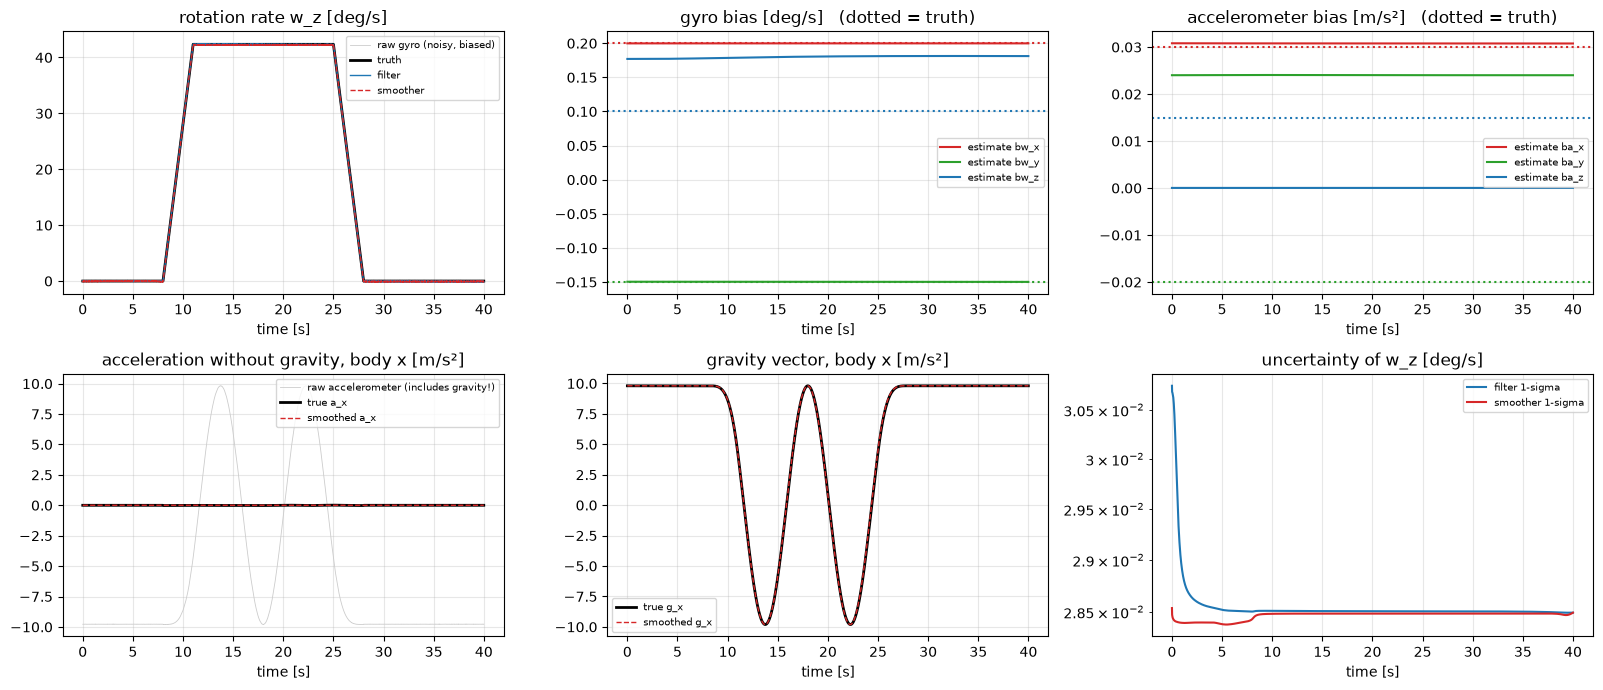

RMS error of the rotation rate w  [deg/s]:  raw gyro 0.158 | filter 0.041 | smoother 0.057
RMS error of the acceleration a [m/s^2]:   raw acc 0.0228 | filter 0.0071 | smoother 0.0077

BIASES  (estimate = filter value at the end of the run; compare with the secret truth)
  gyro  bias [deg/s]   estimate [ 0.2   -0.15   0.181]   truth [ 0.2  -0.15  0.1 ]
  accel bias [m/s^2]   estimate [0.0308 0.024  0.    ]   truth [ 0.03  -0.02   0.015]
  -> axes perpendicular to gravity are not separable from a small tilt of gravity (see text below)


In [14]:
# ======================= how good is it?  compare with the secret truth =======================
t = truth["t"]
fig, ax = plt.subplots(2, 3, figsize=(16, 7))

# (1) rotation rate about the body z axis: raw gyro vs filter vs smoother vs truth
ax[0, 0].plot(t, np.rad2deg(gyro1[:, 2]), color="0.8", lw=0.6, label="raw gyro (noisy, biased)")
ax[0, 0].plot(t, np.rad2deg(truth["wB"][:, 2]), "k", lw=2, label="truth")
ax[0, 0].plot(t, np.rad2deg(xf[:, 5]), "tab:blue", lw=1, label="filter")
ax[0, 0].plot(t, np.rad2deg(xs[:, 5]), "tab:red", lw=1, ls="--", label="smoother")
ax[0, 0].set_title("rotation rate w_z [deg/s]"); ax[0, 0].legend(fontsize=7)

# (2) gyro bias estimate converging to the true bias
for j, c in enumerate(("tab:red", "tab:green", "tab:blue")):
    ax[0, 1].plot(t, np.rad2deg(xs[:, 9 + j]), color=c, label=f"estimate bw_{'xyz'[j]}")
    ax[0, 1].axhline(np.rad2deg(bias_w_true[j]), color=c, ls=":")
ax[0, 1].set_title("gyro bias [deg/s]   (dotted = truth)"); ax[0, 1].legend(fontsize=7)

# (3) accelerometer bias estimate
for j, c in enumerate(("tab:red", "tab:green", "tab:blue")):
    ax[0, 2].plot(t, xs[:, 6 + j], color=c, label=f"estimate ba_{'xyz'[j]}")
    ax[0, 2].axhline(bias_a_true[j], color=c, ls=":")
ax[0, 2].set_title("accelerometer bias [m/s²]   (dotted = truth)"); ax[0, 2].legend(fontsize=7)

# (4) true acceleration a (body x) estimated
ax[1, 0].plot(t, acc1[:, 0], color="0.8", lw=0.6, label="raw accelerometer (includes gravity!)")
ax[1, 0].plot(t, truth["aB"][:, 0], "k", lw=2, label="true a_x")
ax[1, 0].plot(t, xs[:, 0], "tab:red", lw=1, ls="--", label="smoothed a_x")
ax[1, 0].set_title("acceleration without gravity, body x [m/s²]"); ax[1, 0].legend(fontsize=7)

# (5) gravity estimate vs truth (body x)
ax[1, 1].plot(t, truth["gB"][:, 0], "k", lw=2, label="true g_x")
ax[1, 1].plot(t, xs[:, 12], "tab:red", lw=1, ls="--", label="smoothed g_x")
ax[1, 1].set_title("gravity vector, body x [m/s²]"); ax[1, 1].legend(fontsize=7)

# (6) uncertainty: smoothed 1-sigma of w_z shrinks vs filtered
ax[1, 2].semilogy(t, np.rad2deg(np.sqrt(np.array(out["Pf"])[:, 5, 5])), "tab:blue", label="filter 1-sigma")
ax[1, 2].semilogy(t, np.rad2deg(np.sqrt(Ps[:, 5, 5])), "tab:red", label="smoother 1-sigma")
ax[1, 2].set_title("uncertainty of w_z [deg/s]"); ax[1, 2].legend(fontsize=7)

for a in ax.ravel(): a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

rms = lambda e: float(np.sqrt(np.mean(np.sum(e ** 2, axis=1) / 3)))
print("RMS error of the rotation rate w  [deg/s]:  raw gyro %.3f | filter %.3f | smoother %.3f" % (
    np.rad2deg(rms(gyro1 - truth["wB"])), np.rad2deg(rms(xf[:, 3:6] - truth["wB"])), np.rad2deg(rms(xs[:, 3:6] - truth["wB"]))))
print("RMS error of the acceleration a [m/s^2]:   raw acc %.4f | filter %.4f | smoother %.4f" % (
    rms(acc1 - truth["acc_clean"]), rms(xf[:, 0:3] - truth["aB"]), rms(xs[:, 0:3] - truth["aB"])))
print("\nBIASES  (estimate = filter value at the end of the run; compare with the secret truth)")
print("  gyro  bias [deg/s]   estimate", np.rad2deg(xf[-1, 9:12]).round(3), "  truth", np.rad2deg(bias_w_true).round(3))
print("  accel bias [m/s^2]   estimate", xf[-1, 6:9].round(4), "  truth", bias_a_true)
print("  -> axes perpendicular to gravity are not separable from a small tilt of gravity (see text below)")

### 🔑 What we learn from the test drive (read this carefully — it is the honest picture)
* **Rotation rate and acceleration:** the filter removes most of the gyro/accelerometer error. The 42°/s plateau
  is kept (this is the effect of the dynamic safeguards in `make_cfg`), and gravity is separated from true acceleration.
* **Biases are only partly recovered.** Look at the two bias plots and the numbers above:
  * A bias *along the gravity direction* is observable (we know $\|\mathbf g\|=G_0$), so e.g. $b_{a,x}$ is found well.
  * A bias *perpendicular* to gravity is, at rest, **indistinguishable from a small tilt of gravity**
    (0.02 m/s² of bias looks the same as 0.12° of tilt). The start values (Section 4.8) therefore push it into the gravity
    direction, and the filter cannot separate the two afterwards.
  * We checked that even with **no noise and no biases** the filter ends with a small spurious bias on one axis: while the
    rotation speeds up, the model lags a little, and the leftover error is absorbed by the bias states. Biases are
    "shock absorbers" for everything the model does not capture. Their values should not be over-interpreted.
* **The smoother is not automatically better.** Biases hardly change in time, so the smoother simply copies the *end-of-run*
  bias estimate back to the start. If that final estimate is slightly off, the smoothed curves inherit a small offset
  (here the smoothed $\omega_z$ is a little *worse* than the filtered one, by about 0.04°/s). The smoother helps a lot
  for the fast, noisy states and can slightly hurt when a nearly-constant state is imperfect.
* What matters for the rest of the pipeline is that the **rotation rate and the gravity direction** are accurate
  to a few hundredths of a degree per second — as the numbers above show.

One sensor is already decent. Four sensors, correctly combined, are better — but two tools are needed first: **how to merge several
estimates** (Chapter 6) and **how each sensor is mounted** relative to the others (Chapter 7).

# Chapter 6 — Merging several estimates: information fusion

### 🧠 Intuition
Four friends each estimate the weight of a cake. One is a baker (very precise), three are guessing. You do not take the
plain average: you listen **more to the baker**. The weight you give to each friend is their **precision** =
1 / uncertainty. That is the whole idea; the only novelty is that for our sensors the "uncertainty" is a **matrix**
(it can be large in one direction and tiny in another, and directions can be linked).

### 📐 Formula
Sensor $i$ gives an estimate $\mathbf y_i$ with covariance $P_i$ (of the *same* physical quantity). Define the
**information (precision) matrix** $\Lambda_i=P_i^{-1}$. Then, assuming independent errors,

$$
\Lambda_f=\sum_i\Lambda_i,\qquad P_f=\Lambda_f^{-1},\qquad
\mathbf y_f=P_f\sum_i\Lambda_i\,\mathbf y_i .
$$

* For one number this is the familiar *inverse-variance weighted mean*: $y_f=\dfrac{\sum y_i/\sigma_i^2}{\sum 1/\sigma_i^2}$.
* $P_f$ is **smaller** than every $P_i$: merging never makes us less sure.
* With $N$ equally good sensors the fused standard deviation is $\sigma/\sqrt N$.

### ⚠️ Why we need a *safe* matrix inverse
Covariances can have directions in which we are almost perfectly sure (an eigenvalue near 0). A naïve inverse would
blow up. `psd_inverse` (PSD = *positive semi-definite*, the mathematical name of a valid covariance) first rescales
the matrix to a **correlation matrix** (entries in −1…1), floors tiny eigenvalues at $10^{-10}$, inverts, and rescales
back. It works on *batches*: thousands of matrices at once.

In [15]:
def psd_inverse(P, eig_floor=EIG_FLOOR):
    """Stable inverse of (batches of) approximately-PSD covariances, shape (...,d,d)."""
    # Make sure P is an array of decimal numbers (a stack of square matrices).
    P = np.asarray(P, float)
    # Symmetrise: a covariance must equal its own transpose.
    P = 0.5 * (P + np.swapaxes(P, -1, -2))
    # s = standard deviations (square roots of the diagonal; never exactly zero).
    s = np.sqrt(np.maximum(np.diagonal(P, axis1=-2, axis2=-1), 1e-300))
    # S[i][j] = s_i * s_j : the scaling matrix.
    S = s[..., :, None] * s[..., None, :]
    # Cm = correlation matrix = P divided element-wise by S (entries between -1 and 1).
    Cm = P / S
    # Eigen-decomposition: directions V and their strengths ev.
    ev, V = np.linalg.eigh(0.5 * (Cm + np.swapaxes(Cm, -1, -2)))
    # Invert the correlation matrix, never dividing by anything smaller than eig_floor.
    Ci = (V / np.maximum(ev, eig_floor)[..., None, :]) @ np.swapaxes(V, -1, -2)
    # Scale back: the inverse of the original covariance.
    return Ci / S

In [16]:
def fuse_information(Y, P, chunk=20000):
    """Full covariance-weighted information fusion, sample by sample (batched).
    Y: (m,n,d) estimates of m sensors, P: (m,n,d,d) covariances."""
    # Y holds the estimates (m sensors x n instants x d numbers); P the covariances.
    Y = np.asarray(Y, float)
    P = np.asarray(P, float)
    # m = number of sensors, n = number of instants, d = size of the estimated vector.
    m, n, d = Y.shape
    # Space for the results: fused estimates and fused covariances.
    yf = np.empty((n, d)); Pf = np.empty((n, d, d))
    # Process the instants in chunks, to limit memory use.
    for i0 in range(0, n, chunk):
        # End of this chunk.
        i1 = min(n, i0 + chunk)
        # L = information (precision) matrix of every sensor at every instant:  Lambda_i = P_i^-1.
        L = psd_inverse(P[:, i0:i1])                       # (m,c,d,d)
        # Fused covariance:  P_f = (sum of the Lambda_i)^-1.
        Pk = psd_inverse(L.sum(axis=0))                    # (c,d,d)
        # b = sum over sensors of  Lambda_i * y_i.
        bvec = np.einsum("mnij,mnj->ni", L, Y[:, i0:i1])
        # Fused estimate:  y_f = P_f b.
        yf[i0:i1] = np.einsum("nij,nj->ni", Pk, bvec)
        # Store the (symmetrised) fused covariance.
        Pf[i0:i1] = 0.5 * (Pk + np.swapaxes(Pk, -1, -2))
    # Return the fused estimates and their covariances.
    return yf, Pf

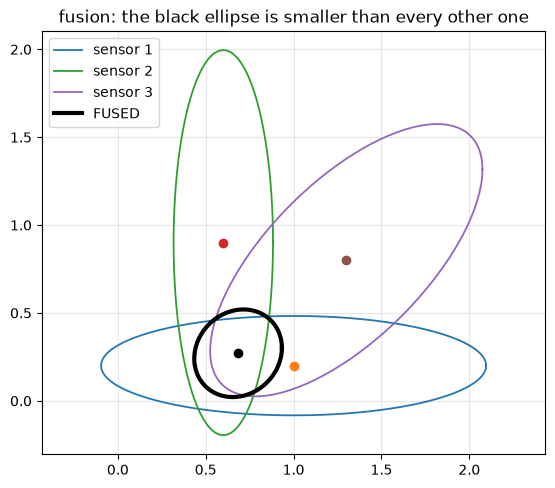

fused estimate: [0.684 0.271]
single sensor error std = 0.996;  fused error std = 0.503  (theory 1/sqrt(4) = 0.5)


In [17]:
# ======================= Chapter 6 demo: fuse three 2-D estimates with different uncertainty ellipses ===========
def ellipse(mean, P, k=2.0):
    # Points of the k-sigma uncertainty ellipse of a 2-D estimate (mean, covariance P) for drawing.
    th = np.linspace(0, 2 * np.pi, 200)
    L = np.linalg.cholesky(P)                           # 'square root' of the covariance matrix
    return mean[:, None] + k * L @ np.vstack([np.cos(th), np.sin(th)])

means = [np.array([1.0, 0.2]), np.array([0.6, 0.9]), np.array([1.3, 0.8])]       # three estimates of the same 2-D quantity
covs  = [np.array([[0.30, 0.00], [0.00, 0.02]]),         # sensor 1: precise in y, vague in x
         np.array([[0.02, 0.00], [0.00, 0.30]]),         # sensor 2: precise in x, vague in y
         np.array([[0.15, 0.10], [0.10, 0.15]])]         # sensor 3: uncertainty tilted (x and y errors linked)

Y = np.stack([m[None, :] for m in means])                # shape (3 sensors, 1 instant, 2 numbers)
P = np.stack([c[None, :, :] for c in covs])              # shape (3, 1, 2, 2)
yf, Pf = fuse_information(Y, P)                          # <- the project's fusion function

plt.figure(figsize=(6.5, 5.5))
for i, (m, c) in enumerate(zip(means, covs)):
    e = ellipse(m, c); plt.plot(e[0], e[1], lw=1.3, label=f"sensor {i+1}"); plt.plot(*m, "o")
e = ellipse(yf[0], Pf[0]); plt.plot(e[0], e[1], "k", lw=3, label="FUSED"); plt.plot(*yf[0], "ko")
plt.axis("equal"); plt.grid(alpha=0.3); plt.legend(); plt.title("fusion: the black ellipse is smaller than every other one")
plt.show()
print("fused estimate:", yf[0].round(3))

# Monte-Carlo check of the 1/sqrt(N) rule: 4 equal sensors with noise std 1
rng = np.random.default_rng(0)
truth_val = 5.0
Ys = truth_val + rng.standard_normal((4, 20000, 1))      # 4 sensors, 20000 independent trials
Ps = np.ones((4, 20000, 1, 1))                           # each sensor has variance 1
yf2, _ = fuse_information(Ys, Ps)
print(f"single sensor error std = {Ys[0].std():.3f};  fused error std = {yf2.std():.3f}  (theory 1/sqrt(4) = 0.5)")

# Chapter 7 — Registration: how is each sensor mounted? (the Wahba problem)

### 🧠 Intuition
The four IMUs are glued to the same object, but **not with the same orientation**: sensor 2's "x" arrow may point where
sensor 1's "y" arrow points. Before we can merge their numbers we must rotate each sensor's axes into a **common frame**.
We choose sensor 1's axes as that common ("reference body") frame.

Both the gravity vector and the rotation-rate vector are *physical arrows* that all sensors see — only expressed in
different axes. So for sensor $i$ there is one fixed rotation $C_i$ with

$$
\mathbf v^{(s1)}_k \;=\; C_i\,\mathbf v^{(i)}_k\qquad\text{for both }\mathbf v=\mathbf g\text{ and }\mathbf v=\boldsymbol\omega,\ \text{at every instant }k .
$$

Finding the rotation that best maps one set of arrows onto another is a classical problem named after Grace Wahba (1965).

### 📐 Formula
**Classical Wahba (weighted).** Minimise $\sum_k w_k\,\|\mathbf t_k-C\mathbf s_k\|^2$ over rotations $C$.
Build $H=\sum_k w_k\,\mathbf t_k\mathbf s_k^{\mathsf T}$, take its SVD $H=U\Sigma V^{\mathsf T}$, then
$C=U\,\mathrm{diag}(1,1,\det(UV^{\mathsf T}))\,V^{\mathsf T}$. The `det` guarantees a proper rotation, not a mirror image.
The project uses this **only as a starting guess** (`weighted_wahba_init`).

**Covariance-weighted version (what the project actually solves).** At each instant stack
$\mathbf y=[\mathbf g;\boldsymbol\omega]$ (6 numbers) with its full $6\times6$ covariance (including the g–ω
cross terms, from the smoother). With $B(C)=\mathrm{diag}(C,C)$:

$$
\min_C\ \sum_k \mathbf r_k^{\mathsf T}\Sigma_k^{-1}\mathbf r_k,\qquad
\mathbf r_k=\mathbf y^{\text{ref}}_k-B(C)\,\mathbf y^{\text{src}}_k,\qquad
\Sigma_k=P^{\text{ref}}_k+B(C)\,P^{\text{src}}_k\,B(C)^{\mathsf T}.
$$

*Reading:* a residual counts **a lot** when the combined uncertainty $\Sigma_k$ is small and **little** when it is large.
So a gyro sample while the sensor is still (rate ≈ noise) automatically has almost no say — no ad-hoc rule needed.

**Solving it (Gauss–Newton on rotations).** Write the update as $C\leftarrow\mathrm{Exp}(\boldsymbol\delta)\,C$ with a small rotation
vector $\boldsymbol\delta$. Then $\mathbf r(\boldsymbol\delta)\approx\mathbf r_0+A\boldsymbol\delta$ with
$A=\big[[\,C\mathbf s_g\,]_\times;\ [\,C\mathbf s_\omega\,]_\times\big]$, and the best step is
$$
H_{\!\text{info}}=\sum_k A_k^{\mathsf T}\Sigma_k^{-1}A_k,\qquad
\mathbf b=\sum_k A_k^{\mathsf T}\Sigma_k^{-1}\mathbf r_k,\qquad
\boldsymbol\delta=-H_{\!\text{info}}^{+}\,\mathbf b .
$$
($^+$ = pseudo-inverse: directions with no information are simply left alone.) We repeat, re-evaluating $\Sigma_k$ each time.
The final $H_{\!\text{info}}$ is also useful: $H_{\!\text{info}}^{-1}$ is the **uncertainty of the registration** (printed by the program).

### Why both gravity AND rotation rate?
Gravity points along Earth's vertical. If sensor 2 differs from sensor 1 only by a **turn about the vertical**, the gravity
vector is *identical* in both: gravity cannot tell this turn. The rotating-motion vectors $\boldsymbol\omega$ can.
The experiment below makes this concrete.

### Leave-one-out refinement and the consensus
With $\ge3$ sensors, each sensor $i$ is re-registered against the **fused estimate of all the *other* sensors** (so no
sensor helps define its own target, and sensor 1's noise is not the only reference). Finally the *consensus* is the
information-fused $[\mathbf g,\boldsymbol\omega]$ of all sensors, expressed in sensor 1's axes, and $\mathbf g$ is rescaled to length $G_0$.

In [18]:
def normalize(v, eps=1e-15):
    # Make sure v is an array of decimal numbers.
    v = np.asarray(v, float)
    # n = length of the vector.
    n = np.linalg.norm(v)
    # Divide by the length so the result has length 1 (a pure direction); `eps` avoids dividing by zero.
    return v / max(n, eps)

In [19]:
def exp_so3(phi):
    # Rotation vector (axis x angle) -> 3x3 rotation matrix. Same as Chapter 2.
    return Rot.from_rotvec(np.asarray(phi, float)).as_matrix()

In [20]:
def skew_batch(v):
    # Same as `skew`, but for n vectors at the same time.
    # v is a list of n 3-vectors (shape n x 3).
    v = np.asarray(v, float)
    # Prepare n empty 3x3 matrices.
    Z = np.zeros((len(v), 3, 3))
    # Fill every matrix with the cross-product pattern of Chapter 2 (all n at once = fast).
    Z[:, 0, 1] = -v[:, 2]; Z[:, 0, 2] = v[:, 1]
    Z[:, 1, 0] = v[:, 2];  Z[:, 1, 2] = -v[:, 0]
    Z[:, 2, 0] = -v[:, 1]; Z[:, 2, 1] = v[:, 0]
    return Z

In [21]:
def bd2(C):
    # The 6x6 'block-diagonal' matrix diag(C, C): the same rotation C acts on g (first 3) and on w (last 3); no mixing between them.
    M = np.zeros((6, 6)); M[:3, :3] = C; M[3:, 3:] = C
    return M

In [22]:
GW_IDX = np.r_[SL["g"].start:SL["g"].stop, SL["w"].start:SL["w"].stop]   # positions of [g(3), w(3)] inside the 15-vector
print("positions of g and w in the 15-state:", GW_IDX)

positions of g and w in the 15-state: [12 13 14  3  4  5]


In [23]:
def gw_blocks(x, P):
    """Joint [g, w] estimate (n,6) and full 6x6 covariance (n,6,6) of one IMU,
    including the g-w cross-covariance, taken from the smoothed 15-state."""
    # Pick out the 6 numbers [g, w] of every instant, and the full 6x6 block of the covariance (keeps the g-w links).
    return x[:, GW_IDX], P[:, GW_IDX[:, None], GW_IDX[None, :]]

In [24]:
def map_gw(y, P, C):
    """Rotate both 3-blocks of [g,w] by C and propagate the 6x6 covariance."""
    # Build diag(C, C).
    B = bd2(C)
    # Rotate the means (rows are instants, hence the transpose) and transform the covariance:  B P B^T.
    return y @ B.T, B @ P @ B.T

In [25]:
def _pinv_solve(H, b, rel=1e-10):
    # Solves H x = b while ignoring directions that carry no information.
    # Eigen-decomposition of the information matrix: directions V, strengths ev.
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    # No information at all -> do nothing.
    if ev.max() <= 0.0:
        return np.zeros(3)
    # Keep only directions with real information (ignore the numerically-zero ones).
    keep = ev > rel * ev.max()
    # Solve H x = b using only those directions (pseudo-inverse).
    return V[:, keep] @ ((V[:, keep].T @ b) / ev[keep])

In [26]:
def weighted_wahba_init(T, PT, S, PS):
    """Classical weighted Wahba (Markley SVD) with scalar weights derived from
    the estimate covariances.  Used only to initialise the full-covariance
    Gauss-Newton refinement below.
        w_g = 1 / (mean tangential variance of g_t and g_s)
        w_w = 1 / (mean variance of w_t and w_s)
    so a gyro sample with |w| << sigma_w automatically gets (almost) no say,
    and no ad-hoc factor / activity threshold is needed."""
    # Smallest allowed variance (avoid division by 0).
    tiny = 1e-30
    # Total variance of the gravity pair (reference + source) at each instant...
    trg = np.trace(PT[:, :3, :3], axis1=1, axis2=2) + np.trace(PS[:, :3, :3], axis1=1, axis2=2)
    # ...and of the angular-rate pair.
    trw = np.trace(PT[:, 3:, 3:], axis1=1, axis2=2) + np.trace(PS[:, 3:, 3:], axis1=1, axis2=2)
    # Weights = 1 / typical variance: precise instants count more.
    wg = 1.0 / np.maximum(trg / 2.0, tiny)
    # (same for the gyro part).
    ww = 1.0 / np.maximum(trw / 3.0, tiny)
    # H = sum of weight * (target arrow) (source arrow)^T, for gravity and for rate.
    H = (np.einsum("n,ni,nj->ij", wg, T[:, :3], S[:, :3])
         + np.einsum("n,ni,nj->ij", ww, T[:, 3:], S[:, 3:]))
    # Singular value decomposition of H.
    U, _, Vt = np.linalg.svd(H)
    # Force a proper rotation (determinant +1), not a mirror.
    D = np.eye(3); D[-1, -1] = np.linalg.det(U @ Vt)
    # The rotation that best aligns the arrows: this is only the STARTING GUESS.
    return U @ D @ Vt

In [27]:
def weighted_wahba(T, PT, S, PS, C0, max_iter=15, tol=1e-10):
    """Covariance-weighted Wahba problem on SO(3), joint over gravity and
    angular rate:

        min_C  sum_k  r_k^T Sigma_k^{-1} r_k ,
        r_k     = [g_t - C g_s ; w_t - C w_s]_k
        Sigma_k = P_t,k + B(C) P_s,k B(C)^T       (full 6x6, incl. g-w cross terms)

    Solved by Gauss-Newton with C <- exp([d]x) C and Sigma re-evaluated at the
    current C (iteratively reweighted).  Returns C and the 3x3 information
    matrix H (H^-1 = covariance of the small-angle registration error)."""
    # Start from the initial guess C0.
    C = np.array(C0, float)
    # H will hold the information matrix (how well each rotation direction is determined).
    H = np.zeros((3, 3))
    # Repeat (at most max_iter times): linearise, solve, update.
    for _ in range(max_iter):
        # Rotate the source estimates (and covariances) with the current C.
        CS, PSr = map_gw(S, PS, C)
        # W = Sigma^-1 : the weights (inverse of the combined uncertainty).
        W = psd_inverse(PT + PSr)
        # Residuals: target minus rotated source (ideally zero).
        r = T - CS
        # A = how the residual changes for a small extra rotation (cross-product matrices of the rotated arrows).
        A = np.concatenate([skew_batch(CS[:, :3]), skew_batch(CS[:, 3:])], axis=1)  # r(d) = r0 + A d
        # Weighted version of A.
        WA = W @ A
        # Information matrix  H = sum A^T W A.
        H = np.einsum("mia,mib->ab", A, WA)
        # Right-hand side  b = sum A^T W r.
        b = np.einsum("mia,mi->a", WA, r)
        # Best small rotation vector (Gauss-Newton step).
        step = -_pinv_solve(H, b)
        # Apply it: C <- Exp(step) C  (a rotation composed with a rotation: stays a rotation).
        C = exp_so3(step) @ C
        # Stop when the step has become negligible (converged).
        if np.linalg.norm(step) < tol:
            break
    # Return the registration rotation and its information matrix.
    return C, H

In [28]:
def registration_stats(H):
    # Eigen-decomposition of the information matrix.
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    # Directions that are really determined.
    keep = ev > 1e-10 * max(ev.max(), 1e-300)
    # Covariance of the small registration angle = pseudo-inverse of H.
    cov = (V[:, keep] / ev[keep]) @ V[:, keep].T if keep.any() else np.full((3, 3), np.inf)
    # Uncertainty (1 sigma, degrees) of the WEAKEST direction: infinity if one direction is not determined at all.
    smax = np.rad2deg(1.0 / np.sqrt(ev[0])) if ev[0] > 1e-10 * max(ev.max(), 1e-300) else np.inf
    # Package the diagnostics: per-axis 1-sigma in degrees, and the worst direction.
    return {"H": H, "cov": cov,
            "sigma_deg": np.rad2deg(np.sqrt(np.maximum(np.diag(cov), 0.0))),
            "sigma_max_deg": float(smax)}

In [29]:
def register_sensors(xs_by_sensor, Ps_by_sensor, sensors, stride=REGISTRATION_STRIDE,
                     active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS, refine_iters=2):
    """Covariance-weighted registration of every IMU to the s1 body frame.

    1) each sensor vs s1: weighted-SVD initial guess + full-covariance
       Gauss-Newton on the joint [g, w] residual;
    2) (N>=3) Gauss-Seidel refinement: each sensor is re-registered against the
       information-fused [g, w] of ALL OTHER sensors (leave-one-out, so a sensor
       never helps define its own target and s1 noise is not the sole reference).
    s1 stays the gauge: C_s1 = I.
    `active_mask` is only a diagnostic (inverse-variance-weighted mean of |w|);
    it no longer selects samples, the covariances do the weighting."""
    # Sensor 1 defines the common (reference body) frame.
    ref = sensors[0]
    # Number of samples.
    n = len(xs_by_sensor[ref])
    # Use only every `stride`-th sample (fast; neighbouring samples are nearly identical anyway).
    ids = np.arange(n)[::max(1, int(stride))]
    # ...but if that leaves too few samples, use all of them.
    if len(ids) < 10:
        ids = np.arange(n)
    # For every sensor collect the 6-vector [g, w] and its 6x6 covariance at those samples.
    Y, P = {}, {}
    # (loop over the sensors)
    for s in sensors:
        Y[s], P[s] = gw_blocks(xs_by_sensor[s][ids], Ps_by_sensor[s][ids])

    # Size of the angular rate of every sensor at every sample...
    wn = np.stack([np.linalg.norm(xs_by_sensor[s][:, SL["w"]], axis=1) for s in sensors])
    # ...and its variance.
    wv = np.stack([np.trace(Ps_by_sensor[s][:, SL["w"], SL["w"]], axis1=1, axis2=2) / 3.0 for s in sensors])
    # Inverse-variance weights.
    wt = 1.0 / np.maximum(wv, 1e-30)
    # Diagnostic only: mark the samples where the object is really rotating (precision-weighted mean rate above the threshold).
    mask = ((wt * wn).sum(0) / wt.sum(0)) > np.deg2rad(active_thr_dps)
    # If there is hardly any rotation, mark everything.
    if mask.sum() < 10:
        mask[:] = True

    # Reference sensor: identity rotation (it IS the reference frame).
    C = {ref: np.eye(3)}
    # Information matrices of the registrations.
    Hs = {}
    # STEP 1: register every other sensor directly against sensor 1...
    for s in sensors[1:]:
        # ...first the quick classical answer (SVD)...
        C0 = weighted_wahba_init(Y[ref], P[ref], Y[s], P[s])
        # ...then refine it with the covariance-weighted Gauss-Newton method.
        C[s], Hs[s] = weighted_wahba(Y[ref], P[ref], Y[s], P[s], C0)

    # STEP 2 (3 or more sensors): leave-one-out refinement, repeated `refine_iters` times.
    if len(sensors) >= 3 and refine_iters > 0:
        # (sweeps)
        for _ in range(int(refine_iters)):
            # For each sensor s ...
            for s in sensors[1:]:
                # ...collect the OTHER sensors' estimates, rotated into sensor 1's axes...
                ys, Pl = [], []
                # (loop over the others)
                for o in sensors:
                    if o == s:
                        continue
                    # Rotate sensor o's [g, w] and covariance with its current registration.
                    yo, Po = map_gw(Y[o], P[o], C[o])
                    ys.append(yo); Pl.append(Po)
                # ...fuse them (Chapter 6) into one better target...
                Tf, PTf = fuse_information(np.stack(ys), np.stack(Pl))
                # ...and re-register sensor s against that fused target.
                C[s], Hs[s] = weighted_wahba(Tf, PTf, Y[s], P[s], C[s])

    # Registration uncertainty report (the reference has none: it is exact by definition).
    stats = {ref: {"H": np.zeros((3, 3)), "cov": np.zeros((3, 3)),
                   "sigma_deg": np.zeros(3), "sigma_max_deg": 0.0}}
    # For every other sensor...
    for s in sensors[1:]:
        # ...compute the uncertainty of its registration...
        stats[s] = registration_stats(Hs[s])
        # ...and warn if some direction is poorly determined (e.g. no rotation excited the yaw).
        if stats[s]["sigma_max_deg"] > 1.0:
            warnings.warn(
                f"Registration for {s}: weakest direction has 1-sigma = "
                f"{stats[s]['sigma_max_deg']:.3g} deg (insufficient tilt/rotation "
                f"excitation; relative yaw may be ambiguous)."
            )
    # Return the rotations C, the activity mask and the statistics.
    return C, mask, stats

In [30]:
def consensus_body_history(xs_by_sensor, Ps_by_sensor, C, sensors, chunk=20000):
    """Covariance-weighted (information-form) consensus of [g, w] in the s1
    body frame at every sample, using each IMU's full 6x6 smoothed covariance
    mapped through its registration C_s.  Replaces the previous median.
    g is renormalised to G0 afterwards (only its direction is used)."""
    # Number of samples.
    n = len(xs_by_sensor[sensors[0]])
    # Space for the fused gravity, fused rate and fused covariance of every sample.
    g = np.empty((n, 3)); w = np.empty((n, 3)); Pc = np.empty((n, 6, 6))
    # Work through the samples in chunks (memory).
    for i0 in range(0, n, chunk):
        # End of this chunk.
        i1 = min(n, i0 + chunk)
        # Collect every sensor's [g, w] in sensor 1's axes...
        ys, Pl = [], []
        # (loop over sensors)
        for s in sensors:
            # Take the sensor's smoothed [g, w] and covariance...
            y, Pm = gw_blocks(xs_by_sensor[s][i0:i1], Ps_by_sensor[s][i0:i1])
            # ...rotate them into sensor 1's axes with its registration C...
            y, Pm = map_gw(y, Pm, C[s])
            # ...and store.
            ys.append(y); Pl.append(Pm)
        # Fuse all sensors (Chapter 6): one consensus [g, w] per instant.
        yf, Pf = fuse_information(np.stack(ys), np.stack(Pl))
        # Length of the fused gravity vector.
        gn = np.linalg.norm(yf[:, :3], axis=1, keepdims=True)
        # Keep only its DIRECTION and give it the exact length G0.
        g[i0:i1] = yf[:, :3] / np.maximum(gn, 1e-15) * G0
        # Fused angular rate (body axes of sensor 1).
        w[i0:i1] = yf[:, 3:]
        # Fused covariance.
        Pc[i0:i1] = Pf
    # Return consensus gravity, rate and covariance.
    return g, w, Pc

gravity only   : error vs truth =  24.917 deg   |  1-sigma per axis [deg] = [0.01  0.01  3.284]   weakest direction = 3.28 deg
gravity + gyro : error vs truth =   0.057 deg   |  1-sigma per axis [deg] = [0.009 0.009 0.052]   weakest direction = 0.0519 deg


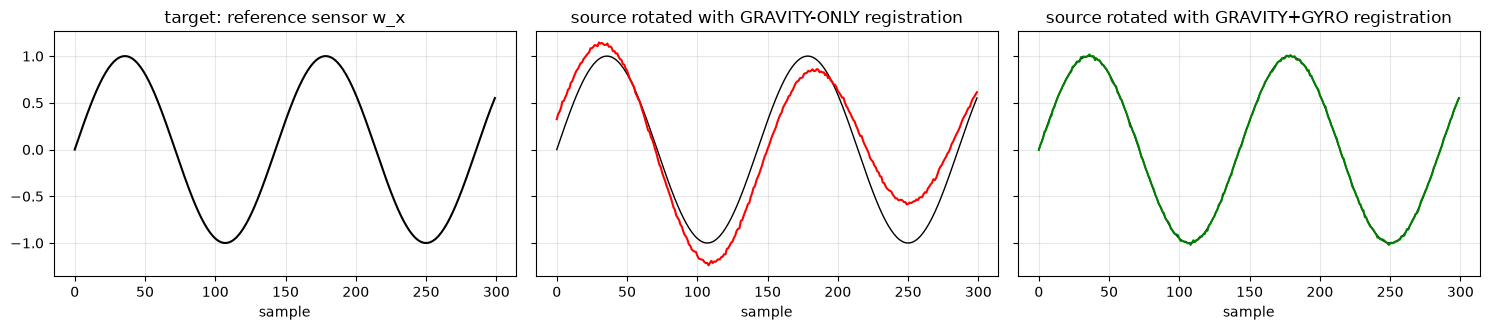

In [31]:
# ======================= Chapter 7 demo: why gravity alone cannot register a turn about the vertical ===============
rng = np.random.default_rng(7)
n = 300; tt = np.arange(n) / 100.0
C_true = Rot.from_euler("z", 55.0, degrees=True).as_matrix()      # secret mounting: sensor 2 is turned 55 deg about the vertical

# What the REFERENCE sensor sees: gravity constant (sensor tilted still), rotation rate wandering in 3-D.
g_ref = np.tile([0.0, 0.0, -G0], (n, 1))
w_ref = np.column_stack([1.0 * np.sin(2 * np.pi * 0.7 * tt), 0.8 * np.cos(2 * np.pi * 0.4 * tt), 0.5 * np.sin(2 * np.pi * 0.2 * tt + 1)])
sg, sw = 0.02, 0.01                                               # noise std of the g and w estimates

T = np.hstack([g_ref + sg * rng.standard_normal((n, 3)), w_ref + sw * rng.standard_normal((n, 3))])          # reference [g, w]
S = np.hstack([g_ref @ C_true + sg * rng.standard_normal((n, 3)), w_ref @ C_true + sw * rng.standard_normal((n, 3))])  # source sensor, in ITS axes
PT = np.tile(np.diag([sg**2] * 3 + [sw**2] * 3), (n, 1, 1))       # covariances (diagonal here)
PS = PT.copy()

def registration_error(C):
    return np.rad2deg(np.linalg.norm(Rot.from_matrix(C.T @ C_true).as_rotvec()))   # angle between C and the truth

# (a) GRAVITY ONLY: tell the solver the gyro is useless by giving it a gigantic variance
PT_g, PS_g = PT.copy(), PS.copy()
PT_g[:, 3:, 3:] *= 1e12; PS_g[:, 3:, 3:] *= 1e12
C0 = weighted_wahba_init(T, PT_g, S, PS_g); C_g, H_g = weighted_wahba(T, PT_g, S, PS_g, C0)
# (b) GRAVITY + GYRO (what the project does)
C0 = weighted_wahba_init(T, PT, S, PS);     C_j, H_j = weighted_wahba(T, PT, S, PS, C0)

for name, C, H in (("gravity only", C_g, H_g), ("gravity + gyro", C_j, H_j)):
    st = registration_stats(H)
    print(f"{name:15s}: error vs truth = {registration_error(C):7.3f} deg   |  1-sigma per axis [deg] = {np.round(st['sigma_deg'], 3)}   weakest direction = {st['sigma_max_deg']:.3g} deg")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
ax[0].plot(w_ref[:, 0], "k"); ax[0].set_title("target: reference sensor w_x")
ax[1].plot(w_ref[:, 0], "k", lw=1); ax[1].plot((S[:, 3:] @ C_g.T)[:, 0], "r"); ax[1].set_title("source rotated with GRAVITY-ONLY registration")
ax[2].plot(w_ref[:, 0], "k", lw=1); ax[2].plot((S[:, 3:] @ C_j.T)[:, 0], "g"); ax[2].set_title("source rotated with GRAVITY+GYRO registration")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("sample")
plt.tight_layout(); plt.show()

### 🔑 What we learn
* **Gravity only:** the registration is wrong by tens of degrees. The uncertainty report flags it: the weakest direction has a
  1-σ of a few degrees, about 60 times larger than with the gyro (gravity cannot see a turn about the vertical, and the near-singular problem
  also makes the answer unreliable beyond what the report says).
* **Gravity + gyro:** error well below one degree, and the reported uncertainty is small. The project's program
  prints a warning whenever the weakest direction exceeds 1° — meaning "your motion did not excite this
  direction; trust the registration less".
* In the real experiment the rotation about a horizontal axis (Earth Y) makes gravity itself move through the sensor
  frame, which already helps a lot; the gyro term then resolves the rest.

# Chapter 8 — Building the Earth-frame orientation and projecting everything to the Earth

So far every number is written in **body axes**. The goal is the **Earth frame** (X, Y horizontal, Z up).
We need the rotation $R_k$ (body → Earth) at *every instant $k$*. Where does it come from? Three ingredients:

**(1) Initial attitude from gravity** (`gravity_alignment_R`). At rest the accelerometer tells where "down" is in the sensor
axes. That fixes the **tilt** (roll and pitch) but **not the compass heading (yaw)**: turning the sensor about the vertical
does not change gravity. So we *choose* yaw = 0 at the start (a coordinate convention). With $\mathbf g=(g_x,g_y,g_z)/\|\mathbf g\|$:
$$
\text{pitch}=\operatorname{atan2}\!\big(g_x,\sqrt{g_y^2+g_z^2}\big),\quad
\text{roll}=\operatorname{atan2}(-g_y,-g_z),\quad
R_0=R_y(\text{pitch})\,R_x(\text{roll}),\quad R_0\,\hat{\mathbf g}=(0,0,-1).
$$

**(2) Integrate the rotation rate** (`integrate_orientation`). Orientation changes by the rotation rate:
$$
R_{k+1}=R_k\,\operatorname{Exp}\!\Big(\tfrac{\boldsymbol\omega_k+\boldsymbol\omega_{k+1}}{2}\,\Delta t\Big)
$$
(using the average of two consecutive rates is more accurate than using only one).
Problem: small rate errors accumulate, so the **tilt slowly drifts**.

**(3) Correct the tilt with gravity at every instant** (`gravity_corrected_orientation`). Since we also know the gravity direction
at every instant, we compare *predicted* gravity $R_k^{\mathsf T}(0,0,-1)$ with *measured* gravity and apply the **smallest rotation $D$**
that makes them agree: $R_k\leftarrow R_k D$. (`minimal_map` computes that smallest rotation: axis $\propto \mathbf u\times\mathbf v$,
angle $=\operatorname{atan2}(\|\mathbf u\times\mathbf v\|,\mathbf u\cdot\mathbf v)$.) The correction only moves the **tilt**; the **yaw** comes
purely from the gyro integration — which is exactly the physics: gravity knows tilt, only the gyro knows heading changes.

**Projection** (`project_earth_with_cov`). With the sensor's registration $C_i$ and $R_k$, any body vector $\mathbf x$ of sensor $i$ becomes
$\mathbf x_E=T_k\mathbf x$, $T_k=R_kC_i$. Its covariance transforms as $P_E=J P J^{\mathsf T}$ with $J=\operatorname{diag}(T_k,\dots,T_k)$
(five blocks: $a,\omega,b_a,b_\omega,g$). The result is stored as a 15-vector and a $15\times15$ covariance per instant.

In [32]:
def gravity_alignment_R(g_body):
    """Minimum-yaw body->Earth rotation with R*g = [0,0,-1]."""
    # Direction of gravity in the sensor's axes (length 1).
    g = normalize(g_body)
    # Its three components.
    gx, gy, gz = g
    # h = length of the (y, z) part.
    h = max(np.hypot(gy, gz), 1e-15)
    # Pitch: how far gravity leans out of the y-z plane.
    pitch = np.arctan2(gx, h)
    # Roll: the angle of gravity inside the y-z plane.
    roll = np.arctan2(-gy, -gz)
    # Cosines and sines needed to write the rotation matrices.
    cp, sp = np.cos(pitch), np.sin(pitch)
    cr, sr = np.cos(roll), np.sin(roll)
    # Rotation about y by `pitch`, and about x by `roll` (standard 3x3 matrices).
    Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
    Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
    # Combine: body -> Earth rotation with gravity pointing down and yaw = 0.
    return Ry @ Rx

In [33]:
def minimal_map(u, v):
    """Proper rotation C such that C @ u ~= v, with minimum angle."""
    # Work with pure directions.
    u = normalize(u); v = normalize(v)
    # c = cos(angle between u and v).
    c = float(np.clip(np.dot(u, v), -1.0, 1.0))
    # The rotation axis is perpendicular to both: u x v.
    a = np.cross(u, v)
    # s = sin(angle).
    s = np.linalg.norm(a)
    # Special case: u and v are parallel or opposite (no unique axis).
    if s < 1e-12:
        # Already aligned: no rotation needed.
        if c > 0.0:
            return np.eye(3)
        # Opposite directions: pick any axis perpendicular to u...
        ref = np.array([1., 0., 0.]) if abs(u[0]) < 0.9 else np.array([0., 1., 0.])
        # ...(the helper arrow `ref` just has to be not parallel to u)...
        axis = normalize(np.cross(u, ref))
        # ...and turn by 180 degrees.
        return exp_so3(np.pi * axis)
    # Normal case: unit rotation axis.
    axis = a / s
    # Rotate about it by the angle between u and v (the SMALLEST rotation taking u to v).
    return exp_so3(np.arctan2(s, c) * axis)

In [34]:
def integrate_orientation(w_body, R0, dt):
    # Number of samples.
    n = len(w_body)
    # A list of n rotation matrices; the first one is the starting attitude R0.
    R = np.empty((n, 3, 3)); R[0] = R0
    # Step through time.
    for k in range(n - 1):
        # Average rotation rate over this step (body axes).
        wm = 0.5 * (w_body[k] + w_body[k + 1])
        # Turn by (rate x time) about the body axes:  R_next = R Exp(w dt).
        R[k + 1] = R[k] @ exp_so3(wm * dt)
    # The orientation history.
    return R

In [35]:
def gravity_corrected_orientation(R_base, g_ref):
    """At each sample, use g_ref to correct tilt while preserving yaw."""
    # Number of samples.
    n = len(g_ref)
    # Space for the corrected orientations.
    R = np.empty_like(R_base)
    # Earth's 'down' direction.
    gE = np.array([0.0, 0.0, -1.0])
    # For every instant...
    for k in range(n):
        # ...the gravity direction the integrated orientation PREDICTS in body axes...
        g_pred_B = normalize(R_base[k].T @ gE)
        # ...the gravity direction actually MEASURED (consensus)...
        g_meas_B = normalize(g_ref[k])
        # ...the smallest rotation that fixes the mismatch (only tilt changes)...
        D = minimal_map(g_meas_B, g_pred_B)
        # ...applied to the orientation.
        R[k] = R_base[k] @ D
    # Tilt-corrected orientation history (yaw still comes only from the gyro).
    return R

In [36]:
def project_earth_with_cov(xs, Ps, C, R_hist, G0=G0):
    """Project [a,w,ba,bw,g] to Earth and propagate the conditional covariance.

    The returned covariance is exact for the linear transformation induced by
    the estimated registration C and the estimated orientation R_hist.  The
    covariance of R_hist itself is not included because it depends on the
    complete preceding trajectory (cross-time attitude uncertainty). Treating
    it as an instantaneous independent covariance would be misleading and
    would also make large batch runs unnecessarily expensive.
    """
    # Number of samples.
    n = len(xs)
    # Space for the Earth-frame 15-vectors and 15x15 covariances.
    y15 = np.empty((n, 15))
    P15 = np.empty((n, 15, 15))
    # (small cache list)
    Tcache = [None] * n
    # For every instant...
    for k in range(n):
        # T = (body -> Earth) x (this sensor -> reference body):  the full rotation of this sensor's vectors into Earth axes.
        T = R_hist[k] @ C
        Tcache[k] = T
        # Rotate each of the five 3-vectors: acceleration, rate, accelerometer bias, gyro bias, gravity.
        a = T @ xs[k, SL["a"]]
        w = T @ xs[k, SL["w"]]
        ba = T @ xs[k, SL["ba"]]
        bw = T @ xs[k, SL["bw"]]
        g = T @ xs[k, SL["g"]]
        # Stack them into one 15-vector.
        y15[k] = np.concatenate([a, w, ba, bw, g])

        # J = the 15x15 'rotate each block by T' matrix...
        J = np.zeros((15, N_X))
        # ...with T on the diagonal blocks.
        for r0 in (0, 3, 6, 9, 12):
            J[r0:r0+3, r0:r0+3] = T
        # Covariance rotates as  J P J^T.
        P15[k] = J @ Ps[k] @ J.T
        # Symmetrise.
        P15[k] = 0.5 * (P15[k] + P15[k].T)
    # Return Earth-frame states and covariances.
    return y15, P15

R0 times unit gravity = [ 0.  0. -1.]  (must be 0,0,-1)
convention yaw offset (rotation vector, deg): [-0. -0. 90.]


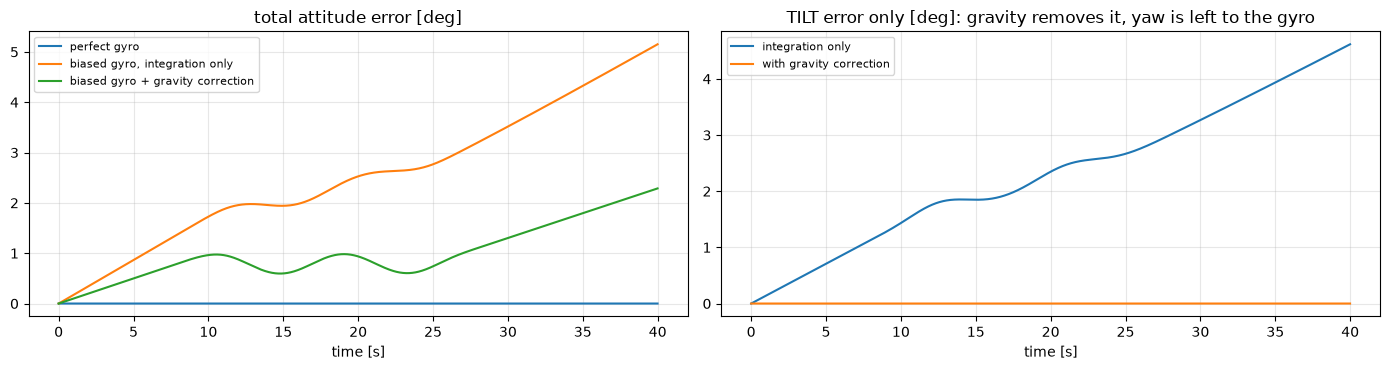

In [37]:
# ======================= Chapter 8 demo: initial attitude, integration drift, and gravity correction ===============
def geodesic_deg(Ra, Rb):
    # Angle (degrees) of the rotation that takes attitude Ra to attitude Rb (how different two orientations are).
    c = 0.5 * (np.einsum("nij,nij->n", Ra, Rb) - 1.0)
    return np.degrees(np.arccos(np.clip(c, -1.0, 1.0)))

dt = truth["dt"]; tt = truth["t"]
gB0 = truth["gB"][0]                                         # gravity as the (perfect) sensor sees it at t = 0
R0 = gravity_alignment_R(gB0)                                # initial attitude with yaw = 0
print("R0 times unit gravity =", np.round(R0 @ (gB0 / np.linalg.norm(gB0)), 6), " (must be 0,0,-1)")

# The true attitude and ours differ by a constant yaw (the 'yaw=0' convention): Y = R0 R_true(0)^T is a turn about Z.
Y = R0 @ truth["R"][0].T
print("convention yaw offset (rotation vector, deg):", np.round(np.rad2deg(Rot.from_matrix(Y).as_rotvec()), 3))
R_true_conv = np.einsum("ij,njk->nik", Y, truth["R"])         # the true attitude expressed in our yaw convention

# (a) integrate the PERFECT gyro: should follow the truth almost exactly
R_perfect = integrate_orientation(truth["wB"], R0, dt)
# (b) integrate a gyro with a small bias (0.1 deg/s on every axis): the attitude drifts
w_biased = truth["wB"] + np.deg2rad(0.1)
R_drift = integrate_orientation(w_biased, R0, dt)
# (c) same biased gyro, but correct the tilt with the (here: perfect) gravity measurement at every instant
R_fixed = gravity_corrected_orientation(R_drift, truth["gB"])

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(tt, geodesic_deg(R_perfect, R_true_conv), label="perfect gyro")
ax[0].plot(tt, geodesic_deg(R_drift, R_true_conv), label="biased gyro, integration only")
ax[0].plot(tt, geodesic_deg(R_fixed, R_true_conv), label="biased gyro + gravity correction")
ax[0].set_title("total attitude error [deg]"); ax[0].legend(fontsize=8)

def tilt_err(R):                                             # angle between predicted and true gravity direction (body axes)
    pred = np.einsum("nji,j->ni", R, [0, 0, -1.0])
    tru = truth["gB"] / np.linalg.norm(truth["gB"], axis=1, keepdims=True)
    return np.degrees(np.arccos(np.clip(np.einsum("ni,ni->n", pred, tru), -1, 1)))
ax[1].plot(tt, tilt_err(R_drift), label="integration only"); ax[1].plot(tt, tilt_err(R_fixed), label="with gravity correction")
ax[1].set_title("TILT error only [deg]: gravity removes it, yaw is left to the gyro"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

### 🔑 What we learn
* A perfect gyro integrates to the right attitude (apart from the arbitrary yaw offset we chose).
* A tiny gyro bias makes the attitude drift (left plot). Gravity *removes the tilt part* of the drift (right plot) but
  **cannot remove the yaw part** — the remaining error in the left plot is a slow heading drift. This is the fundamental
  limitation of any gravity-aided inertial system without a compass.

# Chapter 9 — A second smoother, then integration to velocity, position and angle

### 9.1 Fusing across sensors in the Earth frame
After projection every sensor has its own Earth-frame $[\mathbf a_E,\boldsymbol\omega_E]$ and covariance. They are merged at
every instant with `fuse_information` (Chapter 6). The first fused curves are labelled **"weighted fusion"** in the plots.

### 9.2 The optional second smoother (`second_rts_random_walk`)
The fused curve is still slightly jittery. A second, very simple smoother is run on the 6-vector $[\mathbf a_E,\boldsymbol\omega_E]$:

$$
\mathbf x_{k+1}=\mathbf x_k+\mathbf q_k\ \ (\text{random walk}),\qquad \mathbf y_k=\mathbf x_k+\mathbf v_k,
\qquad \operatorname{cov}(\mathbf v_k)=\rho\,P^{\text{fused}}_k,\quad \operatorname{cov}(\mathbf q_k)=\mu\,Q_k
$$

with $\rho=10$ (`r_inflation`: trust the fused data 10 times less than their nominal covariance) and $\mu=1$ (`q_scale`).
$Q_k$ is built by `fused_Q_from_individuals`: the adaptive process noises of the individual filters, rotated into Earth axes and averaged.
Then the *same* forward Kalman + backward RTS recursion as Chapters 3–4 is applied (here $F=I$, $H=I$).
⚠️ This is a **temporal regulariser**, not an exact second Bayesian smoother: the first smoother already made neighbouring
samples correlated, and those cross-time correlations are not stored. It is an engineering choice, which is why the
program shows *both* curves ("weighted fusion" and "+ second RTS").

### 9.3 Integration: from acceleration to position
Only now — after everything has been cleaned and fused — we integrate. The **trapezoid rule** adds the average of two consecutive values:
$$
\mathbf v_{k+1}=\mathbf v_k+\tfrac{\Delta t}{2}(\mathbf a_k+\mathbf a_{k+1}),\qquad
\mathbf p_{k+1}=\mathbf p_k+\tfrac{\Delta t}{2}(\mathbf v_k+\mathbf v_{k+1}),\qquad
R_{k+1}=\operatorname{Exp}\!\big(\tfrac{\boldsymbol\omega_k+\boldsymbol\omega_{k+1}}{2}\Delta t\big)\,R_k .
$$
Note the order $\operatorname{Exp}(\dots)\,R_k$ (rotation applied on the *left*): the rate is in **Earth** axes here.
The plotted `theta` is the **rotation vector** of $R_k$ (axis × angle), so it only reports angles between 0 and 180°: a 720° turn
shows up *wrapped*. To see the unwrapped 720° use the running sum of $\boldsymbol\omega_E\Delta t$ (this is what the GIFs plot).

In [38]:
def fused_Q_from_individuals(results, sensors):
    """Approximate fused process covariance for the final random-walk RTS."""
    # Number of samples.
    n = len(results[sensors[0]]["earth15"])
    # Space for one 6x6 process-noise matrix per instant.
    Q = np.zeros((n, 6, 6))
    # For every sensor...
    for s in sensors:
        # ...its stored results...
        r = results[s]
        # ...its adaptive process-noise history (body axes),
        q = r["qhist"]
        # ...its registration,
        C = r["C"]
        # ...and the orientation history.
        R = r["R_hist"]
        # Process noise of a and of w as 3x3 diagonal matrices (body axes).
        Qa_body = q[:, SL["a"], None] * np.eye(3)[None, :, :]
        # (same for w)
        Qw_body = q[:, SL["w"], None] * np.eye(3)[None, :, :]
        # For every instant...
        for k in range(n):
            # ...the rotation into Earth axes...
            T = R[k] @ C
            # ...rotate the noise matrices (T Q T^T) and add them: acceleration block...
            Q[k, :3, :3] += T @ Qa_body[k] @ T.T
            # ...and angular-rate block.
            Q[k, 3:, 3:] += T @ Qw_body[k] @ T.T
    # Divide by the number of sensors: the AVERAGE process noise.
    return Q / max(len(sensors), 1)

In [39]:
def second_rts_random_walk(y, P, Q, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE):
    """6-state H=I Kalman smoother with F=I random-walk dynamics."""
    # n instants, d = 6 numbers per instant (a_E and w_E).
    n, d = y.shape
    # Identity matrix.
    I = np.eye(d)
    # Measurement noise = fused covariance x r_inflation (trust the data less).
    Rm = max(float(r_inflation), 1e-12) * P
    # Process noise = Q x q_scale.
    Q = max(float(q_scale), 0.0) * Q

    # Space for the forward (filter) results.
    xf = np.empty_like(y); Pf = np.empty_like(P)
    xp = np.empty_like(y); Pp = np.empty_like(P)
    # Start from the first fused sample.
    x = y[0].copy(); Pc = P[0].copy()
    # Store the first step.
    xf[0], Pf[0], xp[0], Pp[0] = x, Pc, x, Pc

    # FORWARD pass: ordinary Kalman filter with F = I and H = I.
    for k in range(1, n):
        # Predict: the value stays the same (random walk)...
        xpred = x
        # ...and its uncertainty grows by Q.
        Ppred = Pc + Q[k]
        # Innovation covariance (H = I).
        S = Ppred + Rm[k]
        # Kalman gain.
        K = Ppred @ psd_inverse(S)
        # Update with the fused measurement.
        x = xpred + K @ (y[k] - xpred)
        # Joseph form of the covariance update.
        IK = I - K
        # New uncertainty.
        Pc = IK @ Ppred @ IK.T + K @ Rm[k] @ K.T
        # Symmetrise.
        Pc = 0.5 * (Pc + Pc.T)
        # Store everything the backward pass needs.
        xf[k], Pf[k], xp[k], Pp[k] = x, Pc, xpred, Ppred

    # BACKWARD pass (RTS): start from the filtered result.
    xs = xf.copy(); Ps = Pf.copy()
    # Walk backward in time.
    for k in range(n - 2, -1, -1):
        # Smoother gain.
        Ck = Pf[k] @ psd_inverse(Pp[k + 1])
        # Correct with the future.
        xs[k] = xf[k] + Ck @ (xs[k + 1] - xp[k + 1])
        # Smaller uncertainty.
        Ps[k] = Pf[k] + Ck @ (Ps[k + 1] - Pp[k + 1]) @ Ck.T
        # Symmetrise.
        Ps[k] = 0.5 * (Ps[k] + Ps[k].T)
    # Smoothed fused [a_E, w_E] and covariances.
    return xs, Ps

In [40]:
def integrate_navigation(aE, wE, dt):
    # Number of samples.
    n = len(aE)
    # Space for the orientation matrices, the angle vectors, velocity and position.
    R = np.empty((n, 3, 3)); theta = np.empty((n, 3))
    # Velocity and position start at zero (we only know RELATIVE motion).
    v = np.zeros((n, 3)); p = np.zeros((n, 3))
    # Orientation starts as 'no rotation yet'.
    R[0] = np.eye(3); theta[0] = 0.0
    # Step through time.
    for k in range(n - 1):
        # Average Earth-frame rotation rate over the step.
        wm = 0.5 * (wE[k] + wE[k + 1])
        # Rotate by (rate x time) about Earth axes (applied on the left).
        R[k + 1] = exp_so3(wm * dt) @ R[k]
        # theta = the accumulated rotation as a rotation vector (axis x angle; angles above 180 deg wrap).
        theta[k + 1] = Rot.from_matrix(R[k + 1]).as_rotvec()
        # Velocity: add the average acceleration x time (trapezoid rule).
        v[k + 1] = v[k] + 0.5 * dt * (aE[k] + aE[k + 1])
        # Position: add the average velocity x time.
        p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])
    # Package all results.
    return {
        "aE": aE, "wE": wE, "v": v, "p": p, "theta": theta,
        "R": R, "q_xyzw": Rot.from_matrix(R).as_quat(),
    }

In [41]:
def nav_from_projected(y15, dt):
    # Shortcut: take the first six columns [a_E, w_E] of an Earth-frame 15-state history and integrate them.
    return integrate_navigation(y15[:, :3], y15[:, 3:6], dt)

true final position  : [0. 0. 0.]
integrated position  : [0. 0. 0.]
rotation vector theta at the end [deg] (wrapped!): [0. 0. 0.]
unwrapped angle about Y (sum of w dt)     [deg]: 720.0  <- the 720 degrees


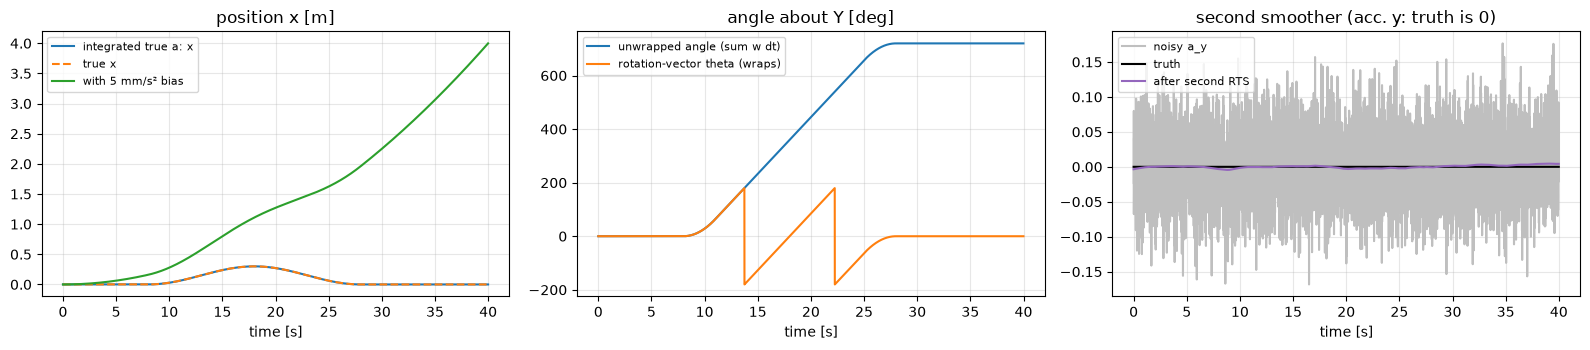

RMS error before smoothing 0.0500  after 0.0194


In [42]:
# ======================= Chapter 9 demos =======================
dt = truth["dt"]; tt = truth["t"]

# (1) integrate the TRUE Earth-frame acceleration and rotation rate: we should recover the true position and angle
nav_true = integrate_navigation(truth["aE"], truth["wE"], dt)
print("true final position  :", truth["pE"][-1].round(4))
print("integrated position  :", nav_true["p"][-1].round(4))
unwrapped = np.rad2deg(np.cumsum(truth["wE"], axis=0) * dt)
print("rotation vector theta at the end [deg] (wrapped!):", np.rad2deg(nav_true["theta"][-1]).round(2))
print("unwrapped angle about Y (sum of w dt)     [deg]:", unwrapped[-1].round(1)[1], " <- the 720 degrees")

# (2) the same integration with a tiny acceleration bias: position drifts like 0.5*b*t^2 (Chapter 1 again)
b = 0.005                                                # 5 mm/s^2 of leftover bias
nav_b = integrate_navigation(truth["aE"] + b, truth["wE"], dt)

# (3) the second smoother on a noisy fused-like signal
rng = np.random.default_rng(5)
sig = 0.05
y = np.hstack([truth["aE"], truth["wE"]]) + sig * rng.standard_normal((len(tt), 6))     # noisy 6-vector [a_E, w_E]
Pnoise = np.tile(sig**2 * np.eye(6), (len(tt), 1, 1))
Qproc = np.tile((1e-3) ** 2 * np.eye(6), (len(tt), 1, 1))
ys, _ = second_rts_random_walk(y, Pnoise, Qproc)         # uses r_inflation=10 and q_scale=1 by default

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(tt, nav_true["p"][:, 0], label="integrated true a: x"); ax[0].plot(tt, truth["pE"][:, 0], "--", label="true x")
ax[0].plot(tt, nav_b["p"][:, 0], label="with 5 mm/s² bias"); ax[0].set_title("position x [m]"); ax[0].legend(fontsize=8)
ax[1].plot(tt, unwrapped[:, 1], label="unwrapped angle (sum w dt)"); ax[1].plot(tt, np.rad2deg(nav_true["theta"][:, 1]), label="rotation-vector theta (wraps)")
ax[1].set_title("angle about Y [deg]"); ax[1].legend(fontsize=8)
ax[2].plot(tt, y[:, 1], color="0.75", label="noisy a_y"); ax[2].plot(tt, truth["aE"][:, 1], "k", label="truth"); ax[2].plot(tt, ys[:, 1], "tab:purple", label="after second RTS")
ax[2].set_title("second smoother (acc. y: truth is 0)"); ax[2].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()
print("RMS error before smoothing %.4f  after %.4f" % (np.sqrt(np.mean((y[:, :6] - np.hstack([truth["aE"], truth["wE"]])) ** 2)),
                                                       np.sqrt(np.mean((ys - np.hstack([truth["aE"], truth["wE"]])) ** 2))))

### 🔑 What we learn
* Integration is exact for exact inputs. A *tiny* bias of 5 mm/s² makes the position wrong by metres after 40 s: **the quality of the
  final position is decided entirely by how well biases and gravity were removed upstream**.
* The wrapped `theta` plot saturates at ±180°, the unwrapped sum climbs to 720°. Both are correct; they are two ways of showing the same rotation.
* The second smoother cleans noise without changing the shape of the signal.

# Chapter 10 — The gravity-modulus constraint $\|\mathbf g\|=G_0$

**The physical fact.** Gravity has a fixed strength, $G_0=9.80665$ m/s². Rotating a vector never changes its length
(Chapter 2). So the *length* of the estimated gravity vector must be constant in time.

**The practical problem.** Inside the filter the gravity estimate is only *softly* tied to $G_0$ (through the pseudo-measurement
of Chapter 4), so after filtering and smoothing its length wanders slightly (typically a few thousandths of m/s², more at start-up).

**The solution used in the project.** At the very end, the *reported* gravity vectors are given exactly length $G_0$ while
keeping their direction:
$$
\mathbf g\;\longleftarrow\;G_0\,\frac{\mathbf g}{\|\mathbf g\|}.
$$
This is `constrain_gnorm`. It is applied to the **final gravity outputs only** (the Earth-frame gravity of each IMU and the
consensus), and the history of $\|\mathbf g\|$ is saved as `g_norm.png`.

### ⚠️ Why *not* feed the corrected gravity back into the filter?
We tried it, and it is instructive. The filter's gravity estimate has a **very small covariance** and is also used by the registration
(Chapter 7) and the fusion (Chapter 6), which weigh it by that covariance. Changing the length of $\mathbf g$ without changing its
covariance makes those steps see an enormous "error", which then leaks into the estimated rotation rate and can even make the filter
treat a steady rotation as bias. Constraining only the final output changes **nothing upstream**: every acceleration, velocity, position and angle
is identical with and without the constraint. The lesson: a constraint is only "free" if it is applied consistently
to the state **and** its covariance, or only to the output.

In [43]:
def constrain_gnorm(g, g0=G0):
    """Gravity-vector constraint ||g|| = G0: same direction, modulus fixed to G0.
    Applied to the final g outputs only (nothing upstream is modified)."""
    # Make sure g is an array of decimal numbers (works for one vector or a whole history).
    g = np.asarray(g, float)
    # Multiply g by (G0 / its own length): same direction, length exactly G0.
    # (`max(..., 1e-12)` only protects against dividing by zero.)
    return g * (g0 / np.maximum(np.linalg.norm(g, axis=-1, keepdims=True), 1e-12))

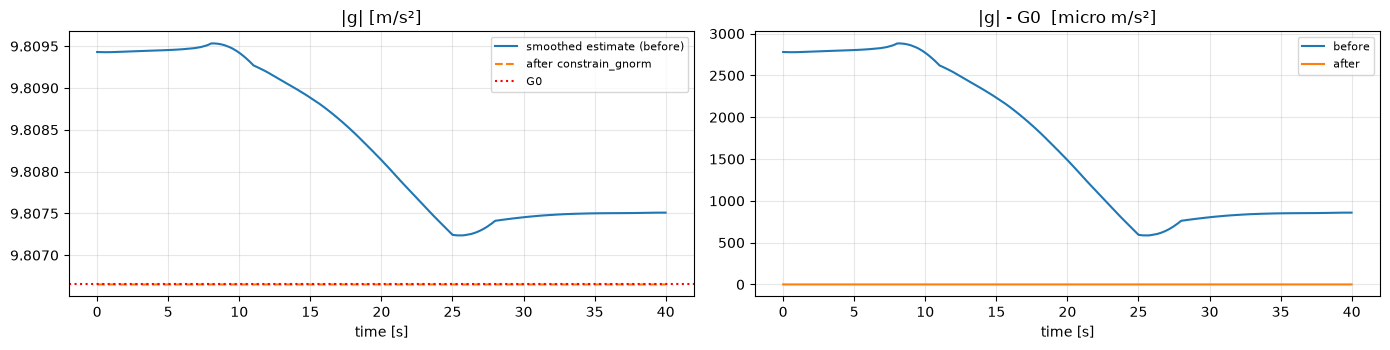

max |g|-G0 before: 2.88e-03 m/s^2;  after: 3.6e-15 m/s^2
largest change of DIRECTION caused by the constraint: 1.9e-06 degrees (it only rescales)


In [44]:
# ======================= Chapter 10 demo: |g| before and after the constraint =======================
# xs = smoothed 15-state of the simulated sensor from Chapter 5; columns 12:15 are the gravity vector (body frame).
g_raw = xs[:, SL["g"]]
g_con = constrain_gnorm(g_raw)
t = truth["t"]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].plot(t, np.linalg.norm(g_raw, axis=1), label="smoothed estimate (before)")
ax[0].plot(t, np.linalg.norm(g_con, axis=1), "--", label="after constrain_gnorm")
ax[0].axhline(G0, color="r", ls=":", label="G0"); ax[0].set_title("|g| [m/s²]"); ax[0].legend(fontsize=8)
ax[1].plot(t, (np.linalg.norm(g_raw, axis=1) - G0) * 1e6, label="before"); ax[1].plot(t, (np.linalg.norm(g_con, axis=1) - G0) * 1e6, label="after")
ax[1].set_title("|g| - G0  [micro m/s²]"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()
ang = np.degrees(np.arccos(np.clip(np.einsum("ni,ni->n", g_raw, g_con) / np.linalg.norm(g_raw, axis=1) / G0, -1, 1)))
print(f"max |g|-G0 before: {np.abs(np.linalg.norm(g_raw,axis=1)-G0).max():.2e} m/s^2;  after: {np.abs(np.linalg.norm(g_con,axis=1)-G0).max():.1e} m/s^2")
print(f"largest change of DIRECTION caused by the constraint: {ang.max():.1e} degrees (it only rescales)")

# Chapter 11 — Reading and writing: data loading, plots

### 11.1 Reading the CSV (`infer_sensors`, `load_csv`, `get_dt`)

Expected columns for each sensor `s1, s2, ...`: `s1_acc_x [mg]`, `s1_acc_y [mg]`, `s1_acc_z [mg]`, `s1_gyro_x [dps]`, ... Other columns
(timestamps, ...) are ignored. `infer_sensors` finds the sensors automatically from the column names (so 2, 4 or 10 IMUs all work);
`load_csv` first removes repeated rows, then converts to SI units:

$$
\text{acc [m/s}^2] = \text{column}\times G_0\ (\text{values are in } g),\qquad \omega\,[\text{rad/s}]=\text{column [deg/s]}\times\tfrac{\pi}{180}.
$$

### ⚠️ Two classic traps (both happened in this project)

1. **The unit written in the header can lie.** In this project the accelerometer columns are *labelled* `[mg]` but contain **g**
   (a sensor at rest reads about 1, not 1000). Reading 1 g as 1 mg makes gravity 1000× too small, and the filter then
   explains the discrepancy as a huge accelerometer bias and also "absorbs" the rotation into the gyro bias. **Always check that
   the acceleration magnitude at rest is close to $G_0$ after conversion.**
2. **The sample period `dt` is fixed to 1/120 s after consecutive duplicate rows are removed.** `get_dt` uses a command-line value, else `config.DT`, else
   1/120 s. If the logger has dropped genuinely new rows or the repeated-row assumption is wrong, every angle, velocity and position can still be scaled wrongly. A **consistency test** needs no extra
   information: the gravity direction can only turn as much as the gyro integrates. The cell below implements that test
   (it is a diagnostic written for this notebook, not part of the pipeline). It is accurate to roughly 5–10 %: use it to detect gross mistakes (such as a 4.5× error), not to fine-tune `dt`.

In [45]:
def infer_sensors(columns: Sequence[str]) -> List[str]:
    # Set of sensor names that have accelerometer columns, e.g. {'s1','s2','s3','s4'} (found by pattern matching the column names).
    acc_s = {m.group(1) for c in columns if (m := ACC_RE.match(c))}
    # Same for gyroscope columns.
    gyr_s = {m.group(1) for c in columns if (m := GYR_RE.match(c))}
    # Keep sensors that have BOTH, sorted numerically (so s10 comes after s9).
    sensors = sorted(acc_s & gyr_s, key=lambda x: int(x[1:]))
    # Nothing found -> stop with a clear message.
    if not sensors:
        raise ValueError("No complete sN accelerometer+gyro sensor groups were found")
    # Sensors that have only half of their columns.
    missing_acc = sorted(acc_s - set(sensors), key=lambda x: int(x[1:]))
    missing_gyr = sorted(gyr_s - set(sensors), key=lambda x: int(x[1:]))
    # A half-complete sensor is an error (better to stop than to guess).
    if missing_acc or missing_gyr:
        raise ValueError(f"Incomplete sensor groups: acc-only={missing_acc}, gyro-only={missing_gyr}")
    # Return the sorted list of complete sensors.
    return sensors

In [46]:
def load_csv(path: Path, nmax: Optional[int] = None):
    # Read the whole CSV first: duplicate-row detection must happen BEFORE nmax.
    df = pd.read_csv(path)
    # Discover all complete sensor groups automatically (s1, s2, ...).
    sensors = infer_sensors(df.columns)
    # As in run_general_*, use the first discovered sensor as the reference (normally s1).
    ref = sensors[0]
    ref_cols = ([f"{ref}_acc_{a} [mg]" for a in "xyz"]
                + [f"{ref}_gyro_{a} [dps]" for a in "xyz"])
    # The CSV labels say [mg], but the accelerometer values are actually in g.
    # Keep the first row and every later row for which ANY of the six reference
    # channels differs from the preceding row. Apply the SAME indices to all IMUs.
    if len(df):
        X = df[ref_cols].to_numpy(float)
        keep = np.r_[True, np.any(np.diff(X, axis=0) != 0, axis=1)]
        df = df.iloc[np.flatnonzero(keep)]
    # nmax now means the number of retained/new samples, not original CSV rows.
    if nmax is not None:
        df = df.iloc[:nmax]
    # Convert units: g -> m/s^2 and degrees/s -> radians/s.
    data = {}
    for sensor in sensors:
        acc_cols = [f"{sensor}_acc_{a} [mg]" for a in "xyz"]
        gyr_cols = [f"{sensor}_gyro_{a} [dps]" for a in "xyz"]
        data[sensor] = (
            df[acc_cols].to_numpy(float) * G0,
            np.deg2rad(df[gyr_cols].to_numpy(float)),
        )
    # All sensors stay synchronized because every sensor used the same row indices.
    n = min(len(v[0]) for v in data.values())
    for sensor in sensors:
        data[sensor] = data[sensor][0][:n], data[sensor][1][:n]
    return data, sensors, n


In [47]:
def get_dt(cli_dt: Optional[float]) -> float:
    # 1) a value given explicitly always wins.
    if cli_dt is not None:
        return float(cli_dt)
    # 2) The data-loading convention is 120 retained samples per second.
    #    Do not silently use a legacy config.DT such as 1/104 s.
    return 1.0 / 120.0

In [48]:
def _time(n, dt):
    # Time axis in seconds: sample number x dt (the first sample is at t = 0).
    return np.arange(n) * dt

In [49]:
# ======================= diagnostic written for this notebook (NOT part of the pipeline) =======================
def suggest_dt(acc, gyro, dt_assumed, win_s=1.0, min_deg=3.0):
    # Compare how much the accelerometer's gravity direction turns with how much the gyro says it turned.
    # If the ratio is far from 1, dt_assumed is probably wrong; the returned value is a suggested dt.
    m = max(2, int(round(win_s / dt_assumed)))                         # window length in samples
    u = acc / np.maximum(np.linalg.norm(acc, axis=1, keepdims=True), 1e-12)   # gravity DIRECTION (unit vectors)
    ang = np.arccos(np.clip(np.einsum("ij,ij->i", u[:-m], u[m:]), -1, 1))     # angle the gravity direction turned in each window
    cs = np.r_[0.0, np.cumsum(np.linalg.norm(gyro, axis=1))]
    gyro_angle = (cs[m:] - cs[:-m])[:len(ang)] * dt_assumed            # angle the gyro integrates in the same window
    ok = gyro_angle > np.deg2rad(min_deg)                              # only windows with real motion
    factor = float(np.percentile(ang[ok] / gyro_angle[ok], 90))        # ~ dt_true / dt_assumed
    return dt_assumed * factor, factor

# test on the simulated sensor of Chapter 5 (we KNOW dt = 0.01):
for wrong in (0.01, 0.02, 0.005):
    dt_s, f = suggest_dt(acc1, gyro1, wrong)
    print(f"assumed dt = {wrong:.3f} s -> factor {f:.3f} -> suggested dt = {dt_s:.4f} s")

assumed dt = 0.010 s -> factor 0.835 -> suggested dt = 0.0083 s
assumed dt = 0.020 s -> factor 0.417 -> suggested dt = 0.0083 s
assumed dt = 0.005 s -> factor 1.669 -> suggested dt = 0.0083 s


### 11.2 The plots
Five small functions draw the PNG files. They all follow the same pattern: for each quantity ($a$, $\omega$, $v$, $p$, $\theta$, biases, gravity)
draw X, Y, Z panels with one thin line per IMU, a thick black line for the **weighted fusion**, and a dashed purple line for
**fusion + second RTS**. The dictionary `QTY` (Chapter 5) says, for each quantity, the title, the key to plot, a *display* scale (e.g. m → mm) and the unit.
Scaling is only cosmetic — stored data stay in SI units.

| Function | Draws |
|---|---|
| `plot_quantity` | a quantity in X/Y/Z for every IMU + fused curves |
| `plot_biases` | accelerometer/gyro bias of each IMU (not fused: they are calibration diagnostics) |
| `plot_fusion_comparison` | only the two fused curves (with / without second RTS), to judge the second smoother |
| `plot_norm` | the length $\|\cdot\|$ of a 3-vector (e.g. total distance from the start, total rotation) |
| `plot_gnorm` | the history of $\|\mathbf g\|$ for each IMU and the consensus |

In [50]:
def plot_quantity(path, t, sensor_results, fused_nav, fused_rts_nav, key, fused_y=None, fused_rts_y=None):
    # Look up the title, data key, display scale and unit of this quantity.
    label, field, scale, unit = QTY[key]
    # Three stacked panels (X, Y, Z) sharing the time axis.
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # One thin line per individual IMU...
    for s, r in sensor_results.items():
        # ...scaled for display...
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.7, alpha=0.7, label=s if j == 0 else None)
    # Thick black line: the weighted fusion.
    if fused_nav is not None:
        # (Take it from the integrated navigation if available, else from the fused array.)
        xf = fused_nav[field] if field in fused_nav else fused_y
        if xf is not None:
            for j in range(3):
                ax[j].plot(t, xf[:, j] * scale, lw=2.0, color=COLORS["fused"], label="weighted fusion" if j == 0 else None)
    # Dashed purple line: fusion + second smoother.
    if fused_rts_nav is not None:
        xr = fused_rts_nav[field] if field in fused_rts_nav else fused_rts_y
        if xr is not None:
            for j in range(3):
                ax[j].plot(t, xr[:, j] * scale, lw=2.0, ls="--", color=COLORS["fused_rts"], label="weighted fusion + second RTS" if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    # Title and legend.
    ax[0].set_title(label)
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout()
    # Write the picture to a PNG file...
    fig.savefig(path, dpi=110)
    # ...and release the memory.
    plt.close(fig)

In [51]:
def plot_biases(path, t, sensor_results, key):
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # One line per IMU (biases are not fused).
    for s, r in sensor_results.items():
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.75, alpha=0.75, label=s if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    # Title, legend, save.
    ax[0].set_title(label + " (individual IMUs)")
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

In [52]:
def plot_fusion_comparison(path, t, fused_nav, fused_rts_nav, key):
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # In each axis panel draw the two fused versions on top of each other.
    for j in range(3):
        ax[j].plot(t, fused_nav[field][:, j] * scale, color=COLORS["fused"], lw=1.7, label="weighted fusion")
        if fused_rts_nav is not None:
            ax[j].plot(t, fused_rts_nav[field][:, j] * scale, color=COLORS["fused_rts"], ls="--", lw=1.8, label="weighted fusion + second RTS")
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]"); ax[j].grid(alpha=0.25)
    # Title, legend, save.
    ax[0].set_title(label + " — fusion comparison")
    ax[0].legend(fontsize=8); ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

In [53]:
def plot_norm(path, t, sensor_results, fused_nav, fused_rts_nav, key):
    """Plot the modulus (Euclidean norm) of a 3-vector quantity.

    Useful for position and angular position, where the norm is the natural
    scalar to compare per-IMU vs covariance-weighted fusion.
    """
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    # One single panel (the length is one number per instant).
    fig, ax = plt.subplots(figsize=(15, 5))

    # Individual IMUs
    # Length of the vector for every IMU:  sqrt(x^2 + y^2 + z^2).
    for s, r in sensor_results.items():
        x = r[field] * scale
        ax.plot(t, np.linalg.norm(x, axis=1), lw=0.8, alpha=0.75, label=s)

    # Covariance-weighted fusion
    # Length of the weighted-fusion vector.
    if fused_nav is not None and field in fused_nav:
        xf = fused_nav[field] * scale
        ax.plot(t, np.linalg.norm(xf, axis=1), lw=2.2,
                color=COLORS["fused"], label="weighted fusion")

    # Fusion + second RTS
    # Length of the fusion + second RTS vector.
    if fused_rts_nav is not None and field in fused_rts_nav:
        xr = fused_rts_nav[field] * scale
        ax.plot(t, np.linalg.norm(xr, axis=1), lw=2.2, ls="--",
                color=COLORS["fused_rts"], label="weighted fusion + second RTS")

    # Labels, title, legend, save.
    ax.set_ylabel(f"|{field}| [{unit}]")
    ax.set_xlabel("time [s]")
    ax.set_title(f"{label} — modulus |{field}|")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

In [54]:
def plot_gnorm(path, t, sensor_results, fused_g=None):
    """History of the modulus of the gravity vector |g| (per IMU, Earth-projected)."""
    # One panel.
    fig, ax = plt.subplots(figsize=(15, 5))
    # |g| of each IMU's Earth-frame gravity vector.
    for s, r in sensor_results.items():
        ax.plot(t, np.linalg.norm(r["gE"], axis=1), lw=0.9, alpha=0.8, label=s)
    # |g| of the consensus gravity.
    if fused_g is not None:
        ax.plot(t, np.linalg.norm(fused_g, axis=1), lw=2.0, ls="--", color=COLORS["fused"],
                label="consensus")
    # Red dotted reference line at G0.
    ax.axhline(G0, color="r", ls=":", lw=1.2, label=f"G0 = {G0:.5f}")
    ax.set_ylabel(r"$|g|$ [m/s$^2$]"); ax.set_xlabel("time [s]")
    ax.set_title("gravity vector — modulus |g|")
    ax.grid(alpha=0.25); ax.legend(fontsize=8, ncol=3)
    # Save the picture.
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

# Chapter 12 — The animated GIFs (IMU vs. fused, seen from the Earth)

For every IMU the program writes one GIF that compares **that IMU alone** (solid, colour) with the **final fused result** (dashed).
All quantities are the Earth-frame estimates behind the PNG plots — nothing new is computed for the animation.

| Panel | What you see |
|---|---|
| **Left (big)** | the trajectory $\mathbf p(t)$ in Earth axes X, Y, Z (a trail), and at the current position a small plate with the body's x/y/z axes (red/green/blue), oriented by the current attitude |
| **Top right** | the *rotation alone*: both plates at a common pivot with the Earth axes, so rotations are easy to read |
| **Middle right** | position X/Y/Z versus time with a moving cursor |
| **Bottom right** | cumulative rotation $\int\boldsymbol\omega_E\,dt$ (unwrapped, so 720° really reads 720°) |

**Attitude used for the plates.** The pipeline integrates the Earth-frame rate from the identity ("no rotation yet"), so the *relative*
rotation is $R_{rel}(k)$. To get the sensor's *absolute* attitude we multiply by the starting attitude: $R_{abs}(k)=R_{rel}(k)\,R_{abs}(0)$
with $R_{abs}(0)=R_{hist}[0]\,C_i$ (sensor → Earth at $t=0$). The fused track uses the same start so the comparison is fair.

**Frame choice.** Frames are not equally spaced in time. They are equally spaced in "how much happened": rotation angle travelled + distance travelled + a small time term.
So fast motions look smooth and still periods are fast-forwarded (the title shows the playback speed).

In [55]:
# ======================= constants and imports of the GIF module (imu_gifs.py) =======================
from matplotlib.animation import FuncAnimation, PillowWriter     # tools that turn a function into an animation / GIF file
from mpl_toolkits.mplot3d.art3d import Poly3DCollection          # lets us draw filled 3-D polygons (the 'plate')

AX_COL = ("tab:red", "tab:green", "tab:blue")      # colours of the body x, y, z axes
FPS = 20                                           # frames per second of the GIF
MAX_FRAMES = 36                                    # NOTE: the project uses 220 frames; reduced here so the demo runs quickly
DPI = 70                                           # picture resolution of the GIF
GIF_COLORS = ("tab:orange", "tab:blue", "tab:green", "tab:red", "tab:brown", "tab:pink", "tab:olive", "tab:cyan")   # one colour per IMU

In [56]:
def frame_indices(w, p, dt, max_frames=MAX_FRAMES, rest=0.15):
    """Frames equally spaced in (angle travelled + distance travelled + a small time
    term): smooth motion while moving, fast-forward while still."""
    # Size of the angular rate at every instant...
    wn = np.linalg.norm(w, axis=1)
    # ...and the speed (how fast the position changes).
    sp = np.linalg.norm(np.gradient(p, dt, axis=0), axis=1)
    # 'Activity' = rate/typical rate + speed/typical speed + a small constant (so still periods are not skipped entirely).
    r = wn / max(np.percentile(wn, 95), 1e-12) + sp / max(np.percentile(sp, 95), 1e-12) + rest
    # Accumulate the activity over time (trapezoid rule): s = total 'amount of happenings' so far.
    s = np.concatenate([[0.0], np.cumsum(0.5 * (r[1:] + r[:-1]) * dt)])
    # Choose max_frames instants equally spaced in s (not in time).
    idx = np.unique(np.clip(np.searchsorted(s, np.linspace(0.0, s[-1], max_frames)), 0, len(p) - 1))
    # Always include the very last sample.
    if idx[-1] != len(p) - 1:
        idx = np.append(idx, len(p) - 1)
    # The list of sample numbers that become frames.
    return idx

In [57]:
def _plate(R, center, half):
    # Geometry of the little plate that stands for the sensor: 6 faces of a thin box.
    # Half-sizes of the plate along its own x, y, z axes.
    sx, sy, sz = half
    # The 8 corners of the little box, in the body's own axes.
    v = np.array([[x, y, z] for x in (-sx, sx) for y in (-sy, sy) for z in (-sz, sz)])
    # Rotate the corners by the attitude R and move them to the centre position.
    v = center + v @ R.T
    # Return the 6 faces (each a list of 4 corners) for drawing.
    return [v[list(q)] for q in [(0, 1, 3, 2), (4, 5, 7, 6), (0, 1, 5, 4),
                                  (2, 3, 7, 6), (0, 2, 6, 4), (1, 3, 7, 5)]]

In [58]:
def geodesic_deg(Ra, Rb):
    # How different are two orientations? (an angle in degrees)
    # For two rotations, trace(Ra^T Rb) = 1 + 2 cos(angle between them)...
    c = 0.5 * (np.einsum("nij,nij->n", Ra, Rb) - 1.0)
    # ...so this is the angle (in degrees) of the rotation that takes Ra into Rb.
    return np.degrees(np.arccos(np.clip(c, -1.0, 1.0)))

In [59]:
def make_imu_dynamics_gif(path, sensor, dt, imu, fused, imu_color="tab:orange",
                          fused_color="black", fused_label="fused"):
    # Number of samples; time axis.
    n = len(imu["R"])
    t = np.arange(n) * dt
    # Two 'tracks' to compare: the single IMU and the fused result. Each has attitude R, position p, rate w.
    T = {"imu": imu, "fused": fused}
    # Colours and labels of the two tracks.
    col = {"imu": imu_color, "fused": fused_color}
    lab = {"imu": sensor, "fused": fused_label}
    # Attitude matrices of the two tracks.
    R = {k: np.asarray(v["R"], float) for k, v in T.items()}
    # Positions, converted from metres to millimetres.
    P = {k: np.asarray(v["p"], float) * 1e3 for k, v in T.items()}                 # mm
    # Cumulative rotation = running sum of (rate x dt), in degrees (unwrapped).
    TH = {k: np.degrees(np.cumsum(np.asarray(v["w"], float), axis=0) * dt) for k, v in T.items()}
    # Angle between the two attitudes at every instant.
    diff = geodesic_deg(R["imu"], R["fused"])
    # Which samples become animation frames.
    idx = frame_indices(np.asarray(fused["w"], float), np.asarray(fused["p"], float), dt)

    # cubic axis box around both trajectories
    # Size of the 3-D box: it must contain both trajectories...
    allp = np.concatenate([P["imu"], P["fused"]])
    lo, hi = allp.min(0), allp.max(0)
    ctr = 0.5 * (lo + hi)
    # ...(at least 1 mm so a motionless sensor does not give a zero-size box).
    half = max(0.6 * float(np.max(hi - lo)), 1.0)                                  # >= 1 mm
    # Size of the plate relative to the box.
    body = (0.10 * half, 0.06 * half, 0.012 * half)                                # plate half-sizes
    # Length of the drawn body axes.
    Lax = 0.16 * half                                                              # body-axis length

    # Create the picture and its layout: a big 3-D panel on the left, a small 3-D panel and two plots on the right.
    fig = plt.figure(figsize=(14.5, 8.2))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1.0], height_ratios=[1.25, 0.8, 0.8],
                          hspace=0.55, wspace=0.10, left=0.01, right=0.985, top=0.93, bottom=0.06)
    ax = fig.add_subplot(gs[:, 0], projection="3d")
    axr = fig.add_subplot(gs[0, 1], projection="3d")
    axp = fig.add_subplot(gs[1, 1])
    axt = fig.add_subplot(gs[2, 1])
    # A title that will show the time and playback speed.
    title = fig.suptitle("", fontsize=12, weight="bold", family="monospace", x=0.01, ha="left")

    # ---- trajectory view
    # Left panel: axis limits (a cube around the data), labels and viewing angle.
    ax.set_xlim(ctr[0] - half, ctr[0] + half); ax.set_ylim(ctr[1] - half, ctr[1] + half)
    ax.set_zlim(ctr[2] - half, ctr[2] + half); ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("X [mm]"); ax.set_ylabel("Y [mm]"); ax.set_zlabel("Z [mm] (up)")
    ax.view_init(elev=22, azim=-58)
    # Gold star at the start position.
    ax.plot([P["imu"][0, 0]], [P["imu"][0, 1]], [P["imu"][0, 2]], marker="*", ms=12,
            color="gold", mec="k", ls="none", label="start")
    # 'Artists' = the drawn objects that will be moved at every frame.
    art = {}
    # For each of the two tracks create: a trail line, a head dot, the plate and the 3 body axes.
    for k in T:
        trail, = ax.plot([], [], [], color=col[k], lw=1.8 if k == "imu" else 1.4,
                         ls="-" if k == "imu" else "--", label=lab[k])
        head, = ax.plot([], [], [], marker="o", ms=5, color=col[k], ls="none")
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), body), facecolors=col[k],
                                 edgecolors=col[k] if k == "imu" else "k",
                                 alpha=0.35 if k == "imu" else 0.15, linewidths=1.0)
        ax.add_collection3d(faces)
        axes = [ax.plot([], [], [], color=AX_COL[j], lw=2.6 if k == "imu" else 1.4,
                        ls="-" if k == "imu" else "--")[0] for j in range(3)]
        art[k] = dict(trail=trail, head=head, faces=faces, axes=axes)
    # Legend.
    ax.legend(loc="upper left", fontsize=8)

    # ---- rotation view (common pivot)
    # Top-right panel: a unit cube with Earth axes X, Y, Z drawn as dotted lines.
    axr.set_xlim(-1, 1); axr.set_ylim(-1, 1); axr.set_zlim(-1, 1); axr.set_box_aspect((1, 1, 1))
    axr.view_init(elev=20, azim=-58)
    axr.set_xticklabels([]); axr.set_yticklabels([]); axr.set_zticklabels([])
    axr.set_title("rotation in Earth frame (common pivot)   body axes x/y/z = red/green/blue",
                  fontsize=8.5, pad=-4)
    for e, txt in zip(np.eye(3), "XYZ"):
        axr.plot([0, 1.0 * e[0]], [0, 1.0 * e[1]], [0, 1.0 * e[2]], color="0.4", lw=1.0, ls=":")
        axr.text(*(1.1 * e), txt, color="0.25", fontsize=9)
    # Again the artists, this time for the rotation-only view.
    rart = {}
    # Plate and three body axes for each track, at the pivot.
    for k in T:
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), (0.5, 0.32, 0.06)),
                                 facecolors=col[k], edgecolors=col[k] if k == "imu" else "k",
                                 alpha=0.30 if k == "imu" else 0.12, linewidths=1.0)
        axr.add_collection3d(faces)
        axes = [axr.plot([], [], [], color=AX_COL[j], lw=3.0 if k == "imu" else 1.5,
                         ls="-" if k == "imu" else "--")[0] for j in range(3)]
        rart[k] = dict(faces=faces, axes=axes)

    # ---- time histories
    # Lines of the two time-history plots (they will be extended frame by frame).
    prog = {}
    # Small helper that sets labels and title of a time plot.
    def style(a, yl, ttl):
        a.set_ylabel(yl, fontsize=8); a.set_title(ttl, fontsize=8.5, loc="left", pad=2)
        a.grid(alpha=0.25); a.tick_params(labelsize=7); a.set_xlim(t[0], t[-1])
    # Middle-right: position; bottom-right: cumulative rotation.
    style(axp, "mm", "position p  (x/y/z = red/green/blue, solid = IMU, dashed = fused)")
    style(axt, "deg", "cumulative rotation  ∫ω_E dt  (x/y/z = red/green/blue)")
    # Draw the complete histories faintly (the 'future'), and prepare bold lines for the 'past'.
    for a, D, name in ((axp, P, "p"), (axt, TH, "t")):
        for k in T:
            for j in range(3):
                a.plot(t, D[k][:, j], color=AX_COL[j], lw=2.0 if k == "imu" else 1.2,
                       ls="-" if k == "imu" else "--", alpha=0.25)
                prog[(name, k, j)] = a.plot([], [], color=AX_COL[j], lw=2.0 if k == "imu" else 1.2,
                                            ls="-" if k == "imu" else "--")[0]
    # Time label.
    axt.set_xlabel("time [s]", fontsize=8)
    # Vertical black line that marks the current time.
    cursors = [axp.axvline(0, color="k", lw=0.9), axt.axvline(0, color="k", lw=0.9)]

    # Helper: set a 3-D line from point a to point b.
    def setline(ln, a, b):
        ln.set_data([a[0], b[0]], [a[1], b[1]]); ln.set_3d_properties([a[2], b[2]])

    # UPDATE: this function redraws everything for frame number fi (it is called once per frame).
    def update(fi):
        # kk = the sample number shown in this frame.
        kk = int(idx[fi])
        # Playback speed for the title (simulated seconds per real second).
        sp = (t[idx[fi + 1]] - t[kk]) * FPS if fi + 1 < len(idx) else 0.0
        # Write time and speed in the title.
        title.set_text(f"{sensor} vs {fused_label}   t = {t[kk]:6.2f} s   playback x{sp:.1f}")
        # Which past samples to draw (thinned out if there are very many).
        sl = slice(0, kk + 1, max(1, kk // 1500 + 1))
        # For each track:
        for k in T:
            # its attitude and position now,
            Rk = R[k][kk]; pk = P[k][kk]; a = art[k]
            seg = P[k][sl]
            # extend the trail,
            a["trail"].set_data(seg[:, 0], seg[:, 1]); a["trail"].set_3d_properties(seg[:, 2])
            a["head"].set_data([pk[0]], [pk[1]]); a["head"].set_3d_properties([pk[2]])
            # move and rotate the plate,
            a["faces"].set_verts(_plate(Rk, pk, body))
            # do the same in the rotation-only view,
            r = rart[k]
            r["faces"].set_verts(_plate(Rk, np.zeros(3), (0.5, 0.32, 0.06)))
            # re-aim the three body axes,
            # and extend the position and angle histories.
            for j in range(3):
                setline(a["axes"][j], pk, pk + Lax * Rk[:, j])
                setline(r["axes"][j], np.zeros(3), 0.85 * Rk[:, j])
            for j in range(3):
                prog[("p", k, j)].set_data(t[sl], P[k][sl, j])
                prog[("t", k, j)].set_data(t[sl], TH[k][sl, j])
        # Move the time cursor.
        for c in cursors:
            c.set_xdata([t[kk], t[kk]])
        # (nothing else to report)
        return []

    # Ask matplotlib to call `update` once per frame...
    ani = FuncAnimation(fig, update, frames=len(idx), blit=False)
    # ...and write the frames to a GIF file.
    ani.save(str(path), writer=PillowWriter(fps=FPS), dpi=DPI)
    # Release the memory.
    plt.close(fig)

In [60]:
# The project keeps the GIF code in its own file, imu_gifs.py, and run_general_multisensor_dynamic.py does
#     from imu_gifs import make_imu_dynamics_gif
# Here the same function lives in this notebook, so we register it under that module name; then the
# pipeline code below runs UNCHANGED.
_gif_module = types.ModuleType("imu_gifs")
_gif_module.make_imu_dynamics_gif = make_imu_dynamics_gif
sys.modules["imu_gifs"] = _gif_module

In [61]:
def make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt):
    """One GIF per IMU: IMU estimate vs final fused estimate, Earth frame.
    Attitude R_abs(k) = R_rel(k) @ R_abs(0) with R_rel the integrated Earth angular
    rate (same as `theta`) and R_abs(0) = R_hist[0] @ C (sensor -> Earth at t0)."""
    # Get the drawing function (see the registration cell above).
    from imu_gifs import make_imu_dynamics_gif
    # The 'final fused' track: fusion + second RTS if it was computed, otherwise the plain fusion.
    nav_fin = nav_rts if nav_rts is not None else nav_f
    # Label and colour for that track.
    fused_label = "fused + 2nd RTS" if nav_rts is not None else "fused"
    # (colour)
    fused_color = COLORS["fused_rts"] if nav_rts is not None else COLORS["fused"]
    # Folder 'gifs' inside the output folder.
    gif_dir = file_out / "gifs"; gif_dir.mkdir(exist_ok=True)
    # One GIF per sensor.
    for i, s in enumerate(sensors):
        # Starting absolute attitude of this sensor: R_abs(0) = R_hist[0] x C.
        R0s = results[s]["R_hist"][0] @ results[s]["C"]
        # This sensor's own navigation result.
        nav = results[s]["nav"]
        # Track of the single IMU: absolute attitude = relative rotation x starting attitude.
        imu = dict(R=nav["R"] @ R0s, p=nav["p"], w=nav["wE"])
        # Track of the fused result, expressed on THIS sensor's body axes with the same start.
        fus = dict(R=nav_fin["R"] @ R0s, p=nav_fin["p"], w=nav_fin["wE"])
        # File name of the GIF.
        out = gif_dir / f"dynamics_{s}_vs_fused.gif"
        # Draw and save the animation.
        make_imu_dynamics_gif(out, s, dt, imu, fus, imu_color=GIF_COLORS[i % len(GIF_COLORS)],
                              fused_color=fused_color, fused_label=fused_label)
        # Report progress.
        print(f"  saved {out.name}", flush=True)

# Chapter 13 — Putting it all together: `process_file`

`process_file` is the conductor: it calls every function we have studied, in this order.

| # | What it does | Chapter |
|---|---|---|
| 1 | read the CSV and convert units | 11 |
| 2 | for each IMU: noise settings → start values from the still interval → adaptive EKF → RTS smoother | 4–5 |
| 3 | register all IMUs to sensor 1 (Wahba, leave-one-out) | 7 |
| 4 | consensus gravity & rate in sensor 1's axes; initial attitude (yaw = 0); integrate the rate | 7–8 |
| 5 | per IMU: gravity-corrected attitude $R_{hist}$, then project the whole state to the Earth with its covariance; integrate that IMU alone | 8–9 |
| 6 | fuse all IMUs in the Earth frame (information fusion); integrate | 6, 9 |
| 7 | optional second smoother on the fused curve; integrate | 9 |
| 8 | write plots (with the $\|\mathbf g\|=G_0$ output constraint), diagnostics, `results.npz`, the GIFs, a summary CSV | 10–12 |

The function arguments are the *knobs* of the pipeline:

| Argument | Meaning |
|---|---|
| `dt` | time between rows [s] (Chapter 11) |
| `align_s` | length of the initial **still** interval used for start values [s]. *Must be shorter than the real still period!* |
| `second_rts`, `r_inflation`, `q_scale` | switch/tuning of the second smoother (Chapter 9) |
| `registration_stride` | use every n-th sample for registration (speed) |
| `active_thr_dps` | diagnostic "is moving" threshold |
| `nmax` | process only the first n rows (quick tests) |
| `registration_refine_iters` | leave-one-out sweeps (3 or more IMUs) |

In [62]:
def process_file(path: Path, out_root: Path, dt: float, align_s: float,
                 second_rts: bool, r_inflation: float, q_scale: float,
                 registration_stride: int, active_thr_dps: float,
                 nmax: Optional[int], registration_refine_iters: int = 2):
    # 1) READ the file; sensors = the list of IMU names found, n = number of samples.
    data, sensors, n = load_csv(path, nmax=nmax)
    # Create an output folder named after the file.
    file_out = out_root / path.stem
    file_out.mkdir(parents=True, exist_ok=True)

    # Dictionaries that will hold, per sensor: smoothed states, covariances, noise histories, raw data, settings.
    xs = {}; Ps = {}; qhist = {}; raw_acc = {}; raw_gyro = {}; cfgs = {}
    print(f"\n=== {path.name}: {n} samples, {len(sensors)} IMUs ({', '.join(sensors)}) ===", flush=True)

    # 2) FOR EACH IMU, run the filter alone:
    for s in sensors:
        # its accelerometer and gyro data (SI units);
        acc, gyro = data[s]
        # its noise settings (priors + noise measured from the first seconds);
        cfg = make_cfg(acc, gyro, dt)
        # number of samples in the initial still interval;
        na = max(1, min(n, int(round(align_s / dt))))
        # start values from the still interval (gravity direction, biases);
        x0 = AEKFRTS.stationary_initial_state(acc[:na].mean(0), gyro[:na].mean(0), cfg.G0)
        # create the filter;
        ekf = AEKFRTS(cfg, x0)
        # forward Kalman pass + backward RTS pass;
        out = ekf.run(acc, gyro, do_smooth=True)
        # keep the smoothed states and covariances...
        xs[s] = out["xs"]
        Ps[s] = out["Ps"]
        # ...and the history of the adaptive process noise;
        qhist[s] = np.asarray(out["qhist"])
        # keep the raw data for later diagnostics.
        raw_acc[s] = acc
        raw_gyro[s] = gyro
        cfgs[s] = cfg
        print(f"  finished AEKF+RTS {s}", flush=True)

    # 3) REGISTRATION: the rotation C of every sensor into sensor 1's axes (Wahba problem).
    C, active_mask, reg_stats = register_sensors(
        xs, Ps, sensors, stride=registration_stride, active_thr_dps=active_thr_dps,
        refine_iters=registration_refine_iters,
    )
    # Print how well each registration is determined (1-sigma in degrees).
    for s in sensors[1:]:
        print(f"  registration {s}->{sensors[0]}: 1-sigma [deg] = "
              f"{np.array2string(reg_stats[s]['sigma_deg'], precision=3)}", flush=True)
    # 4) CONSENSUS: fuse the gravity and rate of all IMUs in sensor 1's axes.
    g_cons, w_cons, P_cons = consensus_body_history(xs, Ps, C, sensors)
    # Initial attitude from the consensus gravity (yaw = 0 convention).
    R0 = gravity_alignment_R(g_cons[0])  # yaw(t=0)=0 convention
    # Integrate the consensus rate: an orientation that is right in yaw but drifts in tilt.
    R_base = integrate_orientation(w_cons, R0, dt)

    # Per-IMU results container.
    results = {}
    # 5) FOR EACH IMU, go to the Earth frame:
    for s in sensors:
        # this sensor's gravity expressed in sensor 1's axes;
        g_ref = np.einsum("ij,nj->ni", C[s], xs[s][:, SL["g"]])
        # tilt-corrected orientation history;
        R_hist = gravity_corrected_orientation(R_base, g_ref)
        # rotate the 15-state and its covariance into Earth axes;
        Y15, P15 = project_earth_with_cov(xs[s], Ps[s], C[s], R_hist, G0)
        # integrate THIS sensor alone: velocity, position, angle;
        nav = nav_from_projected(Y15, dt)
        # store everything (gravity gets the |g| = G0 output constraint).
        results[s] = {
            "xs": xs[s], "Ps": Ps[s], "qhist": qhist[s], "C": C[s],
            "R_hist": R_hist, "earth15": Y15, "earthP15": P15,
            "aE": Y15[:, 0:3], "wE": Y15[:, 3:6],
            "baE": Y15[:, 6:9], "bwE": Y15[:, 9:12], "gE": constrain_gnorm(Y15[:, 12:15]),
            "aE_P": P15[:, 0:3, 0:3], "wE_P": P15[:, 3:6, 3:6],
            "nav": nav,
            "raw_acc": raw_acc[s], "raw_gyro": raw_gyro[s],
        }
        print(f"  projected Earth frame {s}", flush=True)

    # 6) FUSION in the Earth frame: stack every IMU's [a_E, w_E]...
    Y = np.stack([results[s]["earth15"][:, 0:6] for s in sensors])
    # ...and their covariances...
    P = np.stack([results[s]["earthP15"][:, 0:6, 0:6] for s in sensors])
    # ...and fuse them (information form).
    y_f, p_f = fuse_information(Y, P)
    # Integrate the fused result: velocity, position, angle.
    nav_f = integrate_navigation(y_f[:, :3], y_f[:, 3:6], dt)

    # 7) SECOND SMOOTHER (optional):
    y_rts = p_rts = nav_rts = None
    # (only if switched on)
    if second_rts:
        # average process noise of the IMUs in Earth axes;
        Q = fused_Q_from_individuals(results, sensors)
        # smooth the fused curve;
        y_rts, p_rts = second_rts_random_walk(
            y_f, p_f, Q, r_inflation=r_inflation, q_scale=q_scale
        )
        # integrate it.
        nav_rts = integrate_navigation(y_rts[:, :3], y_rts[:, 3:6], dt)

    # 8) OUTPUTS. Time axis;
    t = _time(n, dt)
    # data dictionary for the plot functions;
    sensor_plot = {s: {
        "aE": results[s]["aE"], "wE": results[s]["wE"],
        "baE": results[s]["baE"], "bwE": results[s]["bwE"], "gE": results[s]["gE"],
        "v": results[s]["nav"]["v"], "p": results[s]["nav"]["p"], "theta": results[s]["nav"]["theta"],
    } for s in sensors}

    # Plots: all requested quantities in Earth frame. Biases are individual-only.
    # one plot (+ fusion comparison) for each of: acceleration, rate, velocity, position, angle;
    for q in ("a", "w", "v", "p", "theta"):
        plot_quantity(file_out / f"{q}.png", t, sensor_plot, nav_f, nav_rts, q,
                      fused_y=y_f, fused_rts_y=y_rts)
        plot_fusion_comparison(file_out / f"{q}_fusion_compare.png", t, nav_f, nav_rts, q)
        # Modulus plots for position and angular position (per-IMU vs fused).
    # plots of the length of position and angle;
    for q in ("p", "theta"):
        plot_norm(file_out / f"{q}_norm.png", t, sensor_plot,
                  nav_f, nav_rts, q)
        plot_norm(file_out / f"{q}_norm_fusion_compare.png", t, {}, nav_f, nav_rts, q)
    # bias and gravity plots;
    for q in ("ba", "bw", "g"):
        plot_biases(file_out / f"{q}.png", t, sensor_plot, q)
    # history of |g| (with the output constraint);
    plot_gnorm(file_out / "g_norm.png", t, sensor_plot, constrain_gnorm(g_cons))

    # Additional diagnostics directly at the filter output, before registration.
    # diagnostics table: raw gyro vs estimated rate, registration uncertainty;
    diag_rows = []
    for s in sensors:
        w_raw = raw_gyro[s]
        w_est = xs[s][:, SL["w"]]
        raw_rms = np.sqrt(np.mean(np.sum(w_raw * w_raw, axis=1)))
        est_rms = np.sqrt(np.mean(np.sum(w_est * w_est, axis=1)))
        diag_rows.append({
            "file": path.name, "sensor": s,
            "raw_gyro_rms_dps": np.rad2deg(raw_rms),
            "aekf_rts_w_rms_dps": np.rad2deg(est_rms),
            "aekf_rts_w_max_dps": np.rad2deg(np.max(np.linalg.norm(w_est, axis=1))),
            "registration_sigma_max_deg": reg_stats[s]["sigma_max_deg"],
        })
    # save it as filter_diagnostic.csv;
    pd.DataFrame(diag_rows).to_csv(file_out / "filter_diagnostic.csv", index=False)

    # Save compact output for downstream analysis.
    # pack the main arrays...
    save_dict = {"t": t, "sensors": np.array(sensors, dtype=object), "R0": R0,
                 "g_consensus_B": g_cons, "w_consensus_B": w_cons, "P_consensus_gw_B": P_cons,
                 "active_mask": active_mask, "y_fused": y_f, "P_fused": p_f}
    if y_rts is not None:
        save_dict.update({"y_fused_rts": y_rts, "P_fused_rts": p_rts})
    for s in sensors:
        r = results[s]
        save_dict.update({
            f"{s}_xf": np.asarray(r["xs"]),
            f"{s}_Pf": np.asarray(r["Ps"]),
            f"{s}_C": r["C"], f"{s}_C_cov_rad2": reg_stats[s]["cov"], f"{s}_R_hist": r["R_hist"],
            f"{s}_earth15": r["earth15"], f"{s}_earthP15": r["earthP15"],
            f"{s}_aE": r["aE"], f"{s}_wE": r["wE"],
            f"{s}_baE": r["baE"], f"{s}_bwE": r["bwE"], f"{s}_gE": r["gE"],
            f"{s}_v": r["nav"]["v"], f"{s}_p": r["nav"]["p"], f"{s}_theta": r["nav"]["theta"],
        })
    save_dict.update({
        "a_fused": nav_f["aE"], "w_fused": nav_f["wE"], "v_fused": nav_f["v"],
        "p_fused": nav_f["p"], "theta_fused": nav_f["theta"],
    })
    if nav_rts is not None:
        save_dict.update({
            "a_fused_rts": nav_rts["aE"], "w_fused_rts": nav_rts["wE"],
            "v_fused_rts": nav_rts["v"], "p_fused_rts": nav_rts["p"], "theta_fused_rts": nav_rts["theta"],
        })
    # ...and save them in results.npz;
    np.savez_compressed(file_out / "results.npz", **save_dict)

    # write the animated GIFs (Chapter 12);
    make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt)

    # One-line numerical summary useful for batch runs.
    # one-line numerical summary of the run...
    summary = {
        "file": path.name, "n_samples": n, "n_imus": len(sensors), "dt_s": dt,
        "duration_s": (n - 1) * dt,
        "fused_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_f["aE"]**2, axis=1)))),
        "fused_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_f["wE"]**2, axis=1))))),
        "fused_v_end_mmps": float(1e3 * np.linalg.norm(nav_f["v"][-1])),
        "fused_p_end_mm": float(1e3 * np.linalg.norm(nav_f["p"][-1])),
        "fused_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_f["theta"][-1]))),
        "second_rts": bool(second_rts),
    }
    if nav_rts is not None:
        summary.update({
            "fused_rts_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_rts["aE"]**2, axis=1)))),
            "fused_rts_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_rts["wE"]**2, axis=1))))),
            "fused_rts_v_end_mmps": float(1e3 * np.linalg.norm(nav_rts["v"][-1])),
            "fused_rts_p_end_mm": float(1e3 * np.linalg.norm(nav_rts["p"][-1])),
            "fused_rts_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_rts["theta"][-1]))),
        })
    # ...saved as summary.csv;
    pd.DataFrame([summary]).to_csv(file_out / "summary.csv", index=False)
    print(f"  saved {file_out}", flush=True)
    # done.
    return summary

# Chapter 14 — A complete run on simulated data, checked against the truth

We now run **the whole pipeline** on a CSV that we generate ourselves: **four IMUs** glued to the same moving object with
**different mountings**, **different biases** and **noise**. The object rotates 720° about Earth's Y axis and moves a little.
Because we know the truth we can *grade* the answer.

The simulated CSV follows the project's conventions: columns named `s1_acc_x [mg]` ... that actually contain **g**, and `s1_gyro_x [dps]`.

In [63]:
# ======================= build a simulated 4-IMU CSV file (teaching tool) =======================
import tempfile, os
rng = np.random.default_rng(42)
truth = simulate_motion()                      # same motion as before (40 s, 720 deg about Earth Y)

mounts = [np.eye(3),                                                    # s1: the reference sensor
          Rot.from_euler("xyz", [10, -20, 35], degrees=True).as_matrix(),   # s2: some random mounting rotations
          Rot.from_euler("xyz", [-25, 5, 70], degrees=True).as_matrix(),    # s3
          Rot.from_euler("xyz", [30, 40, -50], degrees=True).as_matrix()]   # s4
cols = {}
for i, C_m in enumerate(mounts, start=1):
    ba = rng.normal(0, 0.02, 3)                                         # each sensor gets its own random biases
    bw = np.deg2rad(rng.normal(0, 0.15, 3))
    acc, gyro = make_imu(truth, C=C_m, ba=ba, bw=bw, rng=rng)           # what that sensor would output
    for j, ax_name in enumerate("xyz"):
        cols[f"s{i}_acc_{ax_name} [mg]"] = acc[:, j] / G0               # project convention: header says mg, values are g
        cols[f"s{i}_gyro_{ax_name} [dps]"] = np.rad2deg(gyro[:, j])
sim_dir = Path(tempfile.mkdtemp(prefix="imu_sim_"))
sim_csv = sim_dir / "simulated_720deg.csv"
pd.DataFrame(cols).to_csv(sim_csv, index=False)
print("wrote", sim_csv, "| columns:", len(cols), "| rows:", len(truth["t"]))
print("acceleration magnitude at rest (should be ~1 g):", np.linalg.norm([cols[f's1_acc_{a} [mg]'][:100].mean() for a in 'xyz']).round(4))

wrote C:\Users\verga\AppData\Local\Temp\imu_sim_lmrq7blj\simulated_720deg.csv | columns: 24 | rows: 4800
acceleration magnitude at rest (should be ~1 g): 0.9994


In [64]:
# ======================= run the whole pipeline on the simulated file =======================
sim_out = sim_dir / "outputs"
summary = process_file(
    path=sim_csv, out_root=sim_out,
    dt=truth["dt"],                     # the true sample period of the simulation
    align_s=5.0,                        # the first 5 s are still (the motion starts at t = 8 s)
    second_rts=SECOND_RTS_DEFAULT, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
    registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
    nmax=None, registration_refine_iters=2)
print(); print(pd.Series(summary).to_string())


=== simulated_720deg.csv: 4800 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s3->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s4->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved dynamics_s1_vs_fused.gif
  saved dynamics_s2_vs_fused.gif
  saved dynamics_s3_vs_fused.gif
  saved dynamics_s4_vs_fused.gif
  saved C:\Users\verga\AppData\Local\Temp\imu_sim_lmrq7blj\outputs\simulated_720deg

file                        simulated_720deg.csv
n_samples                                   4800
n_imus                                         4
dt_s                                    0.008333
duration_s                             39.991667
fused_a_rms_mps2                        0.005399
fused_w_rms_dps                        26.7

### Did the registration find the mountings?
The program estimated $C_i$ (sensor $i$ → sensor 1). The truth is $C_{\text{true}}=C_i^{\text{mount}}$ (we built the sensor data with
`acc @ C`, i.e. $\mathbf v_{\text{sensor}}=C^{\mathsf T}\mathbf v_{\text{body}}$). Let us compare.

In [65]:
res = np.load(sim_out / "simulated_720deg" / "results.npz", allow_pickle=True)    # the arrays the pipeline saved
for i in range(2, 5):
    C_est = res[f"s{i}_C"]
    err = np.rad2deg(np.linalg.norm(Rot.from_matrix(C_est.T @ mounts[i - 1]).as_rotvec()))
    print(f"sensor s{i}: registration error = {err:.3f} deg")

sensor s2: registration error = 0.132 deg
sensor s3: registration error = 0.102 deg
sensor s4: registration error = 0.096 deg


### How good are the fused estimates? (compare with the truth)
One subtlety: the pipeline fixes **yaw = 0 at the start** (gravity cannot know the compass heading). Our simulated "true Earth" has a
different heading, so before comparing we rotate the truth by the constant yaw offset $Y=R_0R_{\text{true}}(0)^{\mathsf T}$ ($R_0$ is saved in the results).

RMS error of the rotation rate [deg/s]
   single IMU s1      : 0.0578
   single IMU s2      : 0.0754
   single IMU s3      : 0.0639
   single IMU s4      : 0.0668
   FUSED               : 0.0571
   FUSED + 2nd RTS     : 0.0570

RMS error of the acceleration [m/s^2]
   single IMU s1      : 0.00765
   single IMU s2      : 0.00781
   single IMU s3      : 0.00787
   single IMU s4      : 0.00773
   FUSED               : 0.00776
   FUSED + 2nd RTS     : 0.00772


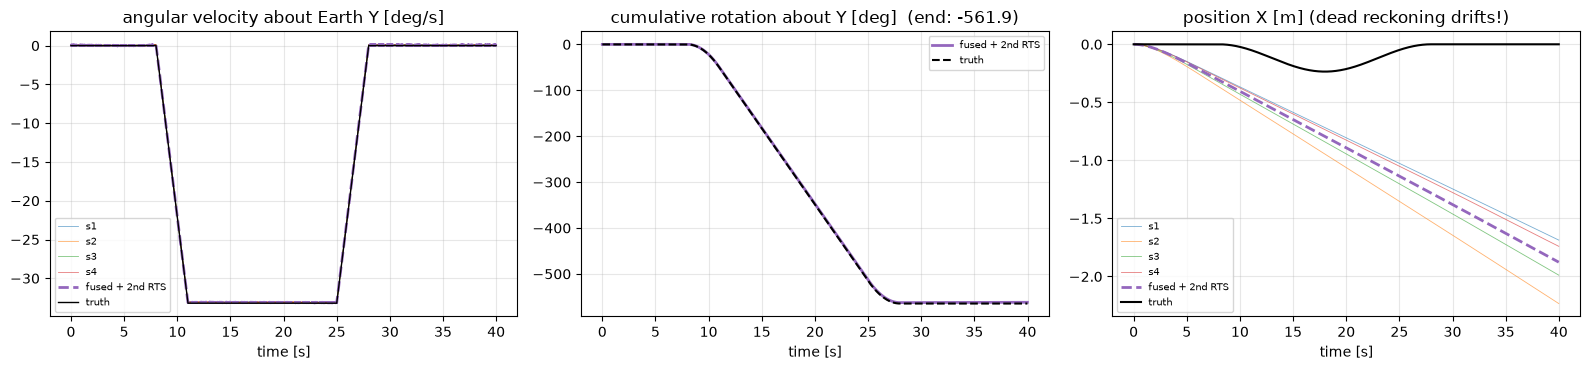

In [66]:
Yoff = res["R0"] @ truth["R"][0].T                       # constant heading offset between our Earth frame and the simulation's
aE_true = truth["aE"] @ Yoff.T                           # the true acceleration in the pipeline's Earth axes
wE_true = truth["wE"] @ Yoff.T                           # the true rotation rate
pE_true = truth["pE"] @ Yoff.T                           # the true position
t = res["t"]
rms = lambda e: float(np.sqrt(np.mean(np.sum(e ** 2, axis=1) / 3)))

print("RMS error of the rotation rate [deg/s]")
for s in ("s1", "s2", "s3", "s4"):
    print(f"   single IMU {s}      : {np.rad2deg(rms(res[f'{s}_wE'] - wE_true)):.4f}")
print(f"   FUSED               : {np.rad2deg(rms(res['w_fused'] - wE_true)):.4f}")
print(f"   FUSED + 2nd RTS     : {np.rad2deg(rms(res['w_fused_rts'] - wE_true)):.4f}")
print("\nRMS error of the acceleration [m/s^2]")
for s in ("s1", "s2", "s3", "s4"):
    print(f"   single IMU {s}      : {rms(res[f'{s}_aE'] - aE_true):.5f}")
print(f"   FUSED               : {rms(res['a_fused'] - aE_true):.5f}")
print(f"   FUSED + 2nd RTS     : {rms(res['a_fused_rts'] - aE_true):.5f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for s in ("s1", "s2", "s3", "s4"):
    ax[0].plot(t, np.rad2deg(res[f"{s}_wE"][:, 1]), lw=0.6, alpha=0.6, label=s)
ax[0].plot(t, np.rad2deg(res["w_fused_rts"][:, 1]), "tab:purple", ls="--", lw=2, label="fused + 2nd RTS")
ax[0].plot(t, np.rad2deg(wE_true[:, 1]), "k", lw=1, label="truth"); ax[0].set_title("angular velocity about Earth Y [deg/s]"); ax[0].legend(fontsize=7)
cum = lambda w: np.rad2deg(np.cumsum(w[:, 1]) * truth["dt"])
ax[1].plot(t, cum(res["w_fused_rts"]), "tab:purple", lw=2, label="fused + 2nd RTS"); ax[1].plot(t, cum(wE_true), "k--", label="truth")
ax[1].set_title(f"cumulative rotation about Y [deg]  (end: {cum(res['w_fused_rts'])[-1]:.1f})"); ax[1].legend(fontsize=7)
for s in ("s1", "s2", "s3", "s4"):
    ax[2].plot(t, res[f"{s}_p"][:, 0], lw=0.6, alpha=0.6, label=s)
ax[2].plot(t, res["p_fused_rts"][:, 0], "tab:purple", ls="--", lw=2, label="fused + 2nd RTS"); ax[2].plot(t, pE_true[:, 0], "k", label="truth")
ax[2].set_title("position X [m] (dead reckoning drifts!)"); ax[2].legend(fontsize=7)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

### Look at the files the pipeline wrote
These are the pictures the real run produces (here for the simulation).

['filter_diagnostic.csv', 'gifs', 'results.npz', 'summary.csv'] + 18 PNG pictures
w.png


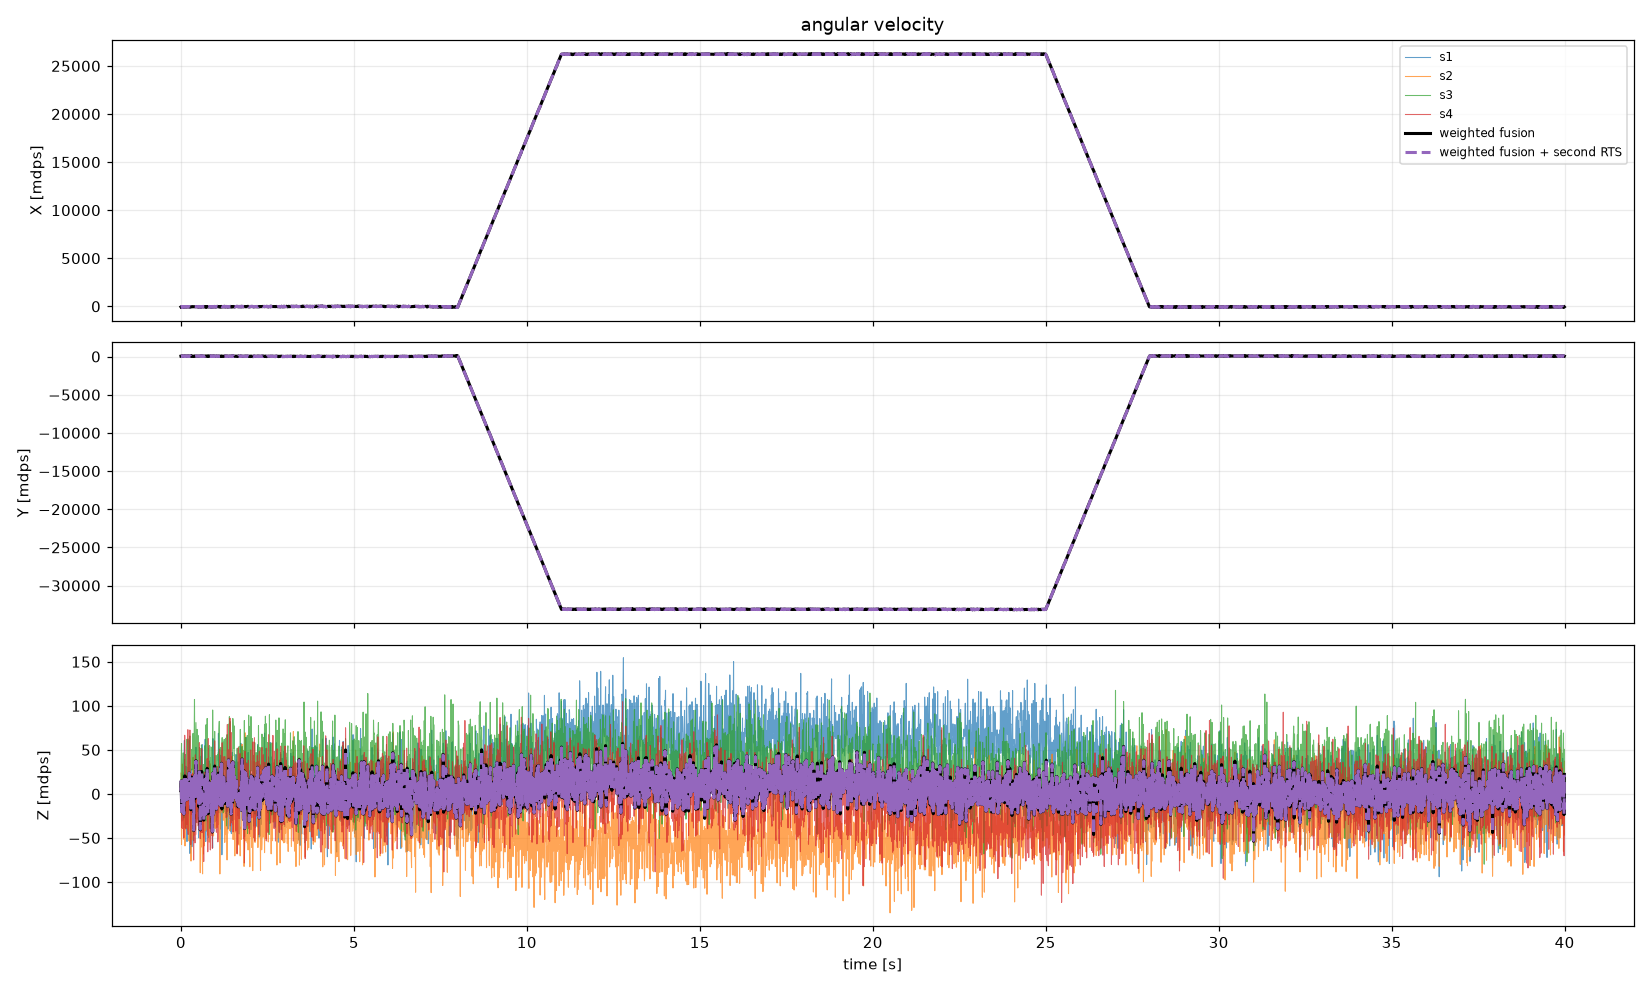

p.png


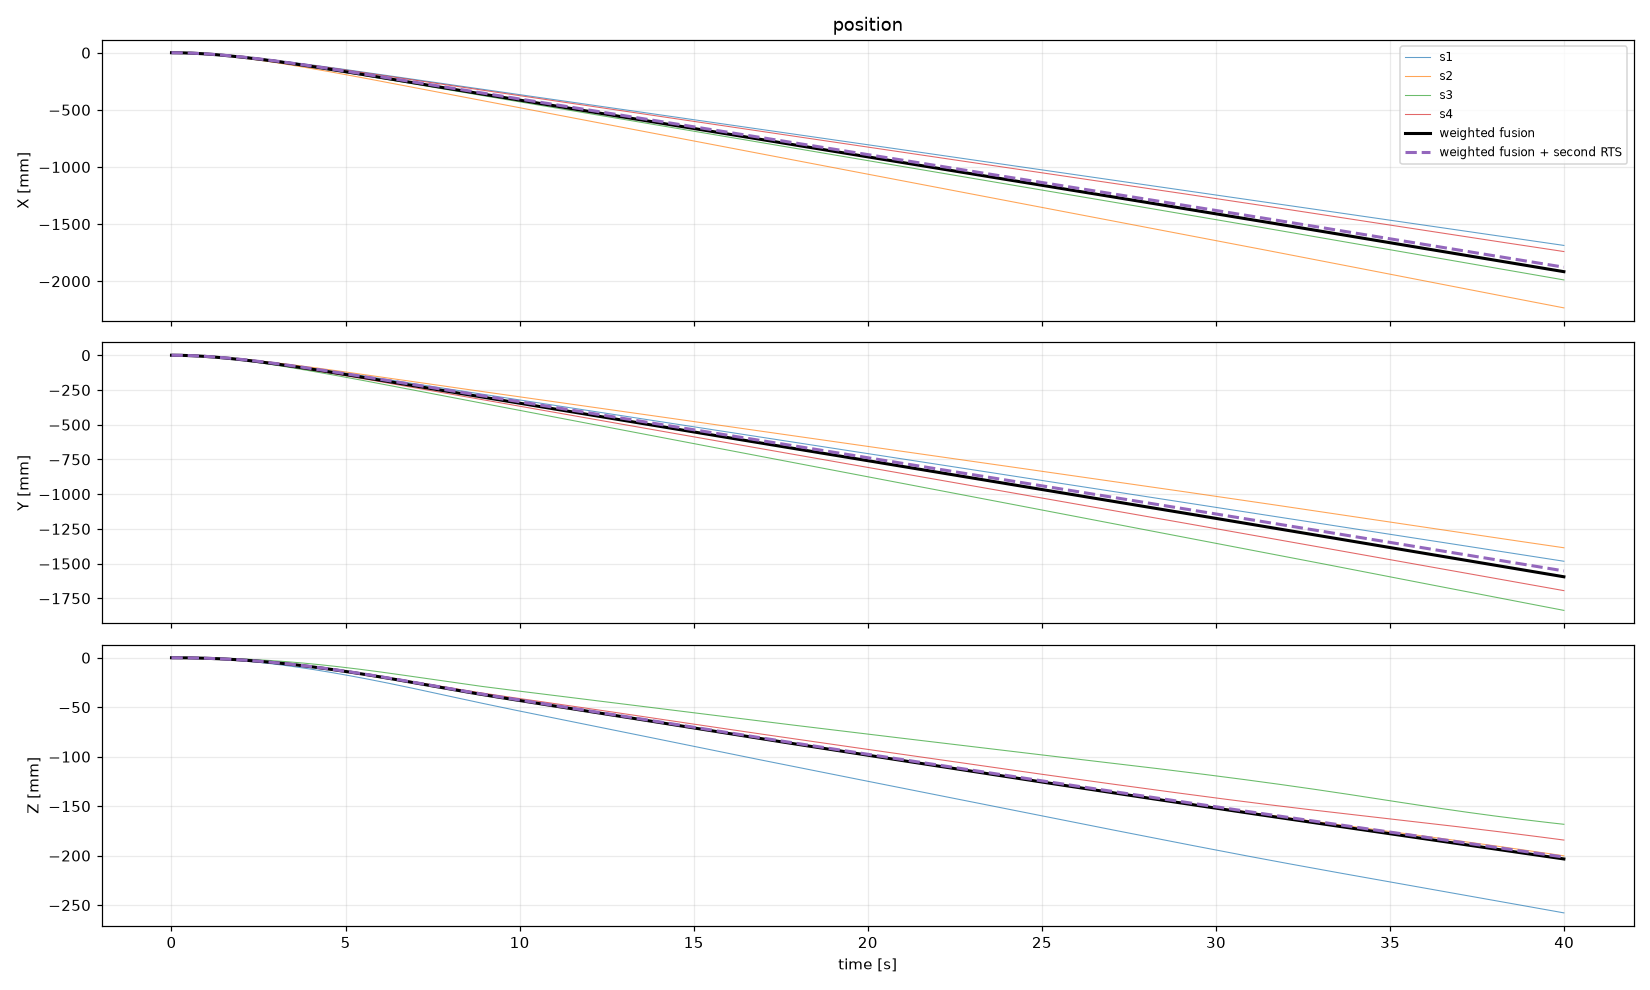

g_norm.png


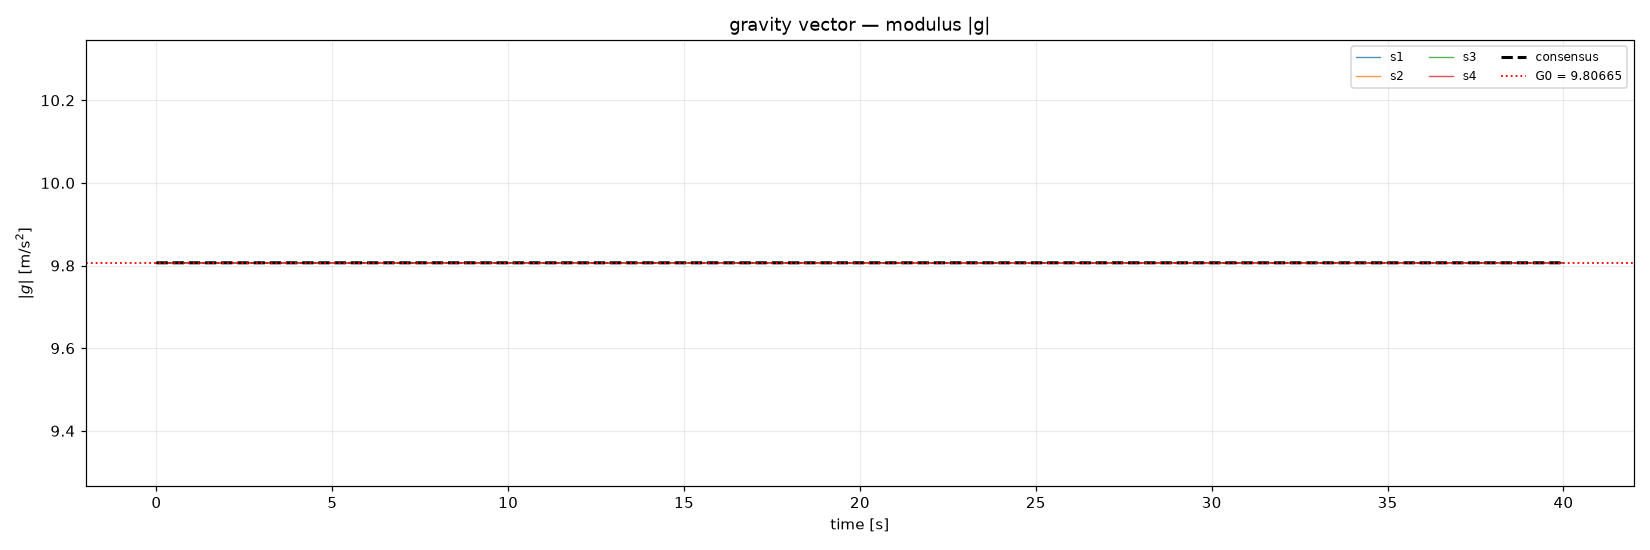

In [67]:
out_dir = sim_out / "simulated_720deg"
print(sorted(p.name for p in out_dir.iterdir() if p.suffix != ".png"), "+", len([p for p in out_dir.iterdir() if p.suffix == ".png"]), "PNG pictures")
for name in ("w.png", "p.png", "g_norm.png"):
    print(name); display(Image(filename=str(out_dir / name), width=900))

### The animated GIF
Left: the trajectory with the plate (colour = single IMU, dashed/black outline = fused). Top right: the rotation alone. Bottom right: position and cumulative rotation
(note the 720° plateau). *(This notebook uses few frames so it stays light; the project writes 220.)*

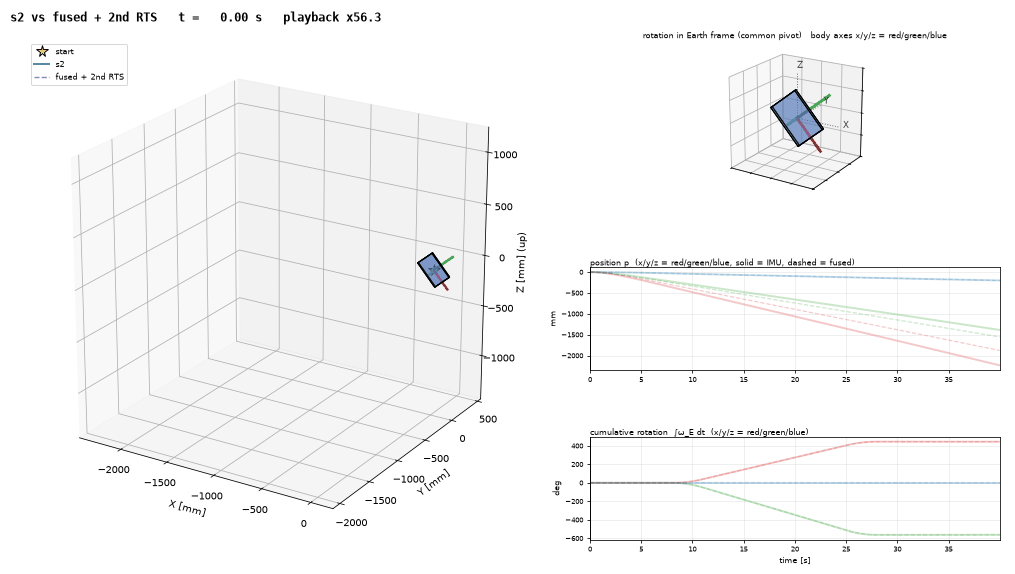

In [68]:
display(Image(filename=str(out_dir / "gifs" / "dynamics_s2_vs_fused.gif")))

### 🔑 What we learn
* The registration recovers the unknown mountings to about 0.1°. Note that the program's *reported* 1-σ (about 0.001°) is roughly a hundred times smaller than this actual error: the covariances come from a filter that does not know about its own modelling errors, so **reported uncertainties are optimistic**. Use them as relative indicators, not as absolute truth.
* **Fusion does not beat the best single IMU here.** In the printout above the fused rotation-rate error (about 0.06°/s) is close to the *typical* single IMU and slightly worse than the best one (s1). Fusion averages away *independent* noise, but most of the remaining error is **systematic and shared by all sensors** (the model lag / bias absorption of Chapter 5, plus registration errors of about 0.1°), and averaging cannot remove a common error. The accelerations tell the same story (all about 0.0077 m/s²). The practical value of fusion is robustness: it stays close to the typical sensor and protects against one bad sensor. The second smoother changes the error only marginally here.
* The cumulative rotation reaches ≈ 720° smoothly (the fused rotation rate keeps its plateau).
* **Position** is the weakest result. Two integrations amplify any small leftover error (Chapter 9), so
  dead-reckoned position drifts. This is a physical limit of inertial sensing, not a bug.

# Chapter 15 — Running it on your real CSV

The cell below uses the **same functions** on your file. Edit the three settings, then run it. It is skipped automatically if the file is not found.

* `REAL_CSV` — path to your CSV (put it in a folder named `DATA` next to the notebook, or write the full path).
* `DT_REAL` — the true time between rows [s]. The sensors run at 120 Hz, so `1/120` (this is also what `get_dt(None)` returns when there is no `config.DT`). The *consistency factor* printed below tells whether the accelerometer's gravity direction and the gyro agree about how much the support turned (Chapter 18.5).
* `ALIGN_S_REAL` — seconds of **still** sensor at the start of the file. It must be shorter than the real still time; in this file the motion starts about 28 s after the start, so 15 s is safe.

In [69]:
REAL_CSV = Path("DATA/20260723_Dinamic_720degree_facex_1.csv")      # <-- edit: path of your CSV
DT_REAL = 1.0 / 120.0                                               # <-- edit: seconds between rows (the retained samples are treated as 120 Hz after repeated rows are dropped)
ALIGN_S_REAL = 15.0                                                 # <-- edit: seconds of still sensor at the start

if REAL_CSV.exists():
    d_real, sens_real, n_real = load_csv(REAL_CSV)
    print(f"{REAL_CSV.name}: {n_real} rows, sensors {sens_real}")
    print("acceleration magnitude at rest [m/s^2] (should be ~9.8):",
          round(float(np.linalg.norm(d_real[sens_real[0]][0][:200].mean(0))), 3))
    dt_sug, fac = suggest_dt(*d_real[sens_real[0]], dt_assumed=DT_REAL)
    print(f"gyro/gravity consistency factor at DT_REAL = {DT_REAL:.6f} s: {fac:.3f}   (1 = the accelerometer's gravity direction and the gyro agree)")
    print("a value well below 1: the gravity direction seen by the accelerometer turns less than the gyro says; the pipeline follows the gyro (Chapter 18.5)")
else:
    print("real CSV not found:", REAL_CSV.resolve(), "-> section skipped (the simulation above already ran the whole pipeline)")

real CSV not found: C:\Users\verga\Desktop\MultiSensorFusion\DATA\20260723_Dinamic_720degree_facex_1.csv -> section skipped (the simulation above already ran the whole pipeline)


In [70]:
if REAL_CSV.exists():
    real_out = Path("outputs_notebook_real")
    summary_real = process_file(
        path=REAL_CSV, out_root=real_out, dt=DT_REAL, align_s=ALIGN_S_REAL,
        second_rts=SECOND_RTS_DEFAULT, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
        registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
        nmax=None, registration_refine_iters=2)
    print(); print(pd.Series(summary_real).to_string())

In [71]:
if REAL_CSV.exists():
    rdir = real_out / REAL_CSV.stem
    rr = np.load(rdir / "results.npz", allow_pickle=True)
    wf = np.rad2deg(rr["w_fused_rts"]); tr = rr["t"]
    print("integrated rotation (sum of w dt) [deg], Earth X,Y,Z:", (wf.sum(0) * tr[1]).round(1))
    for name in ("w.png", "theta.png", "g_norm.png"):
        print(name); display(Image(filename=str(rdir / name), width=900))
    display(Image(filename=str(rdir / "gifs" / "dynamics_s1_vs_fused.gif")))

### Running from the command line instead
Everything above is what the script does when you type
```
python run_general_multisensor_dynamic.py
```
(inputs from the `DATA` folder next to the script, outputs to `outputs_general_dynamic`; options: `--dt`, `--align-s`, `--no-second-rts`, ...).
The command-line wrapper `main()` is shown below for completeness; it only reads the options and calls `process_file` for every CSV found.

In [72]:
def main():
    # Describe the command-line options (each `add_argument` below is one option with a default value).
    ap = argparse.ArgumentParser(description="General arbitrary-N IMU dynamic multisensor pipeline")
    ap.add_argument("--data-dir", default=None, help="Input folder; default is DATA next to this script")
    ap.add_argument("--output-dir", default=None, help="Output folder; default outputs_general_dynamic next to this script")
    ap.add_argument("--pattern", default="*.csv", help="CSV glob pattern inside DATA")
    ap.add_argument("--files", nargs="*", default=None, help="Optional exact filenames relative to DATA")
    ap.add_argument("--dt", type=float, default=None, help="Sample period [s]; default config.DT, else 1/120")
    ap.add_argument("--align-s", type=float, default=DEFAULT_ALIGN_S, help="Initial stationary interval [s]")
    ap.add_argument("--nmax", type=int, default=None)
    ap.add_argument("--no-second-rts", action="store_true", help="Disable the post-fusion 6-state RTS")
    ap.add_argument("--r-inflation", type=float, default=SECOND_RTS_R_INFLATION)
    ap.add_argument("--q-scale", type=float, default=SECOND_RTS_Q_SCALE)
    ap.add_argument("--registration-stride", type=int, default=REGISTRATION_STRIDE)
    ap.add_argument("--active-threshold-dps", type=float, default=REGISTRATION_MIN_ACTIVE_DPS,
                    help="diagnostic activity mask only; registration is covariance-weighted")
    ap.add_argument("--registration-refine-iters", type=int, default=2,
                    help="leave-one-out Gauss-Seidel refinement sweeps (N>=3)")
    # Read what the user typed.
    args = ap.parse_args()

    # Folders: DATA for the input, outputs_general_dynamic for the results.
    root = Path(__file__).resolve().parent
    data_dir = Path(args.data_dir) if args.data_dir else root / "DATA"
    out_dir = Path(args.output_dir) if args.output_dir else root / "outputs_general_dynamic"
    out_dir.mkdir(parents=True, exist_ok=True)
    # Stop with a clear message if the input folder is missing.
    if not data_dir.exists():
        raise FileNotFoundError(f"DATA folder does not exist: {data_dir}")

    # Which CSV files to process: the ones named, or all *.csv in DATA.
    if args.files:
        paths = [data_dir / f for f in args.files]
    else:
        paths = sorted(data_dir.glob(args.pattern))
    paths = [p for p in paths if p.suffix.lower() == ".csv"]
    if not paths:
        raise FileNotFoundError(f"No CSV files found in {data_dir} matching {args.pattern!r}")

    # Sample period (option, else config.DT, else 1/120 s).
    dt = get_dt(args.dt)
    summaries = []
    # Run the whole pipeline on every file.
    for path in paths:
        summaries.append(process_file(
            path=path,
            out_root=out_dir,
            dt=dt,
            align_s=args.align_s,
            second_rts=not args.no_second_rts,
            r_inflation=args.r_inflation,
            q_scale=args.q_scale,
            registration_stride=args.registration_stride,
            active_thr_dps=args.active_threshold_dps,
            nmax=args.nmax,
            registration_refine_iters=args.registration_refine_iters,
        ))
    # Write one summary table for the whole batch.
    pd.DataFrame(summaries).to_csv(out_dir / "batch_summary.csv", index=False)
    print(f"\nProcessed {len(summaries)} CSV file(s). Batch summary: {out_dir / 'batch_summary.csv'}", flush=True)

# Chapter 16 — Reading the results, and a troubleshooting guide

### Files written for every input CSV
| File | What it is |
|---|---|
| `a.png`, `w.png`, `v.png`, `p.png`, `theta.png` | acceleration, rotation rate, velocity, position, angle in the **Earth frame**: one thin line per IMU, black = weighted fusion, dashed purple = + second RTS |
| `*_fusion_compare.png` | only the two fused curves, to judge the second smoother |
| `p_norm.png`, `theta_norm.png` (+ `..._fusion_compare.png`) | distance from the start and total rotation (lengths of the vectors) |
| `ba.png`, `bw.png`, `g.png` | biases and gravity of each IMU (diagnostics; not fused) |
| `g_norm.png` | history of $\|\mathbf g\|$: flat at $G_0$ |
| `gifs/dynamics_sN_vs_fused.gif` | animation of IMU N versus the fused result |
| `results.npz` | all main arrays (Earth-frame states, covariances, registrations, fused results) |
| `filter_diagnostic.csv`, `summary.csv` | quick numbers: raw vs estimated rate, registration uncertainty, final position/angle |

### Troubleshooting
| Symptom | Likely cause | What to check |
|---|---|---|
| Rotation rate decays instead of staying flat, biases huge | acceleration read in the wrong unit, or priors that let the filter explain rotation as bias | acceleration magnitude at rest ≈ 9.8 m/s²? (Chapter 11); use `make_cfg` safeguards (Chapter 5) |
| Total rotation is not what you expect (e.g. 2 turns instead of 9) | wrong `dt`, or a gyro scale-factor error | the consistency diagnostic (Chapters 11 and 18.5) and the nine-turn tests of Part III |
| Estimates look strange right from the start | `align_s` longer than the still period | reduce `align_s` |
| Warning about registration "weakest direction" | motion did not excite one direction (e.g. a turn about the vertical was never seen) | add rotations about several axes, or accept larger uncertainty |
| Position drifts by metres | normal: double integration of small errors | Chapter 1 and 9; compare IMUs, not absolute values |
| GIF very slow to produce | many frames and plots | reduce `MAX_FRAMES` (notebook) or the 220 frames in `imu_gifs.py` |

### Assumptions to keep in mind
* All sensors are **synchronised** (same row = same instant) and rigidly attached with **constant** relative orientation.
* They measure the **same angular velocity**. Translational accelerations are fused assuming the sensors are (nearly) at the same point; with a significant lever arm
  $\mathbf r_i$ the accelerations differ by $\boldsymbol\alpha\times\mathbf r_i+\boldsymbol\omega\times(\boldsymbol\omega\times\mathbf r_i)$ and must be corrected first.
* **Yaw at the start is a convention (0)**: gravity cannot tell the compass heading.
* The second smoother is a practical temporal regulariser, not an exact Bayesian smoother.
* Biases absorb model imperfections; do not over-interpret their individual values (Chapter 5).
* Reported covariances and 1-σ values are optimistic: they ignore systematic model errors (Chapter 14).

# PART III — Validation on real measurement tests

Until now the pipeline was explained and checked on a *simulated* experiment, where we invented the truth. Here we ask the real question:
**when four real IMUs are put through experiments whose true outcome is known, how large are the errors of the pipeline?**
The CSV files of the test campaign live in the folder `DATA`, next to this notebook. Nothing in the pipeline changes — we use `process_file`
exactly as before and then compare its outputs with what *physically must be true*.

# Chapter 17 — The test campaign: setup and what must be true

### 17.1 The fifteen experiments
All files are from the same session (`20260723_...`). Each CSV holds the readings of the four IMUs `s1 ... s4` fixed on the same rigid support.
The letter in the file name (`x`, `y`, `z`, written `X`, `Y`, `Z` in some names) tells which face / axis of the support was placed as
described in the test log. **Our error measures use only the *lengths* (moduli) of vectors, which do not depend on which axis is which**, so the analysis
needs no axis bookkeeping.

| Group | File name pattern | What the support does | What must be true |
|---|---|---|---|
| **A. Static** | `20260723_Static_face{x,y,z}.csv` | nothing: it rests on one face (gravity and the Earth's rotation act on it) | position stays at the origin, velocity 0, **no rotation** |
| **B. Sine on a face** | `20260723_Dinamic_sine_face{x,y,z}_0.csv` | rotates following the angle profile $A(\tau)$ below | position at the origin; $\lVert\text{angular position}\rVert$ follows $\lvert A\rvert$ |
| **C. Sine, rotation axis** | `20260723_Dinamic_sine_face_rot{X,Y,Z}_0.csv` | same profile, with rotation about the axis in the name | same as B |
| **D. Nine turns on a face** | `20260723_Dinamic_720degree_face{x,y,z}_1.csv` | constant-rate rotation, about **2 full turns** (720°) | position at the origin; cumulative angle rises **linearly then saturates** at ≈ 2 × 360° |
| **E. Nine turns, rotation axis** | `20260723_Dinamic_720degree_face_rot{Y,Z,x}_*.csv` | about **2 full turns about the vertical (Earth Z)** | same as D |

The sine profile (angle in degrees, $\tau$ in seconds since the motion starts):
$$
A(\tau)=-30\,\sin(2\pi\cdot0.10\,\tau)\;-\;5\,\sin(2\pi\cdot0.75\,\tau).
$$
A slow 30° swing at 0.10 Hz with a faster 5° ripple at 0.75 Hz on top; its largest value is a little below 35°.

> **Name warning.** The files called `720degree` contain **about 9 turns, not 2** (the "720" in the name is not the total angle). The notebook uses the
> campaign description, `TURNS_EXPECTED = 9`; change it at the top of the settings cell if your log says otherwise.
> The folder may contain only some of the files: the code looks for every pattern and silently skips what is missing.

### 17.2 The key ideas behind "what must be true"

1. **The support never translates.** Whatever the rotation, the sensors sit (nearly) on the rotation axis and nobody moves the support:
   the true position is the origin and the true velocity is zero *for all fifteen tests*. Any non-zero position the pipeline reports is an **error**.
   This is a harsh but honest test: position comes from integrating acceleration twice (Chapter 1), so every small bias grows like $\tfrac12\,b\,t^2$.
2. **The angular position is described by a rotation vector** $\hat{\boldsymbol\theta}(t)$ (axis × angle, Chapter 9) and its length $m(t)=\lVert\hat{\boldsymbol\theta}(t)\rVert\in[0^\circ,180^\circ]$.
   For a rotation about a fixed axis $m$ is the absolute rotation angle **as long as it is below 180°**. Beyond that it *wraps*, so for the nine-turn tests we also use the
   *cumulative* angle $C(t)=\int_0^t\lVert\hat{\boldsymbol\omega}\rVert\,d\tau$, which never wraps.
3. **The Earth rotates too.** At rest a perfect gyroscope reads the Earth's rotation, 15.04 °/hour ≈ 4.2 mdps (milli-degrees per second) times a factor of the
   latitude. This is far below the gyro noise, and it is **absorbed into the gyro bias estimated during the initial still interval** (Chapter 4.8): relative to the Earth the true
   angle of a static support is 0, and that is the reference we use. (Integrated over 4 minutes the Earth rate alone would be ≈ 1°; that is exactly why it must not be
   left uncompensated.)
4. **A full number of turns brings the support back to where it started.** After exactly 9 turns the attitude is identical to the initial one, so the final rotation vector must be ≈ 0.
   This *closure* is a powerful check that does not need a reference curve at all.

# Chapter 18 — How the errors are computed

For each test and each **track** — the four single IMUs `s1 ... s4`, the **weighted fusion** (`fused`) and the **fusion + second RTS** (`fused_rts`) — we start from
the Earth-frame results the pipeline saved (`results.npz`): position $\hat{\mathbf p}(t)$, velocity $\hat{\mathbf v}(t)$, rotation vector $\hat{\boldsymbol\theta}(t)$ and rotation rate $\hat{\boldsymbol\omega}(t)$.
The sample period is $\Delta t=1/120$ s, the observation time $T$, and $N$ the number of samples.

### 18.1 Errors valid for every test (the support stays at the origin)
$$
e_p(t)=\lVert\hat{\mathbf p}(t)\rVert\ [\text{mm}],\qquad e_v(t)=\lVert\hat{\mathbf v}(t)\rVert\ [\text{mm/s}] .
$$
They are lengths, so they are never negative and have no sign. For each curve we report three numbers:

| Number | Definition | Why |
|---|---|---|
| **final** | value at the last sample, $e(T)$ | what you would have if you stopped now |
| **max** | $\max_t e(t)$ | worst moment |
| **rms** | $\sqrt{\tfrac1N\sum_k e(t_k)^2}$ | overall size, dominated by large values |

### 18.2 Group A — static tests
True angular position $=0$, so $e_\theta(t)=m(t)=\lVert\hat{\boldsymbol\theta}(t)\rVert$ (degrees), reported as final / max / rms over the whole record.
Because the truth is "constant zero", the final values translate directly into **equivalent constant biases** — the single most useful way to read a static test:
$$
\text{a constant accelerometer bias } b \Rightarrow e_p=\tfrac12\,b\,t^2\ \ \Rightarrow\ \ b_{a,\mathrm{eq}}=\frac{2\,e_p(T)}{T^2}\ [\text{mm/s}^2],
\qquad
\text{a constant gyro bias } \beta \Rightarrow e_\theta=\beta\,t\ \ \Rightarrow\ \ \beta_{\mathrm{eq}}=\frac{e_\theta(T)}{T}\ [\text{mdps}] .
$$
These tell how much *uncorrected* bias is left after the filters, to be compared with the sensor's data-sheet bias stability.

### 18.3 Groups B and C — sine tests
The reference modulus is $r(t)=\lvert A(t-t_0)\rvert$ after the motion has started at an unknown instant $t_0$; and $r(t)=0$ before.
1. **Finding the start.** From the fused rotation rate: smooth $\lVert\hat{\boldsymbol\omega}\rVert$ over 1 s and take the first instant above `MOTION_THR_DPS` (2°/s) as a first guess $t_0^{\,\mathrm{guess}}$; the last such instant gives the end of the motion $t_{\mathrm{end}}$.
2. **Refining $t_0$.** The guess can be off by a fraction of a second. We scan $t_0\in[t_0^{\,\mathrm{guess}}-1.5\,\mathrm{s},\,t_0^{\,\mathrm{guess}}+1.5\,\mathrm{s}]$ in steps of 10 ms and keep the value that minimises the RMS difference
   between the *fused + RTS* modulus and $r$. The **same $t_0$ is then used for all six tracks**, so no single IMU gets a private alignment.
   *(A start-time search can hide a timing offset but cannot hide an amplitude error; both appear in the numbers.)*
3. **The angle error** is $e_\theta(t)=m(t)-r(t)$, evaluated between $t_0$ and $t_{\mathrm{end}}$ → final, max, rms, and the relative size $\text{rms}/\max_t r(t)$ in percent.
   It is **signed** (positive: the estimate over-rotates), so plots show bias-like behaviour.
4. **After the end of the motion** the support stays at its last angle, so the reference stays constant at $r(t_{\mathrm{end}})$ (it is *not* continued as a sine). The **end residual** $m(T)-r(T)$ checks that the estimate also stays put once the rotation has stopped (when the profile ends at a multiple of 10 s the final angle is 0 and the support is back at its starting attitude).

### 18.4 Groups D and E — nine-turn tests
Let $C(t)=\int_0^t\lVert\hat{\boldsymbol\omega}\rVert\,d\tau$ in degrees. The expected behaviour is a **ramp** (constant rotation rate) followed by a **plateau** at $9\times360^\circ=3240^\circ$.

| Measure | Definition | Reading |
|---|---|---|
| turns | $C(T)/360$ | should be ≈ 9 |
| error vs 9 turns | $C(T)-3240^\circ$ (and in %) | scale/gain error of the gyro path |
| fractional-turn error | distance of $C(T)/360$ from the **nearest integer**, ×360° | residual if the rig made *some* integer number of turns |
| closure | $\lVert\hat{\boldsymbol\theta}(T)\rVert$ | final attitude minus initial attitude; ≈ 0 after whole turns |
| linearity | straight-line fit $C(t)\approx s\,(t-t_a)+c$ on the middle 80 % of the motion window → slope $s$ [°/s], residual rms and max [°], and $R^2$ | is the ramp really linear? |
| creep after motion | $C(T)-C(t_b)$ | the angle should *saturate*: any growth after the rotation stopped is drift |
| position, velocity | as 18.1 | the support did not move |

### 18.5 Two diagnostics that are not errors but explain them
* **Gyro-versus-gravity consistency $\kappa$.** Over windows of 1 s, how much does the *gravity direction* seen by the accelerometer turn, compared with how much the *gyro* says the support turned (assuming $\Delta t=1/120$ s)?
  $$\kappa=\operatorname{P}_{90}\!\left[\frac{\text{angle turned by the accelerometer's gravity direction}}{\Delta t\sum\lVert\boldsymbol\omega_{\text{gyro}}\rVert}\right],\quad\kappa\approx1\ \text{when both agree}.$$
  A value far from 1 means that the two sensors (or the assumed sample period) disagree about how much the support turned. The pipeline trusts the gyro for rotation.
  It is **not defined** (shown as `NaN`) for the static tests (no rotation) and for group E: a rotation about the *vertical* does not change the gravity direction at all, so the accelerometer cannot be compared with the gyro.
* **$\lVert\mathbf g\rVert-G_0$.** The gravity-modulus constraint (Chapter 10) must hold exactly; we print the largest deviation as a self-check (it should be ≈ 0).

### 18.6 Fusion benefit
For any error $E$ (e.g. final position error) the **improvement ratio** is $\operatorname{median}_i(E_{s_i})/E_{\text{fused}}$. A value above 1 means the fused estimate is better than the typical single IMU. (Chapter 14 showed that
fusion cannot remove errors that are *common* to all sensors, so ratios close to 1 are normal.)

# Chapter 19 — Code: settings, finding the files, running the pipeline

### 💻 19.1 Settings (edit here)

In [73]:
# ======================= Chapter 19: settings of the validation campaign (edit here) =======================
VAL_DIR  = Path("DATA")                    # folder with the real measurement CSV files (next to this notebook)
VAL_OUT  = Path("outputs_validation")      # folder where results (npz, pictures, tables) are written
DT_VAL   = 1.0 / 120.0                     # time between retained rows [s]: 120 Hz after consecutive duplicate rows are removed
ALIGN_MAX_S = 10.0                         # maximum seconds of 'still sensor' used for the start values
MOTION_THR_DPS = 2.0                       # rotation faster than this [deg/s] counts as 'moving'
TURNS_EXPECTED = 2                         # number of full turns of the 720degree tests (from the test log)
SINE_TERMS = ((-30.0, 0.10), (-5.0, 0.75)) # the sine profile  A(tau) = sum of amplitude[deg] * sin(2 pi f tau), f in Hz
GIFS_IN_VALIDATION = False                 # True = also write the animated GIFs for every test (slow: minutes per file)
FORCE_RERUN = False                        # True = recompute even if a saved results.npz already exists
print("looking for CSV files in:", VAL_DIR.resolve(), "| results go to:", VAL_OUT.resolve())

looking for CSV files in: C:\Users\verga\Desktop\MultiSensorFusion\DATA | results go to: C:\Users\verga\Desktop\MultiSensorFusion\outputs_validation


### 💻 19.2 Finding the test files
The five groups are described by *patterns* (regular expressions) on the file names. Upper/lower case does not matter (`rotY` / `roty`), and
the number after `rot{X}_` may be anything (`_1`, `_2`, ...). `discover_tests` returns one entry per file found.

In [74]:
# ======================= which files belong to which group =======================
TEST_GROUPS = {
    # key         : (title shown in the tables,         file-name pattern,                                      kind of expected behaviour)
    "static"      : ("A. Static",                       r"^20260723_Static_face([xyz])\.csv$",                  "rest"),
    "sine_face"   : ("B. Sine, face",                   r"^20260723_Dinamic_sine_face([xyz])_0\.csv$",          "sine"),
    "sine_rot"    : ("C. Sine, rotation axis",          r"^20260723_Dinamic_sine_face_rot([xyz])_0\.csv$",      "sine"),
    "turns_face"  : ("D. Nine turns, face",             r"^20260723_Dinamic_720degree_face([xyz])_1\.csv$",     "turns"),
    "turns_rot"   : ("E. Nine turns, rotation axis",    r"^20260723_Dinamic_720degree_face_rot([xyz])_\d+\.csv$", "turns"),
}

def discover_tests(folder):
    # Look at every CSV in the folder and see which group (if any) its name matches.
    files = sorted(Path(folder).glob("*.csv"))                    # all CSV files, alphabetical
    tests = []
    for key, (title, pattern, kind) in TEST_GROUPS.items():       # try each group in turn
        rx = re.compile(pattern, re.IGNORECASE)                   # compile the pattern (ignore upper/lower case)
        for p in files:
            m = rx.match(p.name)                                  # does this file name match the pattern?
            if m:                                                 # yes: remember it
                tests.append(dict(group=key, title=title, kind=kind, axis=m.group(1).upper(), path=p, name=p.stem))
    return tests

tests = discover_tests(VAL_DIR)
print(f"{len(tests)} test file(s) found:")
for tst in tests:
    print(f"   {tst['title']:28s} axis {tst['axis']}   {tst['path'].name}")
missing = [t for t, (_, _, _) in TEST_GROUPS.items() if not any(x['group'] == t for x in tests)]
if missing: print("groups with NO file found (skipped):", missing)

4 test file(s) found:
   A. Static                    axis X   20260723_Static_facex.csv
   B. Sine, face                axis X   20260723_Dinamic_sine_facex_0.csv
   C. Sine, rotation axis       axis X   20260723_Dinamic_sine_face_rotX_0.csv
   E. Nine turns, rotation axis axis X   20260723_Dinamic_720degree_face_rotx_2.csv
groups with NO file found (skipped): ['turns_face']


### 💻 19.3 Helpers: choosing the still interval, the consistency factor, running one test
* `auto_align_seconds` decides how many seconds at the start can safely be used as the **still** interval for the start values (Section 4.8). It looks for the first instant at which the gyro departs from its
  initial resting value; 80 % of that time (at most `ALIGN_MAX_S`, at least 1 s) is used. This prevents a file in which motion starts early from being "initialised" in the middle of a movement.
* `gyro_gravity_factor` is the factor $\kappa$ of Section 18.5.
* `gifs_disabled` is a small *context manager*: inside a `with gifs_disabled(): ...` block the GIF step of `process_file` does nothing (the numbers are unaffected). It exists only to save time — set `GIFS_IN_VALIDATION = True` to keep the GIFs.
* `run_one_test` runs `process_file` on one file with the campaign settings, unless a saved result already exists (so a second run of the notebook takes seconds).

In [75]:
from contextlib import contextmanager

def auto_align_seconds(gyro, dt, max_s=ALIGN_MAX_S, thr_dps=1.0):
    # How many seconds at the start of the file is the sensor really still?
    n_base = max(2, int(1.0 / dt))                                  # the first second defines the 'resting' gyro reading
    base = np.median(gyro[:n_base], axis=0)                         # typical resting reading of the three axes
    dev = np.rad2deg(np.linalg.norm(gyro - base, axis=1))           # how far every reading is from that resting value [deg/s]
    k = int(0.2 / dt) + 1                                           # smooth over ~0.2 s so single noisy samples are ignored
    smooth = np.convolve(dev, np.ones(k) / k, mode="same")
    moving = np.where(smooth > thr_dps)[0]                          # instants at which the gyro clearly departs
    still_s = moving[0] * dt if len(moving) else len(gyro) * dt     # time of the first departure (whole file if never)
    return float(np.clip(0.8 * still_s, 1.0, max_s))                # use 80 % of it, between 1 s and max_s


def gyro_gravity_factor(acc, gyro, dt, win_s=1.0, min_deg=3.0):
    # kappa of Section 18.5: angle turned by the accelerometer's gravity direction / angle integrated from the gyro.
    m = max(2, int(round(win_s / dt)))                              # window length in samples
    if len(acc) < 3 * m:
        return float("nan")
    u = acc / np.maximum(np.linalg.norm(acc, axis=1, keepdims=True), 1e-12)        # gravity DIRECTION (unit vectors)
    ang = np.arccos(np.clip(np.einsum("ij,ij->i", u[:-m], u[m:]), -1, 1))          # angle the direction turned in each window
    cs = np.r_[0.0, np.cumsum(np.linalg.norm(gyro, axis=1))]
    gyro_angle = (cs[m:] - cs[:-m])[:len(ang)] * dt                                # angle the gyro integrates in the same window
    ok = gyro_angle > np.deg2rad(min_deg)                                          # only windows with real rotation
    if ok.sum() < 10:
        return float("nan")                                                        # (static tests: not defined)
    return float(np.percentile(ang[ok] / gyro_angle[ok], 90))


@contextmanager
def gifs_disabled(disable=True):
    # While active, make_dynamics_gifs (called inside process_file) does nothing.
    global make_dynamics_gifs
    original = make_dynamics_gifs                                   # remember the real function
    if disable:
        make_dynamics_gifs = lambda *args, **kwargs: None           # replace it by one that does nothing
    try:
        yield
    finally:
        make_dynamics_gifs = original                               # always put the real function back


def run_one_test(test, force=False):
    # Run the whole pipeline on one test file (unless a saved result already exists). Returns the path of results.npz.
    npz = VAL_OUT / test["path"].stem / "results.npz"
    data, sensors, n = load_csv(test["path"])                       # raw data, to choose settings and compute kappa
    acc, gyro = data[sensors[0]]
    test["kappa"] = gyro_gravity_factor(acc, gyro, DT_VAL)          # diagnostic (see Section 18.5)
    if test["group"] == "turns_rot":                                # rotation about the VERTICAL: the gravity direction does not
        test["kappa"] = float("nan")                                # change at all, so kappa has no meaning here
    test["align_s"] = auto_align_seconds(gyro, DT_VAL)              # still interval to use for this file
    test["n_samples"], test["duration_s"] = n, max(n - 1, 0) * DT_VAL
    if npz.exists() and not force:
        test["status"] = "cached"
        return npz
    with gifs_disabled(not GIFS_IN_VALIDATION):
        process_file(path=test["path"], out_root=VAL_OUT, dt=DT_VAL, align_s=test["align_s"],
                     second_rts=SECOND_RTS_DEFAULT, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
                     registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
                     nmax=None, registration_refine_iters=2)
    test["status"] = "computed"
    return npz

### 💻 19.4 Run all the tests
Each file takes roughly the same time as the real run of Chapter 15 (about 1–2 minutes). Results are saved, so you only pay this once.

In [76]:
# ======================= run the pipeline on every test file found =======================
VAL_OUT.mkdir(exist_ok=True)
npz_paths = {}
for tst in tests:
    print(f"\n#### {tst['name']}  ({tst['title']}, axis {tst['axis']})")
    npz_paths[tst["name"]] = run_one_test(tst, force=FORCE_RERUN)
    k = tst["kappa"]
    print(f"     status: {tst['status']} | duration {tst['duration_s']:.0f} s | still interval used: {tst['align_s']:.1f} s | "
          f"gyro/gravity factor kappa: {'n/a (no rotation)' if np.isnan(k) else f'{k:.3f}'}")


#### 20260723_Static_facex  (A. Static, axis X)

=== 20260723_Static_facex.csv: 12813 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.935 0.007 0.006]
  registration s3->s1: 1-sigma [deg] = [0.873 0.006 0.005]
  registration s4->s1: 1-sigma [deg] = [0.869 0.006 0.005]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved outputs_validation\20260723_Static_facex
     status: computed | duration 107 s | still interval used: 10.0 s | gyro/gravity factor kappa: n/a (no rotation)

#### 20260723_Dinamic_sine_facex_0  (B. Sine, face, axis X)

=== 20260723_Dinamic_sine_facex_0.csv: 11842 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.001 0.001 0.   ]
  registration s3->s1: 1-sigma [deg] = 

C:\Users\verga\AppData\Local\Temp\ipykernel_28768\1606504197.py:34: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(path, dpi=110)
C:\Users\verga\AppData\Local\Temp\ipykernel_28768\843802570.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)


  saved outputs_validation\20260723_Dinamic_sine_facex_0
     status: computed | duration 99 s | still interval used: 10.0 s | gyro/gravity factor kappa: 1.007

#### 20260723_Dinamic_sine_face_rotX_0  (C. Sine, rotation axis, axis X)

=== 20260723_Dinamic_sine_face_rotX_0.csv: 10634 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.062 0.001 0.   ]
  registration s3->s1: 1-sigma [deg] = [0.081 0.001 0.   ]
  registration s4->s1: 1-sigma [deg] = [0.078 0.001 0.   ]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved outputs_validation\20260723_Dinamic_sine_face_rotX_0
     status: computed | duration 89 s | still interval used: 10.0 s | gyro/gravity factor kappa: 0.124

#### 20260723_Dinamic_720degree_face_rotx_2  (E. Nine turns, rotation axis, axis X)

=== 20260723_Dinamic_720degree_face_rotx_2.csv: 6195

# Chapter 20 — Code: loading the results and computing the errors

### 💻 20.1 Loading the tracks
`load_tracks` reads `results.npz` and arranges, for each of the six tracks, the four arrays used by the error formulas. Positions are converted to mm, velocities to mm/s and angles to degrees **only for reporting**.

In [77]:
def load_tracks(npz_path):
    # Read a results.npz and return (time axis, dt, tracks); tracks[name] = dict(p, v, theta, w, gdev).
    res = np.load(npz_path, allow_pickle=True)
    t = res["t"]; dt = float(t[1] - t[0])
    sensors = [str(s) for s in res["sensors"]]                      # e.g. ['s1','s2','s3','s4']
    tracks = {}
    for s in sensors:                                               # the individual IMUs
        tracks[s] = dict(p=res[f"{s}_p"] * 1e3,                     # position  [mm]
                         v=res[f"{s}_v"] * 1e3,                     # velocity  [mm/s]
                         theta=np.rad2deg(res[f"{s}_theta"]),       # rotation vector [deg] (axis x angle, wraps at 180)
                         w=np.rad2deg(res[f"{s}_wE"]),              # rotation rate in Earth axes [deg/s]
                         gdev=np.abs(np.linalg.norm(res[f"{s}_gE"], axis=1) - G0))   # | |g| - G0 |  [m/s^2]
    for name, suf in (("fused", ""), ("fused_rts", "_rts")):        # the two fused results
        if f"p_fused{suf}" in res.files:
            tracks[name] = dict(p=res[f"p_fused{suf}"] * 1e3, v=res[f"v_fused{suf}"] * 1e3,
                                theta=np.rad2deg(res[f"theta_fused{suf}"]), w=np.rad2deg(res[f"w_fused{suf}"]),
                                gdev=np.zeros(len(t)))              # fused results carry no separate gravity vector
    return t, dt, tracks

TRACK_STYLE = {"fused": dict(color="black", lw=2.4, ls="-", label="weighted fusion"),
               "fused_rts": dict(color="tab:purple", lw=2.0, ls="--", label="fusion + 2nd RTS")}
def style_of(name, order):
    # Plot style of a track: the fused ones are bold, each IMU gets its own colour.
    if name in TRACK_STYLE: return TRACK_STYLE[name]
    return dict(color=GIF_COLORS[order % len(GIF_COLORS)], lw=0.9, ls="-", label=name)

### 💻 20.2 Small building blocks of the error formulas

In [78]:
def summarize(e, mask=None):
    # final / max / rms of an error curve e(t) (Section 18.1). `mask` selects the samples to use for max and rms.
    e = np.asarray(e, float)
    x = e if mask is None else e[mask]
    return dict(final=float(e[-1]), max=float(np.max(np.abs(x))), rms=float(np.sqrt(np.mean(x ** 2))))


def motion_window(w_deg, dt, thr_dps=MOTION_THR_DPS, smooth_s=1.0):
    # First and last sample at which the (1 s smoothed) rotation-rate magnitude exceeds the threshold; None if never.
    mag = np.linalg.norm(w_deg, axis=1)
    k = max(1, int(round(smooth_s / dt)))
    sm = np.convolve(mag, np.ones(k) / k, mode="same")              # moving average = 'is it moving?' signal
    idx = np.where(sm > thr_dps)[0]
    return None if len(idx) == 0 else (int(idx[0]), int(idx[-1]))


def cumulative_angle_deg(w_deg, dt):
    # C(t) = integral of the rotation-rate magnitude: total angle swept so far (never wraps). [deg]
    return np.cumsum(np.linalg.norm(w_deg, axis=1)) * dt


def sine_reference_deg(tau):
    # The reference angle profile A(tau) [deg]; tau = time since the motion started (0 before that).
    tau = np.asarray(tau, float)
    A = sum(a * np.sin(2 * np.pi * f * tau) for a, f in SINE_TERMS)
    return np.where(tau >= 0, A, 0.0)


def common_rows(tr, mask=None):
    # Position and velocity error numbers (valid for every test: the support stays at the origin).
    ep = np.linalg.norm(tr["p"], axis=1)                            # e_p(t) [mm]
    ev = np.linalg.norm(tr["v"], axis=1)                            # e_v(t) [mm/s]
    sp, sv = summarize(ep), summarize(ev)
    return ep, ev, {"pos_final_mm": sp["final"], "pos_max_mm": sp["max"], "pos_rms_mm": sp["rms"],
                    "vel_final_mmps": sv["final"], "vel_max_mmps": sv["max"], "vel_rms_mmps": sv["rms"],
                    "gdev_max_ums2": 1e6 * float(np.max(tr["gdev"]))}

### 💻 20.3 Group A — static tests

In [79]:
def analyse_static(t, dt, tracks):
    # Errors of a static test: true position, velocity and angle are all 0.
    T = t[-1]                                                       # observation time [s]
    rows, curves = {}, {}
    for name, tr in tracks.items():
        ep, ev, row = common_rows(tr)
        m = np.linalg.norm(tr["theta"], axis=1)                     # e_theta(t) = |theta(t)|  [deg]
        s = summarize(m)
        row.update(ang_final_deg=s["final"], ang_max_deg=s["max"], ang_rms_deg=s["rms"])
        row["equiv_acc_bias_mmps2"] = 2 * row["pos_final_mm"] / T ** 2         # b_eq = 2 e_p(T) / T^2   (Section 18.2)
        row["equiv_gyro_bias_mdps"] = 1e3 * s["final"] / T                     # beta_eq = e_theta(T) / T  [milli-deg/s]
        rows[name] = row
        curves[name] = dict(ep=ep, ev=ev, ang=m)
    return pd.DataFrame(rows).T, dict(curves=curves, T=T)

### 💻 20.4 Groups B and C — sine tests
The function first finds the start of the motion, then refines it (Section 18.3), then evaluates every track against the same reference curve.

In [80]:
def analyse_sine(t, dt, tracks):
    # Errors of a sine test: modulus of the angular position vs |A(t - t0)|.
    ref_tr = tracks.get("fused_rts", tracks["fused"])               # the fused curve is used to find the motion
    win = motion_window(ref_tr["w"], dt)
    if win is None:
        raise RuntimeError("no motion found in this file (rotation rate never above the threshold)")
    i0, i1 = win
    t0_guess, t_end = t[i0], t[i1]                                  # first guess of the start, and the end of the motion
    m_ref_track = np.linalg.norm(ref_tr["theta"], axis=1)           # modulus of the fused angular position

    # --- refine the start time t0 on a grid of +-1.5 s (10 ms steps): minimise the RMS misfit of the fused curve
    best = (np.inf, t0_guess)
    for t0 in np.arange(t0_guess - 1.5, t0_guess + 1.5 + 1e-9, 0.01):
        r = np.abs(sine_reference_deg(t - t0))                      # reference modulus for this candidate start
        sel = (t >= t0) & (t <= t_end)                              # compare only while moving
        if sel.sum() < 10: continue
        rms = np.sqrt(np.mean((m_ref_track[sel] - r[sel]) ** 2))
        if rms < best[0]: best = (rms, t0)
    t0 = best[1]
    r = np.abs(sine_reference_deg(np.minimum(t, t_end) - t0))       # final reference modulus r(t): after t_end the support
                                                                    # stays at its last angle, so the reference stays constant
    sel = (t >= t0) & (t <= t_end)                                  # evaluation window

    rows, curves = {}, {}
    for name, tr in tracks.items():
        ep, ev, row = common_rows(tr)
        m = np.linalg.norm(tr["theta"], axis=1)                     # modulus of this track's angular position
        e = m - r                                                   # SIGNED angle error e_theta(t) = m(t) - r(t)  [deg]
        s = summarize(e, sel)
        row.update(ang_rms_deg=s["rms"], ang_max_deg=s["max"],
                   ang_rms_pct_of_peak=100 * s["rms"] / float(np.max(r)),     # rms relative to the largest reference value
                   end_residual_deg=float(m[-1] - r[-1]))          # |theta| at the last sample minus the reference's final value
        rows[name] = row
        curves[name] = dict(ep=ep, ev=ev, m=m, e=e)
    extra = dict(t0=t0, t_end=t_end, r=r, window=sel, peak_ref=float(np.max(r)))
    return pd.DataFrame(rows).T, dict(curves=curves, **extra)

### 💻 20.5 Groups D and E — nine-turn tests

In [81]:
def analyse_turns(t, dt, tracks):
    # Errors of a nine-turn test: cumulative angle ramp+plateau, closure, linearity, position, velocity.
    ref_tr = tracks.get("fused_rts", tracks["fused"])
    win = motion_window(ref_tr["w"], dt)
    if win is None:
        raise RuntimeError("no motion found in this file (rotation rate never above the threshold)")
    ia, ib = win                                                    # start / end sample of the rotation
    n_mid = int(0.1 * (ib - ia))                                    # drop 10 % at each end (speed-up / slow-down)
    mid = np.zeros(len(t), bool); mid[ia + n_mid: ib - n_mid + 1] = True    # the 'middle 80 %' used for the straight-line fit
    expected = TURNS_EXPECTED * 360.0                               # 3240 deg

    rows, curves = {}, {}
    for name, tr in tracks.items():
        ep, ev, row = common_rows(tr)
        C = cumulative_angle_deg(tr["w"], dt)                       # cumulative angle C(t) [deg]
        coef = np.polyfit(t[mid], C[mid], 1)                        # straight line  C ~ slope * t + intercept
        fit = np.polyval(coef, t)
        res_mid = C[mid] - fit[mid]                                 # deviation from the straight line (middle 80 %)
        ss_res, ss_tot = np.sum(res_mid ** 2), np.sum((C[mid] - C[mid].mean()) ** 2)
        turns = C[-1] / 360.0
        row.update(turns=turns,
                   err_vs_expected_deg=C[-1] - expected, err_vs_expected_pct=100 * (C[-1] - expected) / expected,
                   frac_turn_deg=abs(((turns + 0.5) % 1.0) - 0.5) * 360.0,            # distance to the nearest whole number of turns
                   closure_deg=float(np.linalg.norm(tr["theta"][-1])),               # |theta(T)|: attitude error after the motion
                   slope_dps=float(coef[0]), lin_rms_deg=float(np.sqrt(np.mean(res_mid ** 2))),
                   lin_max_deg=float(np.max(np.abs(res_mid))), R2=float(1 - ss_res / ss_tot),
                   creep_after_deg=float(C[-1] - C[ib]))                              # growth of C after the rotation stopped
        rows[name] = row
        inwin = np.zeros(len(t), bool); inwin[ia:ib + 1] = True                  # samples while the support rotates
        curves[name] = dict(ep=ep, ev=ev, C=C, fit=fit, m=np.linalg.norm(tr["theta"], axis=1),
                            dev=np.where(inwin, C - fit, np.nan))                # deviation from the line, shown only while rotating
    return pd.DataFrame(rows).T, dict(curves=curves, window=(ia, ib), mid=mid, expected=expected)

ANALYSE = {"rest": analyse_static, "sine": analyse_sine, "turns": analyse_turns}   # which function for which kind of test

### 💻 20.6 Compute the error tables for all tests
`analyse_test` loads one result and applies the right function. The tables are collected in `all_tables` (one table per test) and, stacked together, in `summary_df`, which is also saved as `validation_summary.csv`.

In [82]:
def analyse_test(test):
    t, dt, tracks = load_tracks(npz_paths[test["name"]])
    table, extra = ANALYSE[test["kind"]](t, dt, tracks)
    table.insert(0, "kappa", test["kappa"])                         # attach the consistency diagnostic to every row
    return t, dt, tracks, table, extra

analysis = {}                     # name -> (t, dt, tracks, table, extra)
all_tables = {}                   # name -> table
for tst in tests:
    try:
        analysis[tst["name"]] = analyse_test(tst)
        all_tables[tst["name"]] = analysis[tst["name"]][3]
    except Exception as err:
        print(f"!! could not analyse {tst['name']}: {err}")

if all_tables:
    summary_df = pd.concat({k: v for k, v in all_tables.items()}, names=["test", "track"])
    summary_df.to_csv(VAL_OUT / "validation_summary.csv")
    print(f"{len(all_tables)} test(s) analysed; the stacked table has {len(summary_df)} rows -> saved to {VAL_OUT/'validation_summary.csv'}")

4 test(s) analysed; the stacked table has 24 rows -> saved to outputs_validation\validation_summary.csv


# Chapter 21 — Results, group A: static tests

**What to look for.** All three curves should stay flat and small. Position grows like $\tfrac12 b\,t^2$ (a parabola) and the angle like $\beta\,t$ (a straight line); the *equivalent bias* columns summarise how
large the leftover $b$ and $\beta$ are. Comparing the three faces is instructive: an accelerometer bias **along gravity** is observable (the filter knows $\lVert\mathbf g\rVert=G_0$), but a bias **perpendicular to gravity** is
confused with a tiny tilt of gravity (Chapter 5), so its leftover error depends on which face is up.


=== 20260723_Static_facex (T = 107 s) ===


,pos_final_mm,pos_max_mm,pos_rms_mm,vel_final_mmps,ang_final_deg,ang_max_deg,ang_rms_deg,equiv_acc_bias_mmps2,equiv_gyro_bias_mdps,gdev_max_ums2
s1,62.538,62.538,35.905,0.577,0.017,0.027,0.012,0.011,0.161,0.000
s2,201.024,201.024,114.488,1.922,0.029,0.030,0.011,0.035,0.269,0.000
s3,186.548,186.548,106.949,1.769,0.061,0.064,0.025,0.033,0.569,0.000
s4,155.450,155.450,89.317,1.473,0.128,0.131,0.064,0.027,1.199,0.000
fused,86.876,86.876,49.910,0.811,0.012,0.029,0.014,0.015,0.112,0.000
fused_rts,83.512,83.512,47.973,0.779,0.012,0.029,0.014,0.015,0.112,0.000


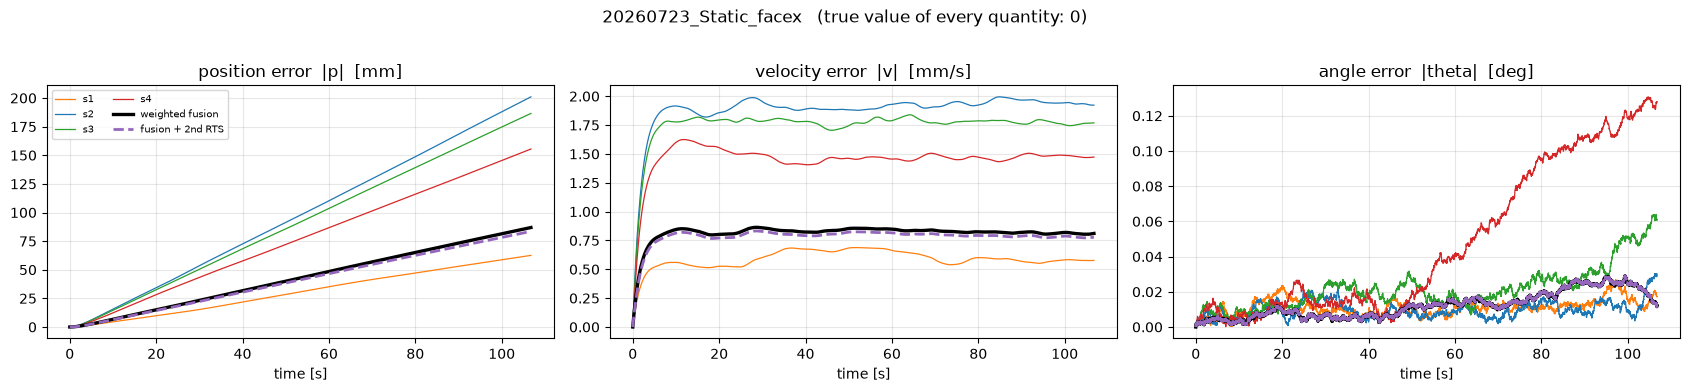

In [83]:
def show_table(df, title, cols=None):
    # Print a table with sensible rounding (no scientific notation clutter).
    print(title)
    with pd.option_context("display.max_columns", None, "display.width", 220, "display.float_format", "{:,.3f}".format):
        display(df if cols is None else df[cols])

def plot_curves(ax, t, curves, key, names, scale=1.0, **kw):
    # Draw one curve per track on an axis, individual IMUs thin and the fused ones bold.
    for i, name in enumerate(names):
        st = style_of(name, i)
        ax.plot(t, curves[name][key] * scale, color=st["color"], lw=st["lw"], ls=st["ls"], label=st["label"], **kw)
    ax.grid(alpha=0.3); ax.set_xlabel("time [s]")

def plot_static(test, t, tracks, extra):
    names = list(tracks); c = extra["curves"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    plot_curves(ax[0], t, c, "ep", names); ax[0].set_title("position error  |p|  [mm]")
    plot_curves(ax[1], t, c, "ev", names); ax[1].set_title("velocity error  |v|  [mm/s]")
    plot_curves(ax[2], t, c, "ang", names); ax[2].set_title("angle error  |theta|  [deg]")
    ax[0].legend(fontsize=7, ncol=2)
    fig.suptitle(f"{test['name']}   (true value of every quantity: 0)", y=1.02)
    plt.tight_layout(); fig.savefig(VAL_OUT / test["name"] / "validation_errors.png", dpi=110, bbox_inches="tight"); plt.show()

cols_static = ["pos_final_mm", "pos_max_mm", "pos_rms_mm", "vel_final_mmps", "ang_final_deg", "ang_max_deg", "ang_rms_deg",
               "equiv_acc_bias_mmps2", "equiv_gyro_bias_mdps", "gdev_max_ums2"]
for tst in tests:
    if tst["kind"] != "rest" or tst["name"] not in analysis: continue
    t, dt, tracks, table, extra = analysis[tst["name"]]
    show_table(table, f"\n=== {tst['name']} (T = {extra['T']:.0f} s) ===", cols_static)
    plot_static(tst, t, tracks, extra)

**How to read the static table.** `pos_final_mm` is the distance from the origin after the whole record; `equiv_acc_bias_mmps2` converts it to the constant accelerometer bias that alone would explain it
(1 mm/s² ≈ 0.1 milli-g); `equiv_gyro_bias_mdps` does the same for the gyro (0.001°/s). `gdev_max_ums2` is the self-check of Chapter 10 and must be ≈ 0 for the individual IMUs.

# Chapter 22 — Results, groups B and C: sine tests

**What to look for.** In the first panel the estimated modulus $m(t)=\lVert\hat{\boldsymbol\theta}\rVert$ should lie on the black reference $\lvert A(t-t_0)\rvert$: a slow 0–35° swing with a faster ripple. The second panel shows the
signed difference. A *constant gain error* shows as an error proportional to the reference (it peaks where the reference peaks); a *drift* shows as an error that grows steadily with time; a *timing offset* shows as an error proportional to the
reference's **slope**. The last two panels remind us that the support never moved: position and velocity are pure error.


=== 20260723_Dinamic_sine_facex_0  (start t0 = 15.56 s, end = 76.2 s, reference peak = 34.9 deg) ===


,pos_final_mm,pos_max_mm,pos_rms_mm,vel_rms_mmps,ang_rms_deg,ang_max_deg,ang_rms_pct_of_peak,end_residual_deg,kappa,gdev_max_ums2
s1,"1,427.522","1,427.522",821.424,14.545,2.994,11.935,8.590,-12.129,1.007,0.000
s2,"1,255.161","1,255.161",719.777,12.781,3.002,11.948,8.613,-12.341,1.007,0.000
s3,483.586,483.586,275.712,4.936,3.003,11.947,8.616,-12.436,1.007,0.000
s4,826.265,826.265,476.888,8.428,2.997,11.947,8.599,-12.343,1.007,0.000
fused,642.276,642.276,367.000,6.546,2.998,11.958,8.603,-12.322,1.007,0.000
fused_rts,626.862,626.862,358.100,6.390,2.998,11.958,8.603,-12.322,1.007,0.000


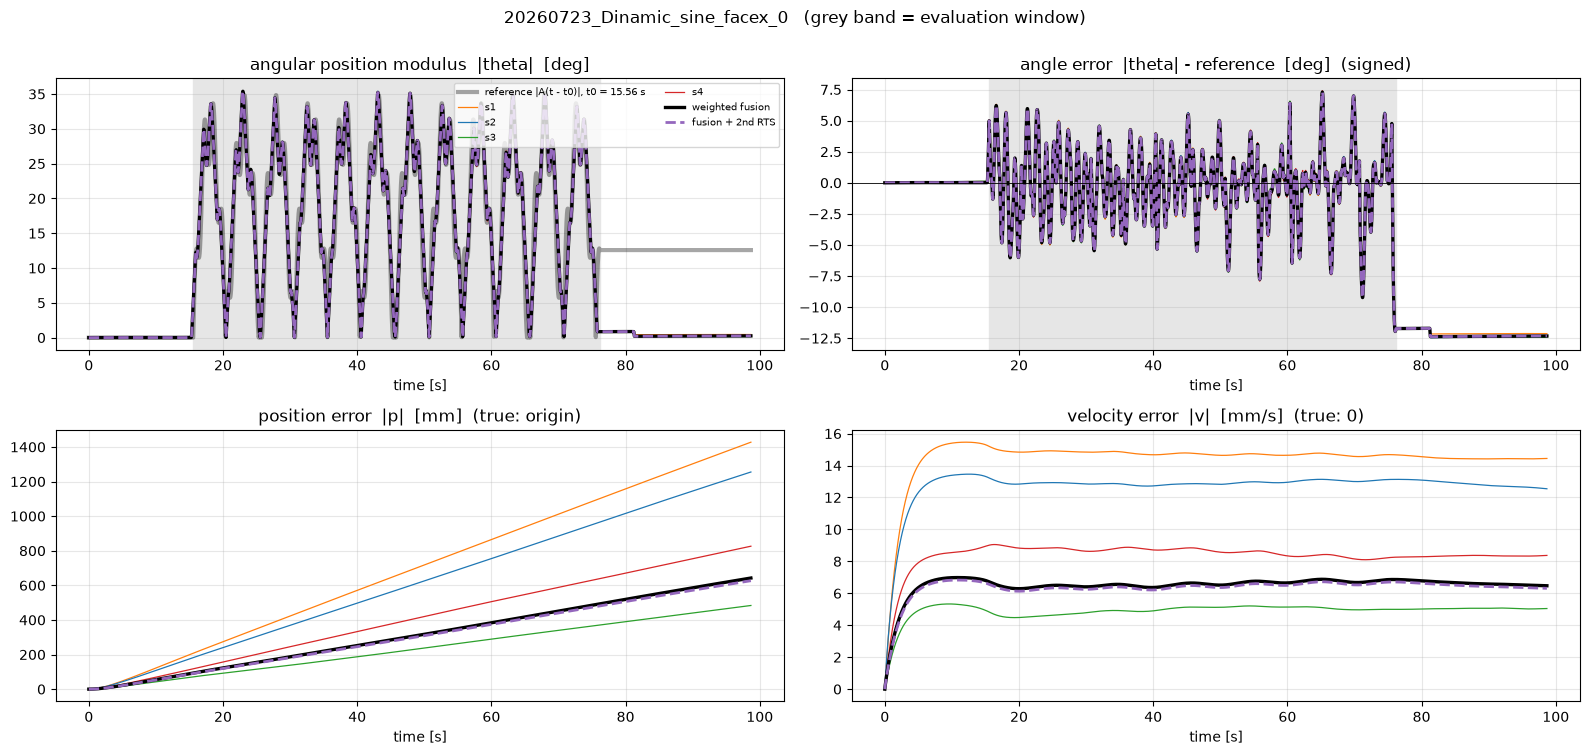


=== 20260723_Dinamic_sine_face_rotX_0  (start t0 = 18.23 s, end = 78.8 s, reference peak = 34.9 deg) ===


,pos_final_mm,pos_max_mm,pos_rms_mm,vel_rms_mmps,ang_rms_deg,ang_max_deg,ang_rms_pct_of_peak,end_residual_deg,kappa,gdev_max_ums2
s1,"1,154.646","1,154.646",663.045,13.108,3.065,11.071,8.793,-11.645,0.124,0.000
s2,"1,126.013","1,126.013",646.439,12.782,3.057,11.956,8.771,-12.408,0.124,0.000
s3,327.756,327.756,188.666,3.723,3.064,11.290,8.791,-11.839,0.124,0.000
s4,"1,016.637","1,016.637",584.314,11.544,3.042,11.564,8.730,-12.133,0.124,0.000
fused,755.630,755.630,434.045,8.577,3.044,11.474,8.734,-12.028,0.124,0.000
fused_rts,725.086,725.086,416.444,8.233,3.044,11.474,8.734,-12.028,0.124,0.000


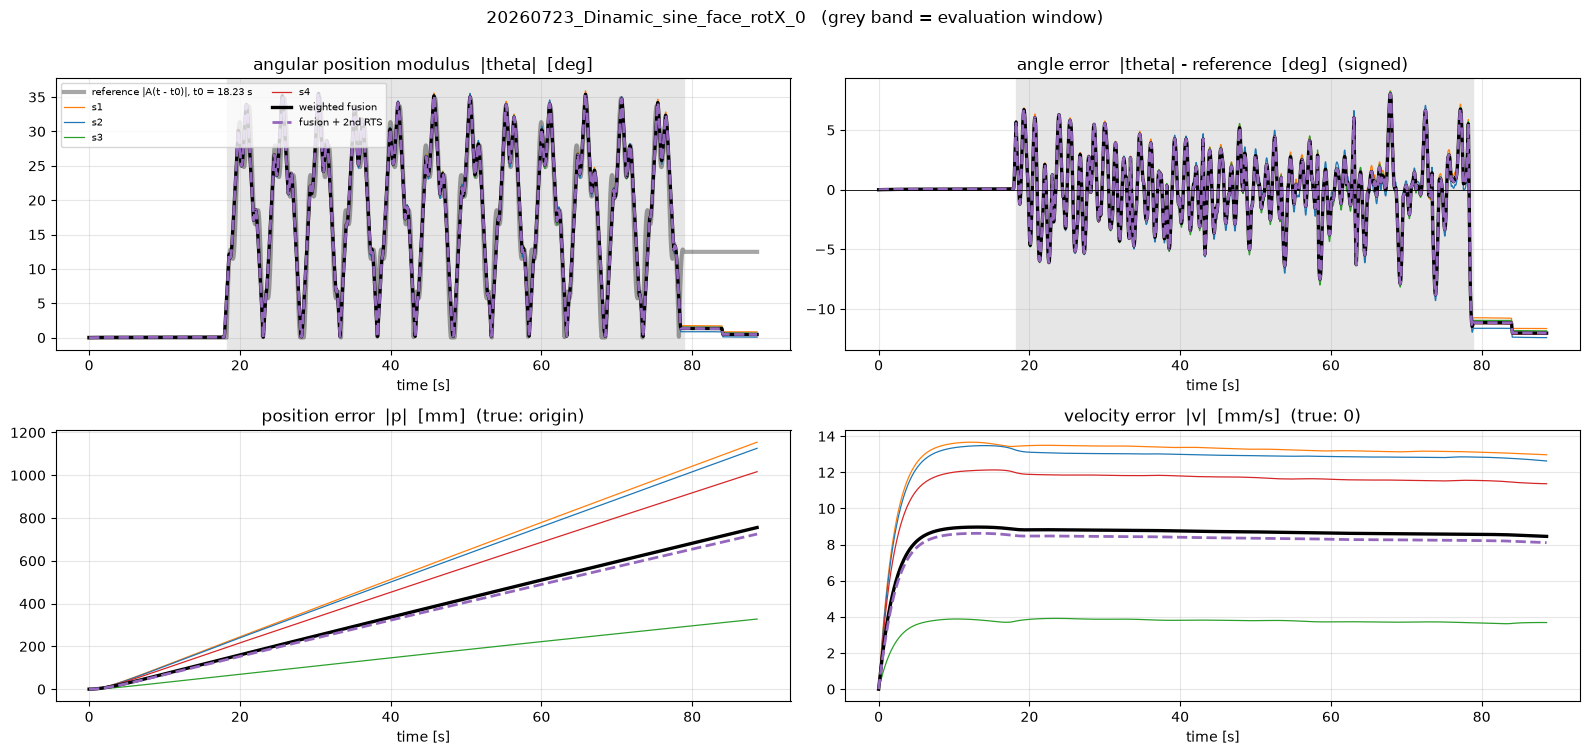

In [84]:
def plot_sine(test, t, tracks, extra):
    names = list(tracks); c = extra["curves"]
    fig, ax = plt.subplots(2, 2, figsize=(16, 7.5)); ax = ax.ravel()
    ax[0].plot(t, extra["r"], color="k", lw=3, alpha=0.35, label=f"reference |A(t - t0)|, t0 = {extra['t0']:.2f} s")
    plot_curves(ax[0], t, c, "m", names); ax[0].set_title("angular position modulus  |theta|  [deg]"); ax[0].legend(fontsize=7, ncol=2)
    plot_curves(ax[1], t, c, "e", names); ax[1].axhline(0, color="k", lw=0.6); ax[1].set_title("angle error  |theta| - reference  [deg]  (signed)")
    plot_curves(ax[2], t, c, "ep", names); ax[2].set_title("position error  |p|  [mm]  (true: origin)")
    plot_curves(ax[3], t, c, "ev", names); ax[3].set_title("velocity error  |v|  [mm/s]  (true: 0)")
    for a in ax[:2]:
        a.axvspan(extra["t0"], extra["t_end"], color="0.9", zorder=0)             # shaded = evaluation window
    fig.suptitle(f"{test['name']}   (grey band = evaluation window)", y=1.0)
    plt.tight_layout(); fig.savefig(VAL_OUT / test["name"] / "validation_errors.png", dpi=110, bbox_inches="tight"); plt.show()

cols_sine = ["pos_final_mm", "pos_max_mm", "pos_rms_mm", "vel_rms_mmps", "ang_rms_deg", "ang_max_deg", "ang_rms_pct_of_peak",
             "end_residual_deg", "kappa", "gdev_max_ums2"]
for tst in tests:
    if tst["kind"] != "sine" or tst["name"] not in analysis: continue
    t, dt, tracks, table, extra = analysis[tst["name"]]
    show_table(table, f"\n=== {tst['name']}  (start t0 = {extra['t0']:.2f} s, end = {extra['t_end']:.1f} s, reference peak = {extra['peak_ref']:.1f} deg) ===", cols_sine)
    plot_sine(tst, t, tracks, extra)

**How to read the sine table.** `ang_rms_deg` is the typical angle error during the motion and `ang_rms_pct_of_peak` expresses it relative to the largest reference angle (≈ 35°). `end_residual_deg`
is the difference between the final modulus and the reference's final value; it should be small, otherwise the estimate kept drifting after the rotation stopped. `kappa` near 1 means the accelerometer and the gyro agree about how much the support turned.

# Chapter 23 — Results, groups D and E: nine full turns

**What to look for.** The cumulative angle $C(t)$, shown in *turns* ($C/360$), should be a straight ramp that saturates at 9. The dashed purple straight line is the fit of the fused result; the second panel shows how far each track deviates from
it (a perfectly constant-speed rotation gives a flat line at 0). The third panel is the length of the rotation vector, which wraps between 0° and 180° while turning and, after a whole number of turns, must **return to ≈ 0**: its final value is the
closure error. The last panel is the position error. Group E rotates about the **vertical**: gravity does not change during such a rotation, so the accelerometer gives no information on the heading and *only the gyro* can measure it — an
especially demanding test.


=== 20260723_Dinamic_720degree_face_rotx_2  (rotation from 7.3 s to 44.3 s, expected 9 turns) ===


,turns,err_vs_expected_deg,err_vs_expected_pct,frac_turn_deg,closure_deg,slope_dps,lin_rms_deg,lin_max_deg,R2,creep_after_deg,pos_final_mm,pos_max_mm,vel_rms_mmps,kappa
s1,2.043,"-2,504.646",-77.304,15.354,14.780,20.290,0.016,0.036,1.000,0.494,"1,242.686","1,242.686",24.289,NaN
s2,2.025,"-2,510.857",-77.496,9.143,8.560,20.116,0.015,0.042,1.000,0.511,"1,457.861","1,457.861",28.520,NaN
s3,2.021,"-2,512.410",-77.544,7.590,6.749,20.076,0.013,0.032,1.000,0.483,"1,460.386","1,460.386",28.569,NaN
s4,2.030,"-2,509.260",-77.446,10.740,9.942,20.163,0.017,0.041,1.000,0.475,"2,066.610","2,066.610",40.450,NaN
fused,2.029,"-2,509.725",-77.461,10.275,10.041,20.162,0.015,0.037,1.000,0.257,399.607,399.607,7.833,NaN
fused_rts,2.029,"-2,509.733",-77.461,10.267,10.041,20.162,0.015,0.037,1.000,0.253,384.876,384.876,7.548,NaN


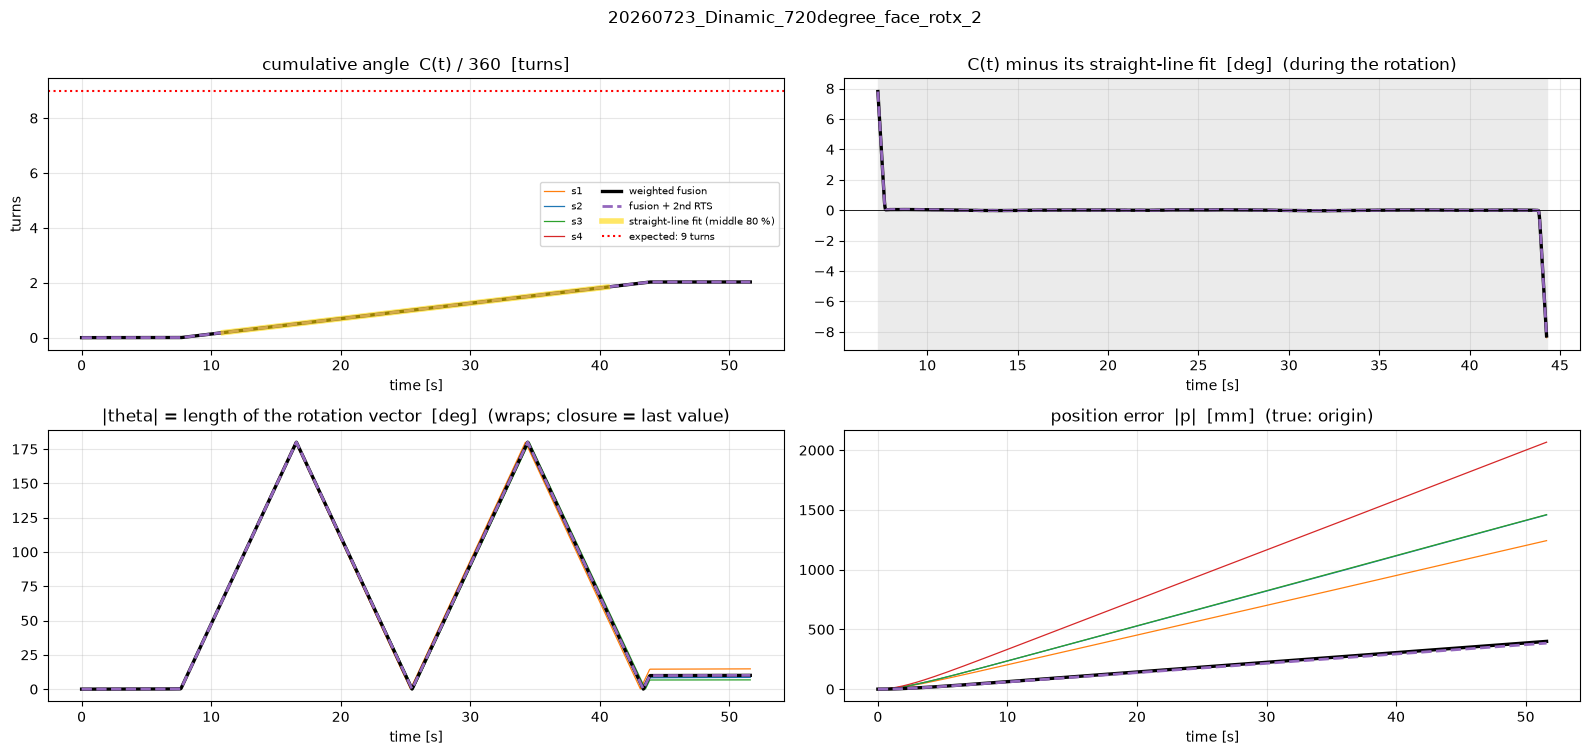

In [85]:
def plot_turns(test, t, tracks, extra):
    names = list(tracks); c = extra["curves"]; ia, ib = extra["window"]
    fig, ax = plt.subplots(2, 2, figsize=(16, 7.5)); ax = ax.ravel()
    plot_curves(ax[0], t, c, "C", names, scale=1 / 360.0)
    fitn = "fused_rts" if "fused_rts" in c else "fused"
    ax[0].plot(t[extra["mid"]], c[fitn]["fit"][extra["mid"]] / 360.0, color="gold", lw=4, alpha=0.6, label="straight-line fit (middle 80 %)")
    ax[0].axhline(TURNS_EXPECTED, color="r", ls=":", label=f"expected: {TURNS_EXPECTED} turns")
    ax[0].set_title("cumulative angle  C(t) / 360  [turns]"); ax[0].set_ylabel("turns"); ax[0].legend(fontsize=7, ncol=2)
    plot_curves(ax[1], t, c, "dev", names); ax[1].axhline(0, color="k", lw=0.6)
    ax[1].axvspan(t[ia], t[ib], color="0.92", zorder=0); ax[1].set_title("C(t) minus its straight-line fit  [deg]  (during the rotation)")
    plot_curves(ax[2], t, c, "m", names); ax[2].set_title("|theta| = length of the rotation vector  [deg]  (wraps; closure = last value)")
    plot_curves(ax[3], t, c, "ep", names); ax[3].set_title("position error  |p|  [mm]  (true: origin)")
    fig.suptitle(f"{test['name']}", y=1.0)
    plt.tight_layout(); fig.savefig(VAL_OUT / test["name"] / "validation_errors.png", dpi=110, bbox_inches="tight"); plt.show()

cols_turns = ["turns", "err_vs_expected_deg", "err_vs_expected_pct", "frac_turn_deg", "closure_deg", "slope_dps",
              "lin_rms_deg", "lin_max_deg", "R2", "creep_after_deg", "pos_final_mm", "pos_max_mm", "vel_rms_mmps", "kappa"]
for tst in tests:
    if tst["kind"] != "turns" or tst["name"] not in analysis: continue
    t, dt, tracks, table, extra = analysis[tst["name"]]
    ia, ib = extra["window"]
    show_table(table, f"\n=== {tst['name']}  (rotation from {t[ia]:.1f} s to {t[ib]:.1f} s, expected {TURNS_EXPECTED} turns) ===", cols_turns)
    plot_turns(tst, t, tracks, extra)

**How to read the nine-turn table.**
* `turns` — should be ≈ 9; `err_vs_expected_deg/pct` — the **gain error** of the angle measurement (a gyro scale-factor error of 1 % turns into 32.4° over 9 turns).
* `frac_turn_deg` and `closure_deg` — both measure "how far from a whole number of turns / from the starting attitude". They are independent of the exact number of turns the rig made. If they are about equal and large,
  suspect a **scale error**; if `closure_deg` is much smaller than `frac_turn_deg`, the rotation axis moved (the rotation vector's length is not the angle swept).
* `slope_dps`, `lin_rms_deg`, `lin_max_deg`, `R2` — how constant the rotation rate was (and how well the estimate reproduces that). `R2` very close to 1 means a very straight ramp.
* `creep_after_deg` — the angle must *saturate* once the rotation stops; any growth is gyro-bias drift.
* `kappa` — if far from 1 the accelerometer and the gyro disagree on the rotation amount (Section 18.5); the pipeline follows the gyro.

# Chapter 24 — Overview across all tests

Finally we compare everything on one page: the key numbers of the **fusion + second RTS** result for each test, how it compares with the typical single IMU (the improvement ratio of Section 18.6), and bar charts of the
most important errors.

In [86]:
# ======================= one line per test: the headline numbers =======================
def headline_row(test, table):
    # Key numbers of one test: fused+RTS result, the typical (median) single IMU, and the improvement ratio (Section 18.6).
    sens = [n for n in table.index if n.startswith("s")]                       # the individual IMUs
    best = "fused_rts" if "fused_rts" in table.index else "fused"
    # which column is 'the' angle error of this kind of test, and what to call it
    ang_col, ang_name = {"rest": ("ang_final_deg", "final |theta|"),
                         "sine": ("ang_rms_deg", "rms vs reference"),
                         "turns": ("closure_deg", "closure |theta(T)|")}[test["kind"]]
    row = dict(group=test["title"], axis=test["axis"], duration_s=test["duration_s"], kappa=test["kappa"], angle_metric=ang_name)
    for label, col in (("pos", "pos_final_mm"), ("ang", ang_col)):
        e_f = float(table.loc[best, col]); e_s = float(table.loc[sens, col].median())
        row[f"{label}_fused_rts"] = e_f                                         # error of fusion + second RTS
        row[f"{label}_median_imu"] = e_s                                        # error of the typical single IMU
        row[f"{label}_ratio"] = e_s / e_f if e_f > 0 else np.nan                # > 1: fusion better than the typical IMU
    row["turns"] = float(table.loc[best, "turns"]) if test["kind"] == "turns" else np.nan
    row["turns_err_pct"] = float(table.loc[best, "err_vs_expected_pct"]) if test["kind"] == "turns" else np.nan
    return row

names_done = [tst["name"] for tst in tests if tst["name"] in all_tables]
headline = pd.DataFrame([headline_row(tst, all_tables[tst["name"]]) for tst in tests if tst["name"] in all_tables], index=names_done)
if len(headline):
    headline.to_csv(VAL_OUT / "validation_headline.csv")
    print("pos_* = final position error [mm];  ang_* = angle error [deg] of the kind named in 'angle_metric'")
    with pd.option_context("display.max_columns", None, "display.width", 250, "display.float_format", "{:,.3f}".format):
        display(headline)

pos_* = final position error [mm];  ang_* = angle error [deg] of the kind named in 'angle_metric'


,group,axis,duration_s,kappa,angle_metric,pos_fused_rts,pos_median_imu,pos_ratio,ang_fused_rts,ang_median_imu,ang_ratio,turns,turns_err_pct
20260723_Static_facex,A. Static,X,106.767,NaN,final |theta|,83.512,170.999,2.048,0.012,0.045,3.744,NaN,NaN
20260723_Dinamic_sine_facex_0,"B. Sine, face",X,98.675,1.007,rms vs reference,626.862,"1,040.713",1.660,2.998,2.999,1.000,NaN,NaN
20260723_Dinamic_sine_face_rotX_0,"C. Sine, rotation axis",X,88.608,0.124,rms vs reference,725.086,"1,071.325",1.478,3.044,3.060,1.005,NaN,NaN
20260723_Dinamic_720degree_face_rotx_2,"E. Nine turns, rotation axis",X,51.617,NaN,closure |theta(T)|,384.876,"1,459.123",3.791,10.041,9.251,0.921,2.029,-77.461


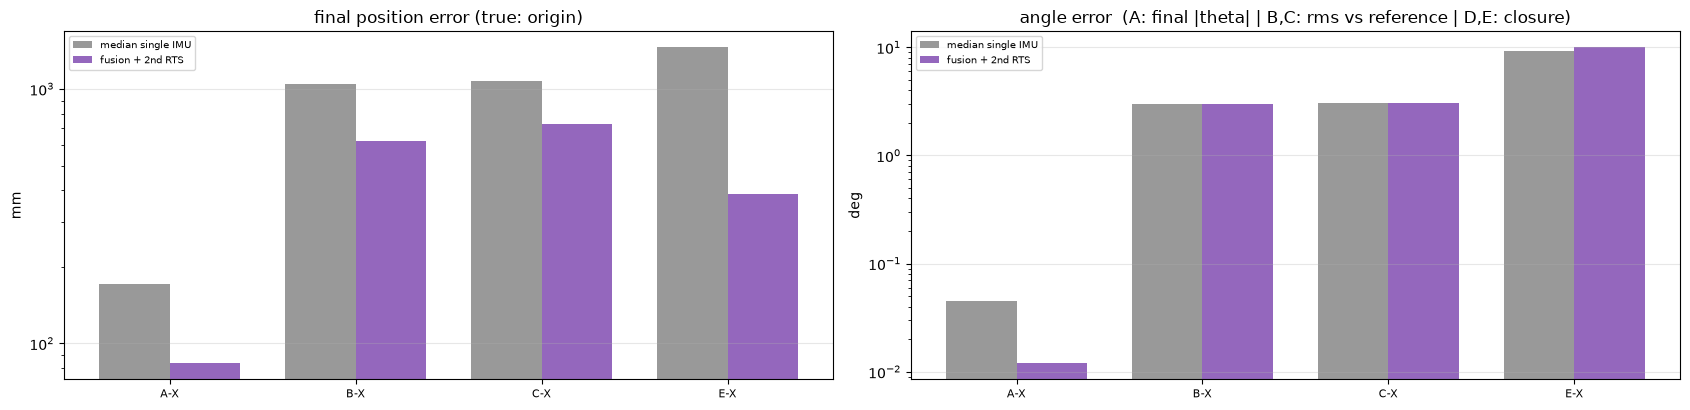

In [87]:
# ======================= bar charts: fused + RTS against the median single IMU =======================
def bars(ax, df, col_f, col_s, title, unit):
    # Grouped bars: for every test, the typical single IMU next to the fused+RTS result (logarithmic height).
    x = np.arange(len(df)); w = 0.38
    ax.bar(x - w / 2, df[col_s], w, color="0.6", label="median single IMU")
    ax.bar(x + w / 2, df[col_f], w, color="tab:purple", label="fusion + 2nd RTS")
    ax.set_xticks(x); ax.set_xticklabels([f"{g.split('.')[0]}-{a}" for g, a in zip(df["group"], df["axis"])], fontsize=8)
    ax.set_title(title); ax.set_ylabel(unit); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=7); ax.set_yscale("log")

if len(headline):
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.2))
    bars(ax[0], headline, "pos_fused_rts", "pos_median_imu", "final position error (true: origin)", "mm")
    bars(ax[1], headline, "ang_fused_rts", "ang_median_imu", "angle error  (A: final |theta| | B,C: rms vs reference | D,E: closure)", "deg")
    plt.tight_layout(); fig.savefig(VAL_OUT / "validation_overview.png", dpi=110); plt.show()

### How to interpret the overview, and what to do with it
* **Bars of the same height for IMU and fusion** — the error is common to all sensors (typically a systematic error: wrong scale factor, a bias that cannot be separated from tilt, an error in the mounting registration); fusion cannot average it away.
* **Fusion clearly lower** — the error is mostly independent noise or an individual bad sensor; averaging works.
* **Position errors of metres** in the dynamic tests are expected to be much larger than in the static ones, because rotation couples any tiny attitude error into the removal of gravity (an attitude error of $\epsilon$ leaves a spurious acceleration $g\,\epsilon$,
  and $\epsilon=0.1^\circ$ already gives $17\ \text{mm/s}^2$ ($9.81\times0.001745$), i.e. about 31 m after 60 s).
* **`kappa` far from 1 on a dynamic test** — the gyro and the accelerometer disagree about how much the support turned. Verify the sample period (here 1/120 s) and the accelerometer/gyro output-rate configuration of the logger.
  *In the one file inspected while writing this chapter (`20260723_Dinamic_720degree_facex_1.csv`, run at 1/120 s) the fused cumulative angle was ≈ 3319° ≈ 9.2 turns (about +2.4 % above 9 turns), the closure error ≈ 68°, and κ ≈ 0.23.
  These are single-run examples, the tables above are the authority.*
* All numbers are exported as `validation_summary.csv` (every test × every track × every error) and `validation_headline.csv` (one line per test), together with one `validation_errors.png` per test inside each test's output folder.

### Limits of this validation
* The "truth" is a **description of the experiment**, not an independent measurement: the exact number of turns made by the rig, whether the support was perfectly still, and the exact sine start time are assumed (the last one is fitted).
* The position truth ("origin") assumes the sensors are on the rotation axis. A lever arm of a few centimetres would produce real centripetal acceleration $\omega^2 r$ that the pipeline would then integrate (Chapter 16, assumptions).
* Only one run per test is available; **run-to-run variability** is not measured (repeating each test would give confidence intervals).
* Errors are **not** compared with any pass/fail tolerance because none was specified; add one by comparing a column with a threshold, e.g. `summary_df["pos_final_mm"] < 50`.

# Appendix A — Glossary

| Term | Meaning |
|---|---|
| **Accelerometer** | measures the push of the support: true acceleration minus gravity (plus bias and noise) |
| **Adaptive filter** | a filter that re-tunes its own noise settings from the size of its recent surprises |
| **Bias** | slowly-varying constant error of a sensor |
| **Body frame** | axes attached to the sensor/object |
| **Covariance (matrix)** | table of variances (diagonal) and linked uncertainties (off-diagonal) |
| **Earth (inertial) frame** | fixed axes: X, Y horizontal, Z up |
| **EKF** | Extended Kalman Filter: Kalman filter for non-linear models (uses tangent lines) |
| **Gauss–Markov process** | a quantity that fades toward zero with a time constant τ and is kicked by random noise |
| **Gauss–Newton** | iterative method to minimise a sum of squared residuals by repeated linearisation |
| **Gyroscope** | measures angular velocity (plus bias and noise) |
| **Information (precision) matrix** | inverse of the covariance; larger means more certain |
| **Innovation** | measurement minus prediction ("surprise") |
| **Joseph form** | numerically safe formula for the covariance update |
| **Kalman gain** | how strongly a measurement corrects the prediction |
| **Process noise Q** | how much the state is allowed to wander between samples |
| **Measurement noise R** | noise of the sensors |
| **Pseudo-measurement** | a known fact (here $\|\mathbf g\|=G_0$) treated as a measurement |
| **Registration** | finding the fixed rotation between two sensors' axes |
| **Rotation matrix** | 3×3 table that converts vectors between frames; its inverse is its transpose |
| **Rotation vector** | axis × angle description of a rotation; matrix = `Exp` of its skew matrix |
| **RTS smoother** | backward pass (Rauch–Tung–Striebel) that refines filter results using future data |
| **Skew matrix** | the matrix $[\mathbf v]_\times$ with $[\mathbf v]_\times\mathbf u=\mathbf v\times\mathbf u$ |
| **SVD** | singular value decomposition: matrix factorisation used to solve Wahba's problem |
| **Wahba problem** | find the rotation that best aligns two sets of vectors |
| **Closure error** | length of the final rotation vector after a whole number of turns; ≈ 0 if the attitude returned to its start |
| **Equivalent bias** | the constant sensor bias that alone would explain an observed error (position: $2e_p/T^2$; angle: $e_\theta/T$) |
| **Improvement ratio** | median single-IMU error divided by the fused error; above 1 means fusion helped |
| **κ (gyro/gravity factor)** | angle turned by the accelerometer's gravity direction divided by the angle integrated from the gyro; 1 means consistent |
| **Yaw / pitch / roll** | rotations about vertical, lateral and longitudinal axes (heading, nose-up, bank) |

# Appendix B — Helpers that exist in the files but are not used by the current pipeline
For completeness the remaining functions of the project files are shown (with comments). `convert_legacy_cfg` adapted settings of an older 28-state
filter before `make_cfg` was written directly for the 15 states; `earth_state_covariance` is the single-IMU counterpart of `project_earth_with_cov`.

In [88]:
def _as_vec(v, n, name):
    # Check that a settings vector has the expected length and return a copy.
    a = np.asarray(v, float)
    if a.shape != (n,):
        raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
    return a.copy()

In [89]:
def convert_legacy_cfg(cfg0) -> AEKFConfig:
    """Accept either the new 15-state AEKFConfig or the previous 28-state cfg."""
    # LEGACY (unused now): converts the settings of an older 28-state filter [p v a th w q ba bw g]
    # to the 15 states [a w ba bw g] kept by the current filter.
    if isinstance(cfg0, AEKFConfig):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(cfg0.tau_a), tau_w=float(cfg0.tau_w),
            P0_std=_as_vec(cfg0.P0_std, 15, "P0_std"),
            Q0_std=_as_vec(cfg0.Q0_std, 15, "Q0_std"),
            R0_std=_as_vec(cfg0.R0_std, 6, "R0_std"),
            sigma_gnorm=float(getattr(cfg0, "sigma_gnorm", 0.05)),
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=None if getattr(cfg0, "Q_min_std", None) is None else _as_vec(cfg0.Q_min_std, 15, "Q_min_std"),
            R_min_std=None if getattr(cfg0, "R_min_std", None) is None else _as_vec(cfg0.R_min_std, 6, "R_min_std"),
            adapt_gyro_R=bool(getattr(cfg0, "adapt_gyro_R", False)),
            adapt_bias_process=bool(getattr(cfg0, "adapt_bias_process", False)),
            min_w_jump_std=float(getattr(cfg0, "min_w_jump_std", 0.0)),
            max_w_jump_std=getattr(cfg0, "max_w_jump_std", None),
        )

    p = np.asarray(cfg0.P0_std, float)
    q = np.asarray(cfg0.Q0_std, float)
    qmin = np.asarray(getattr(cfg0, "Q_min_std", np.zeros_like(q)), float)
    r0 = np.asarray(cfg0.R0_std, float)
    rmin = np.asarray(getattr(cfg0, "R_min_std", np.zeros(6)), float)

    if p.shape == (15,) and q.shape == (15,):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
            P0_std=p.copy(), Q0_std=q.copy(), R0_std=r0.copy(),
            sigma_gnorm=0.05,
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=qmin.copy(), R_min_std=rmin.copy(),
            adapt_gyro_R=False, adapt_bias_process=False,
        )

    if p.shape != (28,) or q.shape != (28,):
        raise ValueError("Noise configuration must contain 15-state or 28-state vectors")

    KEEP28 = np.r_[6:9, 12:15, 19:28]
    return AEKFConfig(
        dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
        tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
        P0_std=p[KEEP28].copy(), Q0_std=q[KEEP28].copy(), R0_std=r0.copy(),
        sigma_gnorm=0.05,
        enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
        window=int(getattr(cfg0, "window", 100)),
        b=float(getattr(cfg0, "b", 0.98)),
        min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
        Q_min_std=qmin[KEEP28].copy(), R_min_std=rmin.copy(),
        adapt_gyro_R=False, adapt_bias_process=False,
    )

In [90]:
def earth_state_covariance(
    xs: np.ndarray,
    Ps: np.ndarray,
    R: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray]:
    """Transform [a_B, w_B, g_B] and their covariance into Earth frame.

    Returns:
        Y  : (N,9), concatenated [a_E, w_E, g_E_est]
        PY : (N,9,9), full covariance of those 9 quantities
    """
    # Single-IMU helper (unused by the multi-sensor pipeline): rotates [a, w, g] and their covariance into the Earth frame.
    xs = np.asarray(xs, float)
    Ps = np.asarray(Ps, float)
    R = np.asarray(R, float)

    if xs.ndim != 2 or xs.shape[1] != N_X:
        raise ValueError("xs must have shape (N,15)")
    if Ps.shape != (len(xs), N_X, N_X):
        raise ValueError("Ps must have shape (N,15,15)")
    if R.shape != (len(xs), 3, 3):
        raise ValueError("R must have shape (N,3,3)")

    Y = np.empty((len(xs), 9))
    PY = np.empty((len(xs), 9, 9))

    J = np.zeros((9, N_X))
    for k in range(len(xs)):
        Rk = R[k]
        Y[k] = np.concatenate([
            Rk @ xs[k, SL["a"]],
            Rk @ xs[k, SL["w"]],
            Rk @ xs[k, SL["g"]],
        ])
        J.fill(0.0)
        J[0:3, SL["a"]] = Rk
        J[3:6, SL["w"]] = Rk
        J[6:9, SL["g"]] = Rk
        PY[k] = J @ Ps[k] @ J.T

    return Y, PY

In [91]:
# KEEP28 / G constants used only by the legacy converter above (positions of a, w, ba, bw, g inside the old 28-vector)
KEEP28 = np.r_[6:9, 12:15, 19:28]
print("KEEP28 =", KEEP28)

KEEP28 = [ 6  7  8 12 13 14 19 20 21 22 23 24 25 26 27]


# PART IV — Alternative estimator: Sola's error-state Kalman filter (ESKF)

This part compares the `run_general_*` pipeline with the supplied **Sola 2017 ESKF** and its four-IMU wrapper. It comes before the separate static-calibration / gyro-attitude proposal in Part V.

Reference: Joan Solà, [*Quaternion kinematics for the error-state Kalman filter* (2017)](https://arxiv.org/abs/1711.02508). The paper carefully distinguishes a quaternion nominal state from a three-parameter local angular error, and derives the corresponding Jacobians, injection and reset operations.

## Chapter 25 — Theory: nominal state versus error state

The main distinction is **what the filter stores**:

| Quantity | `run_general_*` AEKF | Sola ESKF in this comparison |
|---|---|---|
| Nominal state | 15 values: body acceleration, angular rate, two biases, gravity | 19 values: world position and velocity, quaternion, two biases, world gravity |
| Covariance state | 15-dimensional error around the stored 15-vector | 18-dimensional error: position, velocity, local angle, two biases, gravity |
| Orientation | gravity is an explicit body-frame state; attitude is reconstructed downstream | quaternion is propagated nominally; a 3-vector local attitude error is estimated and injected |
| Still information | filter adapts model/noise using sensor measurements | “constrained still” observation asserts the support point has zero position and velocity, with larger variance when the IMU is offset from the rotation axis |

The nominal ESKF state is

$$x=[p,\ v,\ q,\ b_a,\ b_\omega,\ g]\quad (3+3+4+3+3+3=19),$$

while its covariance is over

$$\delta x=[\delta p,\ \delta v,\ \delta\theta,\ \delta b_a,\ \delta b_\omega,\ \delta g]\in\mathbb R^{18}.$$

A small rotation is **not** added to the four quaternion coefficients. It is injected multiplicatively, $q\leftarrow q\otimes\exp(\delta\theta)$, and the error covariance is reset with the local Jacobian. This avoids treating orientation as a four-dimensional Euclidean variable.

At each retained 120 Hz sample the supplied implementation performs: (1) nominal propagation from accelerometer and gyroscope; (2) covariance propagation $P\leftarrow F_xPF_x^T+F_iQ_iF_i^T$; (3) a zero-position/zero-velocity measurement update; (4) error injection and orientation-error reset; and (5) a backward error-state RTS pass followed by correction injection.

### What “constrained still” means here

The rotary bench's **mounting point** is assumed stationary: $y=[0,0,0,0,0,0]$ and $h(x)=[p;v]$. The IMU chip can be displaced from the axis, so it can travel along an arc. The supplied code inflates the observation covariance using the lever-arm chord for position and approximately $r\|\omega\|$ for velocity. This is an engineering noise model, not an exact rigid-body lever-arm compensation. It is most appropriate when the bench/support point truly remains fixed.


## Chapter 26 — Code: the 18-state error filter

The implementation below follows the supplied `eskf_sola.py`: quaternion order is **(w, x, y, z)** internally, angular errors are local three-vectors, the correction uses Joseph covariance form, and the smoothed error is injected into the nominal trajectory. The adapter at the end preserves the signature used by the supplied four-IMU script.


In [92]:
# ======================= Sola 2017 ESKF: quaternion and local-error machinery =======================
G0_ESKF = 9.80665
P_, V_, TH, AB, WB, GG = slice(0, 3), slice(3, 6), slice(6, 9), slice(9, 12), slice(12, 15), slice(15, 18)


def skew_eskf(v):
    """Cross-product matrix [v]x, so [v]x @ u == v x u."""
    v = np.asarray(v, float)
    return np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])


def q_mul(p, q):
    """Hamilton product p (x) q; quaternions are ordered (w, x, y, z)."""
    pw, px, py, pz = p
    qw, qx, qy, qz = q
    return np.array([pw*qw - px*qx - py*qy - pz*qz,
                     pw*qx + px*qw + py*qz - pz*qy,
                     pw*qy - px*qz + py*qw + pz*qx,
                     pw*qz + px*qy - py*qx + pz*qw])


def q_exp(v):
    """Quaternion exponential of a rotation vector (the angle is ||v||)."""
    v = np.asarray(v, float)
    angle = np.linalg.norm(v)
    if angle < 1e-12:
        return np.r_[1.0, 0.5 * v]
    return np.r_[np.cos(angle / 2.0), np.sin(angle / 2.0) * v / angle]


def q_to_R(q):
    """Rotation matrix for a unit quaternion (w, x, y, z), body -> world."""
    w, x, y, z = np.asarray(q, float) / np.linalg.norm(q)
    return np.array([[w*w+x*x-y*y-z*z, 2*(x*y-w*z), 2*(x*z+w*y)],
                     [2*(x*y+w*z), w*w-x*x+y*y-z*z, 2*(y*z-w*x)],
                     [2*(x*z-w*y), 2*(y*z+w*x), w*w-x*x-y*y+z*z]])


def q_conj(q):
    return np.asarray(q, float) * np.array([1.0, -1.0, -1.0, -1.0])


def Q_dtheta(q):
    """Jacobian of q (x) dq with respect to the local 3-vector dtheta."""
    w, x, y, z = q
    return 0.5 * np.array([[-x, -y, -z], [w, -z, y], [z, w, -x], [-y, x, w]])


def X_dx(q):
    """Map the 18-dimensional error into perturbations of the 19-state nominal vector."""
    X = np.zeros((19, 18))
    X[0:6, 0:6] = np.eye(6)
    X[6:10, 6:9] = Q_dtheta(q)
    X[10:19, 9:18] = np.eye(9)
    return X


class SolaESKF:
    """Nominal [p, v, q, ba, bw, g], 18-state local error covariance."""
    def __init__(self, p0, v0, q0, ab0, wb0, g0, P0, noise):
        self.p = np.asarray(p0, float).copy()
        self.v = np.asarray(v0, float).copy()
        self.q = np.asarray(q0, float) / np.linalg.norm(q0)
        self.ab = np.asarray(ab0, float).copy()
        self.wb = np.asarray(wb0, float).copy()
        self.g = np.asarray(g0, float).copy()
        self.P = np.diag(np.r_[[P0['p']**2]*3, [P0['v']**2]*3, [P0['th']**2]*3,
                               [P0['ab']**2]*3, [P0['wb']**2]*3, [P0['g']**2]*3])
        self.nz = dict(noise)
        self.Fi = np.zeros((18, 12))
        self.Fi[3:15, :] = np.eye(12)

    def predict(self, a_m, w_m, dt):
        """Nominal propagation and covariance prediction (Sola's equations 260, 269–271)."""
        R = q_to_R(self.q)
        acc_w = R @ (a_m - self.ab) + self.g
        self.p = self.p + self.v * dt + 0.5 * acc_w * dt**2
        self.v = self.v + acc_w * dt
        self.q = q_mul(self.q, q_exp((w_m - self.wb) * dt))
        self.q /= np.linalg.norm(self.q)

        Fx = np.eye(18)
        Fx[P_, V_] = np.eye(3) * dt
        Fx[V_, TH] = -R @ skew_eskf(a_m - self.ab) * dt
        Fx[V_, AB] = -R * dt
        Fx[V_, GG] = np.eye(3) * dt
        Fx[TH, TH] = q_to_R(q_exp((w_m - self.wb) * dt)).T
        Fx[TH, WB] = -np.eye(3) * dt
        nz = self.nz
        Qi = np.diag(np.r_[[nz['sig_an']**2 * dt**2]*3,
                           [nz['sig_wn']**2 * dt**2]*3,
                           [nz['sig_aw']**2 * dt]*3,
                           [nz['sig_ww']**2 * dt]*3])
        self.P = Fx @ self.P @ Fx.T + self.Fi @ Qi @ self.Fi.T
        self.P = 0.5 * (self.P + self.P.T)
        return Fx

    def correct(self, y, h, Hx, V):
        """Linearized update, Joseph covariance form, multiplicative injection, and reset."""
        H = Hx @ X_dx(self.q)
        S = H @ self.P @ H.T + V
        # Solve instead of explicitly forming S^{-1}; mathematically this is K = P H' S^{-1}.
        K = np.linalg.solve(S, H @ self.P).T
        dx = K @ (y - h)
        IKH = np.eye(18) - K @ H
        self.P = IKH @ self.P @ IKH.T + K @ V @ K.T
        self.P = 0.5 * (self.P + self.P.T)
        self.inject(dx)
        G = np.eye(18)
        G[TH, TH] = np.eye(3) - skew_eskf(0.5 * dx[TH])
        self.P = G @ self.P @ G.T
        self.P = 0.5 * (self.P + self.P.T)
        return dx

    def inject(self, dx):
        self.p += dx[P_]
        self.v += dx[V_]
        self.q = q_mul(self.q, q_exp(dx[TH]))
        self.q /= np.linalg.norm(self.q)
        self.ab += dx[AB]
        self.wb += dx[WB]
        self.g += dx[GG]

    def state(self):
        return np.r_[self.p, self.v, self.q, self.ab, self.wb, self.g]


def still_observation(f, w_m, still):
    """Zero position/velocity observation for a stationary support point; V is lever-arm-aware."""
    y = np.zeros(6)
    h = np.r_[f.p, f.v]
    Hx = np.zeros((6, 19))
    Hx[0:3, 0:3] = np.eye(3)
    Hx[3:6, 3:6] = np.eye(3)
    r = still['lever_arm']
    ang = 2 * np.arccos(min(1.0, abs(float(np.dot(f.q, still['q0'])))))
    chord = r * 2 * abs(np.sin(ang / 2.0))
    w_corr = w_m - f.wb
    V = np.diag(np.r_[[still['sig_p']**2 + chord**2]*3,
                      [still['sig_v']**2 + (r*np.linalg.norm(w_corr))**2]*3])
    return y, h, Hx, V


def run_eskf_sola(acc, gyro, dt, q0, ab0, wb0, g0, P0, noise, still,
                  correct=True, smooth=True):
    """Forward ESKF plus error-state RTS. acc [m/s^2], gyro [rad/s], quaternion q=(w,x,y,z)."""
    n = len(acc)
    f = SolaESKF(np.zeros(3), np.zeros(3), q0, ab0, wb0, g0, P0, noise)
    st = dict(still, q0=np.asarray(q0, float) / np.linalg.norm(q0))
    X = np.zeros((n, 19)); Ptr = np.zeros(n)
    F_h = np.zeros((n, 18, 18)); P_prior = np.zeros((n, 18, 18))
    P_post = np.zeros((n, 18, 18)); dx_h = np.zeros((n, 18))
    for k in range(n):
        F_h[k] = f.predict(acc[k], gyro[k], dt)
        P_prior[k] = f.P
        if correct:
            dx_h[k] = f.correct(*still_observation(f, gyro[k], st))
        X[k], P_post[k], Ptr[k] = f.state(), f.P, np.trace(f.P[TH, TH])
    out = dict(p=X[:, 0:3], v=X[:, 3:6], q=X[:, 6:10], ab=X[:, 10:13],
               wb=X[:, 13:16], g=X[:, 16:19], Ptheta=Ptr)
    if not smooth:
        out.update(q_s=out['q'], ab_s=out['ab'], wb_s=out['wb'], p_s=out['p'],
                   v_s=out['v'], g_s=out['g'], Ptheta_s=Ptr)
        return out

    Xs = X.copy(); Ptr_s = np.zeros(n)
    e = np.zeros(18); Ps = P_post[-1].copy()
    Ptr_s[-1] = np.trace(Ps[TH, TH])
    for k in range(n - 2, -1, -1):
        C = np.linalg.solve(P_prior[k+1].T, (P_post[k] @ F_h[k+1].T).T).T
        e = C @ (e + dx_h[k+1])
        Ps = P_post[k] + C @ (Ps - P_prior[k+1]) @ C.T
        Ps = 0.5 * (Ps + Ps.T)
        Xs[k, 0:3] = X[k, 0:3] + e[P_]
        Xs[k, 3:6] = X[k, 3:6] + e[V_]
        qs = q_mul(X[k, 6:10], q_exp(e[TH]))
        Xs[k, 6:10] = qs / np.linalg.norm(qs)
        Xs[k, 10:13] = X[k, 10:13] + e[AB]
        Xs[k, 13:16] = X[k, 13:16] + e[WB]
        Xs[k, 16:19] = X[k, 16:19] + e[GG]
        Ptr_s[k] = np.trace(Ps[TH, TH])
    out.update(p_s=Xs[:, 0:3], v_s=Xs[:, 3:6], q_s=Xs[:, 6:10],
               ab_s=Xs[:, 10:13], wb_s=Xs[:, 13:16], g_s=Xs[:, 16:19], Ptheta_s=Ptr_s)
    return out


def eskf_rts(acc, gyro, dt, q0, bg0, ba0, nz, use_acc=True, smooth=True):
    """Adapter with the same keyword meanings as the supplied eskf_rts wrapper."""
    noise = dict(sig_an=nz['sig_a'], sig_wn=nz['sig_g'], sig_aw=nz['rw_ba'], sig_ww=nz['rw_bg'])
    P0 = dict(p=nz.get('P0_p', 0.01), v=nz.get('P0_v', 0.01), th=nz['P0_theta'],
              ab=nz['P0_ba'], wb=nz['P0_bg'], g=nz.get('P0_g', 0.02))
    still = dict(sig_p=nz.get('sig_p', 0.05), sig_v=nz.get('sig_v', 0.02),
                 lever_arm=nz.get('lever_arm', 0.05))
    r = run_eskf_sola(acc, gyro, dt, q0, ba0, bg0, np.array([0.0, 0.0, G0_ESKF]),
                      P0, noise, still, correct=use_acc, smooth=smooth)
    return dict(q=r['q'], q_s=r['q_s'], bg=r['wb'], bg_s=r['wb_s'],
                ba=r['ab'], ba_s=r['ab_s'], Ptheta=r['Ptheta'], Ptheta_s=r['Ptheta_s'],
                p=r['p'], v=r['v'], p_s=r['p_s'], v_s=r['v_s'], g=r['g'], g_s=r['g_s'])


## Chapter 27 — Four IMUs: dynamic-axis registration, noise-weighted virtual IMU, one ESKF

The supplied `fuse_4imu.py` adds a **registration step before the filter**. It uses a dynamic reference recording, not Wahba and not a gravity consensus:

1. Subtract the initial resting gyro mean and find each sensor's dominant gyro axis by an eigenvector of the gyro covariance.
2. Rotate each axis onto the S1 axis. The remaining rotation about that axis is determined from the phase of the measured gravity circle in the plane perpendicular to the axis.
3. Rotate all accelerometer and gyro samples into S1 axes. Estimate separate inverse-variance weights from the still interval and form a virtual accelerometer and gyroscope.
4. Run one Sola ESKF + error-state RTS smoother on the weighted signals. For an honest baseline, also run the same ESKF separately on each registered IMU.

This differs from both neighboring methods:

* **`run_general_*`:** each IMU gets a 15-state AEKF/RTS; registration is covariance-weighted Wahba on smoothed gravity **and** angular rate, then an information-form gravity/rate consensus, followed by Earth-frame information fusion and an optional second RTS.
* **Sola ESKF wrapper here:** registration uses the dynamic rotation axis plus gravity phase; sensor samples are combined by scalar inverse-noise weights before one ESKF; the filter uses a constrained-still position/velocity observation.
* **Method B in Part V:** the relative rotation is the shortest rotation between one pair of static gravity directions; gyro bias is calibrated once and then frozen.

The first two methods need sufficient dynamic excitation to identify the residual rotation around the bench axis. A single static gravity vector by itself cannot identify that rotation.


In [93]:
# ======================= Dynamic-axis registration and four-IMU Sola ESKF wrapper =======================
ODR_ESKF = 120.0
DT_ESKF = 1.0 / ODR_ESKF
CAL_ESKF_S = 15.0
GYRO_INFL_ESKF, ACC_INFL_ESKF = 2.0, 10.0
GYRO_FLOOR_DPS_ESKF, ACC_FLOOR_G_ESKF = 0.02, 0.01
BIAS_RW_ESKF, ACC_BIAS_RW_ESKF = 1e-6, 1e-7
P0_ATT_DEG_ESKF, P0_BIAS_DPS_ESKF, P0_ACC_BIAS_G_ESKF = 2.0, 0.01, 0.0003
STILL_ESKF = dict(sig_p=0.05, sig_v=0.02, lever_arm=0.10)


def _principal_axis(g_dps, k):
    """Dominant rotation axis in the IMU frame, after subtracting its resting gyro mean."""
    g = np.asarray(g_dps, float) - np.asarray(g_dps, float)[:k].mean(0)
    active = np.linalg.norm(g, axis=1) > 5.0
    if active.sum() < 10:
        raise ValueError("Dynamic-axis registration needs at least 10 samples above 5 deg/s")
    axis = np.linalg.eigh(g[active].T @ g[active])[1][:, -1]
    return axis / np.linalg.norm(axis)


def _rot_between(u, v):
    """Proper minimum rotation mapping direction u to v, including antiparallel vectors."""
    return minimal_map(np.asarray(u, float), np.asarray(v, float))


def align_to_s1(dyn, k):
    """Estimate sensor->S1 rotations from a dynamic gyro axis and gravity-circle phase."""
    ax = {s: _principal_axis(dyn[s]['gyro_dps'], k) for s in dyn}
    s1gyro = dyn['s1']['gyro_dps'] - dyn['s1']['gyro_dps'][:k].mean(0)
    active_ids = np.flatnonzero(np.linalg.norm(s1gyro, axis=1) > 5.0)
    if not len(active_ids):
        raise ValueError("S1 has no detected dynamic rotation")
    first = s1gyro[active_ids[0]]
    ax['s1'] = ax['s1'] * np.sign(first @ ax['s1'])
    a1 = ax['s1']
    e1 = np.cross(a1, [0.0, 0.0, 1.0])
    if np.linalg.norm(e1) < 1e-8:
        e1 = np.cross(a1, [0.0, 1.0, 0.0])
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(a1, e1)
    norm_rows = lambda a: a / np.maximum(np.linalg.norm(a, axis=1, keepdims=True), 1e-12)
    R = {}
    for s in dyn:
        if s == 's1':
            R[s] = np.eye(3)
            continue
        gi = dyn[s]['gyro_dps'] - dyn[s]['gyro_dps'][:k].mean(0)
        sign = np.sign(np.sum((s1gyro @ a1) * (gi @ ax[s]))) or 1.0
        R0 = _rot_between(sign * ax[s], a1)
        A = norm_rows(dyn['s1']['acc_g'])
        B = norm_rows(dyn[s]['acc_g']) @ R0.T
        pa, pb = np.c_[A @ e1, A @ e2], np.c_[B @ e1, B @ e2]
        al = np.arctan2(np.sum(pb[:, 0]*pa[:, 1] - pb[:, 1]*pa[:, 0]),
                        np.sum(pb[:, 0]*pa[:, 0] + pb[:, 1]*pa[:, 1]))
        R[s] = Rot.from_rotvec(al * a1).as_matrix() @ R0
    return R, a1


def rig_frame(acc_init, axis):
    """Body(S1)->bench frame: Z points down with gravity; X follows the bench rotation axis."""
    f = np.asarray(acc_init, float).mean(0)
    z = -f / np.linalg.norm(f)
    x = np.asarray(axis, float) - np.dot(axis, z) * z
    x /= np.linalg.norm(x)
    y = np.cross(z, x)
    y /= np.linalg.norm(y)
    return np.vstack([x, y, z])


def euler_zyx_deg(q):
    e = Rot.from_quat(np.asarray(q)[:, [1, 2, 3, 0]]).as_euler('ZYX', degrees=True)
    return np.column_stack([np.degrees(np.unwrap(np.radians(e[:, 2]))), e[:, 1],
                            np.degrees(np.unwrap(np.radians(e[:, 0])))])


def bench_euler_deg(q_rel, R_bw, axis_body):
    """Roll/pitch/yaw in a bench frame whose X axis is the rotation axis."""
    a_w = R_bw @ axis_body
    a_w /= np.linalg.norm(a_w)
    y = np.cross([0.0, 0.0, 1.0], a_w)
    if np.linalg.norm(y) < 1e-8:
        y = np.array([0.0, 1.0, 0.0])
    y /= np.linalg.norm(y)
    B = np.c_[a_w, y, np.cross(a_w, y)]
    Q = Rot.from_quat(np.asarray(q_rel)[:, [1, 2, 3, 0]]).as_matrix()
    RB = np.einsum('ji,njk,kl->nil', B, Q, B)
    e = Rot.from_matrix(RB).as_euler('ZYX', degrees=True)
    return np.column_stack([np.degrees(np.unwrap(np.radians(e[:, 2]))), e[:, 1],
                            np.degrees(np.unwrap(np.radians(e[:, 0])))])


def _eskf_rpy(acc, gyro, axis, k):
    """Run the Sola ESKF+RTS on one registered stream. Inputs: SI units, S1 axes."""
    R_bw = rig_frame(acc[:k] / G0_ESKF, axis)
    q_base = Rot.from_matrix(R_bw).as_quat()[[3, 0, 1, 2]]
    sig_g = max(float(gyro[:k].std(0).max()), np.radians(GYRO_FLOOR_DPS_ESKF)) * GYRO_INFL_ESKF
    sig_a = max(float(acc[:k].std(0).max()), ACC_FLOOR_G_ESKF * G0_ESKF) * ACC_INFL_ESKF
    nz = dict(sig_g=sig_g, sig_a=sig_a, rw_bg=BIAS_RW_ESKF, rw_ba=ACC_BIAS_RW_ESKF,
              P0_theta=np.radians(P0_ATT_DEG_ESKF), P0_bg=np.radians(P0_BIAS_DPS_ESKF),
              P0_ba=P0_ACC_BIAS_G_ESKF*G0_ESKF, **STILL_ESKF)
    r = eskf_rts(acc, gyro, DT_ESKF, q_base, gyro[:k].mean(0), np.zeros(3), nz)
    rel = lambda Q: bench_euler_deg(np.array([q_mul(q, q_conj(q_base)) for q in Q]), R_bw, axis)
    R_s = np.stack([q_to_R(q) for q in r['q_s']])
    w_body_s = gyro - r['bg_s']
    w_bench_s = np.einsum('nij,nj->ni', R_s, w_body_s)
    return dict(fwd=rel(r['q']), rts=rel(r['q_s']), nz=nz,
                bg=np.degrees(r['bg_s'][-1]), ba_mg=r['ba_s'][-1]/G0_ESKF*1e3,
                q=r['q'], q_s=r['q_s'], R_s=R_s, w_body_s=w_body_s, wE_s=w_bench_s,
                p_s=r['p_s'], v_s=r['v_s'], wb_s=r['bg_s'], ba_s=r['ba_s'],
                Ptheta=r['Ptheta'], Ptheta_s=r['Ptheta_s'])


def fuse_4imu(data, Rs1, axis, init_s=CAL_ESKF_S, acc_rel_offset=False):
    """Register, noise-weight and fuse 4 IMUs; run one fused and four single-stream ESKFs."""
    k = int(round(init_s * ODR_ESKF))
    acc = {s: (data[s]['acc_g'] @ Rs1[s].T) * G0_ESKF for s in data}
    gyro = {s: np.radians(data[s]['gyro_dps'] @ Rs1[s].T) for s in data}
    wg_raw = np.array([1.0 / max(float(gyro[s][:k].std(0).mean()), np.radians(GYRO_FLOOR_DPS_ESKF))**2 for s in data])
    wa_raw = np.array([1.0 / max(float(acc[s][:k].std(0).mean()), ACC_FLOOR_G_ESKF*G0_ESKF)**2 for s in data])
    wg = wg_raw / wg_raw.sum(); wa = wa_raw / wa_raw.sum()
    if acc_rel_offset:
        m = {s: acc[s][:k].mean(0) for s in data}
        mg = sum(w*m[s] for w, s in zip(wa, data))
        acc = {s: acc[s] - (m[s] - mg) for s in data}
    acc_v = sum(w * acc[s] for w, s in zip(wa, data))
    gyro_v = sum(w * gyro[s] for w, s in zip(wg, data))
    out = dict(fused=_eskf_rpy(acc_v, gyro_v, axis, k),
               single={s: _eskf_rpy(acc[s], gyro[s], axis, k) for s in data},
               w_gyro=wg, w_acc=wa, Rs1=Rs1, axis=axis,
               acc_common=acc, gyro_common=gyro, acc_virtual=acc_v, gyro_virtual=gyro_v)
    out['fused']['gyro_noise_ratio'] = float(gyro_v[:k].std(0).mean() /
        max(np.mean([gyro[s][:k].std(0).mean() for s in data]), 1e-12))
    return out


## Chapter 28 — Benchmark against `run_general_*` at 120 Hz

The benchmark below is deliberately controlled: it creates a 30 s, 120 Hz recording with a 15 s still interval, a 360° rotation, no translation of the bench mounting point, realistic constant offsets/noise, and a 1 % accelerometer gain perturbation. It then feeds the *same CSV* to both estimators:

* `run_general_*`: per-IMU 15-state adaptive EKF + RTS, Wahba registration, consensus, Earth-frame information fusion and second RTS;
* Sola ESKF: dynamic-axis/gravity-phase registration, scalar inverse-variance virtual IMU, constrained-still ESKF + error-state RTS.

Both methods receive the same retained CSV samples and share the same ground truth. **They do not receive the same information:** the ESKF is given a zero-position/zero-velocity observation at every sample, while `run_general_*` has no equivalent support constraint. That gives ESKF an intentional advantage for the position metric in this fixed-bench experiment. It is one baseline, not proof that one algorithm wins every motion; do not interpret it as a general free-translation benchmark.


In [94]:
# ======================= one like-for-like synthetic benchmark (the cell runs both pipelines) =======================
import tempfile


def _write_eskf_benchmark_csv(path, truth, mounts, seed=23, acc_gain_std=0.01, gyro_scale_err=0.0):
    rng = np.random.default_rng(seed)
    cols = {}
    n = len(truth['t'])
    for i, C in enumerate(mounts, start=1):
        ba = rng.normal(0, 0.02, 3)                         # accelerometer offset [m/s^2]
        bw = np.deg2rad(rng.normal(0, 0.15, 3))             # gyro offset [rad/s]
        ka = 1.0 + acc_gain_std * rng.standard_normal(3)    # per-axis gain error
        kg = 1.0 + gyro_scale_err + (0.003*rng.standard_normal(3) if gyro_scale_err else 0.0)
        a_m = (truth['acc_clean'] @ C) * ka + ba + 0.003*rng.standard_normal((n, 3))
        w_m = (truth['wB'] @ C) * kg + bw + 5e-4*rng.standard_normal((n, 3))
        for j, axis_name in enumerate('xyz'):
            cols[f's{i}_acc_{axis_name} [mg]'] = a_m[:, j] / G0_ESKF
            cols[f's{i}_gyro_{axis_name} [dps]'] = np.rad2deg(w_m[:, j])
    pd.DataFrame(cols).to_csv(path, index=False)


def _eskf_truth_errors(truth, Y, C_mount, R_est, wE_est, p_est):
    """Metrics in the estimator's world axes, using the same definitions as the AEKF demo."""
    w_true = truth['wE'] @ Y.T
    p_true = truth['pE'] @ Y.T
    R_true = np.einsum('ij,njk,kl->nil', Y, truth['R'], C_mount)
    E = np.einsum('nij,nkj->nik', R_est, R_true)
    rotvec = Rot.from_matrix(E).as_rotvec()
    tilt = np.degrees(np.linalg.norm(rotvec[:, :2], axis=1))
    heading = np.degrees(np.abs(rotvec[:, 2]))
    ep = np.linalg.norm(p_est - p_true, axis=1) * 1e3
    return dict(w_rms_dps=float(np.rad2deg(np.sqrt(np.mean(np.sum((wE_est-w_true)**2, axis=1)/3)))),
                pos_final_mm=float(ep[-1]), pos_rms_mm=float(np.sqrt(np.mean(ep**2))),
                tilt_final_deg=float(tilt[-1]), heading_final_deg=float(heading[-1]),
                tilt_rms_deg=float(np.sqrt(np.mean(tilt**2))),
                heading_rms_deg=float(np.sqrt(np.mean(heading**2))))


def _eskf_reg_error(C, C_true):
    return float(np.rad2deg(np.linalg.norm(Rot.from_matrix(C.T @ C_true).as_rotvec())))


def run_eskf_aekf_benchmark():
    # Use 120 Hz and a 15 s still interval, which is exactly the ESKF wrapper's calibration window.
    truth_b = simulate_motion(T=30.0, fs=ODR_ESKF, t_still=15.0, turn_time=10.0,
                              ramp=2.0, total_deg=360.0)
    # The bench's mounting point is fixed: remove the small translation used in Chapter 5's general demo.
    truth_b['pE'] = np.zeros_like(truth_b['pE'])
    truth_b['aE'] = np.zeros_like(truth_b['aE'])
    truth_b['aB'] = np.zeros_like(truth_b['aB'])
    truth_b['gB'] = np.einsum('nji,j->ni', truth_b['R'], np.array([0.0, 0.0, -G0_ESKF]))
    truth_b['acc_clean'] = truth_b['aB'] - truth_b['gB']

    # Nearly parallel mountings represent the geometry described for the real board.
    mounts_b = [np.eye(3)] + [Rot.from_euler('xyz', a, degrees=True).as_matrix()
                              for a in ([0.8, -0.4, 1.2], [0.4, -0.5, 0.5], [0.4, -1.3, 1.9])]
    work = Path(tempfile.mkdtemp(prefix='aekf_vs_sola_120hz_'))
    csv_path = work / 'bench_120hz.csv'
    _write_eskf_benchmark_csv(csv_path, truth_b, mounts_b)

    # Method A: the actual run_general_* implementation in this notebook.
    with gifs_disabled(True):
        process_file(path=csv_path, out_root=work, dt=DT_ESKF, align_s=CAL_ESKF_S,
                     second_rts=True, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
                     registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
                     nmax=None, registration_refine_iters=2)
    res = np.load(work / csv_path.stem / 'results.npz', allow_pickle=True)
    Y_a = res['R0'] @ truth_b['R'][0].T
    rows = {}
    for i, s in enumerate(('s1', 's2', 's3', 's4')):
        R_abs = Rot.from_rotvec(res[f'{s}_theta']).as_matrix() @ (res[f'{s}_R_hist'][0] @ res[f'{s}_C'])
        rows[f'run_general {s}'] = _eskf_truth_errors(truth_b, Y_a, mounts_b[i], R_abs,
                                                       res[f'{s}_wE'], res[f'{s}_p'])
    R_a_f = Rot.from_rotvec(res['theta_fused_rts']).as_matrix() @ res['R0']
    rows['run_general fused + RTS'] = _eskf_truth_errors(truth_b, Y_a, np.eye(3), R_a_f,
                                                          res['w_fused_rts'], res['p_fused_rts'])

    # Method C: load through the same de-duplicating loader, then dynamic-axis registration + Sola ESKF.
    data_si, sensors_si, _ = load_csv(csv_path)
    data_c = {s: dict(acc_g=data_si[s][0]/G0_ESKF, gyro_dps=np.rad2deg(data_si[s][1])) for s in sensors_si}
    k_cal = int(round(CAL_ESKF_S * ODR_ESKF))
    Rs1, axis = align_to_s1(data_c, k_cal)
    sola = fuse_4imu(data_c, Rs1, axis, init_s=CAL_ESKF_S)
    for i, s in enumerate(sensors_si):
        rr = sola['single'][s]
        # q_s maps the common S1 axes into this ESKF's bench frame; append estimated sensor->S1 rotation.
        R_est = np.einsum('nij,jk->nik', rr['R_s'], Rs1[s])
        Y_c = rr['R_s'][0] @ truth_b['R'][0].T
        rows[f'Sola ESKF {s}'] = _eskf_truth_errors(truth_b, Y_c, mounts_b[i], R_est,
                                                     rr['wE_s'], rr['p_s'])
    rf = sola['fused']
    Y_cf = rf['R_s'][0] @ truth_b['R'][0].T
    rows['Sola ESKF fused'] = _eskf_truth_errors(truth_b, Y_cf, np.eye(3), rf['R_s'],
        np.einsum('nij,nj->ni', rf['R_s'], sola['gyro_virtual'] - rf['wb_s']), rf['p_s'])

    metrics = pd.DataFrame(rows).T
    registration = pd.DataFrame({
        'sensor': sensors_si[1:],
        'run_general Wahba error [deg]': [ _eskf_reg_error(res[f'{s}_C'], mounts_b[int(s[1:])-1]) for s in sensors_si[1:] ],
        'Sola dynamic-axis error [deg]': [ _eskf_reg_error(Rs1[s], mounts_b[int(s[1:])-1]) for s in sensors_si[1:] ],
    }).set_index('sensor')
    print(f"Benchmark: {len(truth_b['t'])} retained samples, {ODR_ESKF:.0f} Hz, dt={DT_ESKF:.8f} s; ")
    print("motion is one 360-degree turn; the first 15 s are still; mounting-point translation is zero.")
    print("\nRegistration error against the known mounting rotations [deg]:")
    display(registration.round(3))
    print("\nTrajectory / attitude metrics (truth is known; position errors in mm, rates in deg/s):")
    display(metrics.round(3))
    return dict(truth=truth_b, mounts=mounts_b, registration=registration, metrics=metrics,
                sola=sola, aekf=res, output_dir=work)


# Run this benchmark as part of the notebook. Set False if only reading the theory/code.
eskf_comparison = run_eskf_aekf_benchmark()



=== bench_120hz.csv: 3600 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s3->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s4->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved C:\Users\verga\AppData\Local\Temp\aekf_vs_sola_120hz_5oaf0g5a\bench_120hz
Benchmark: 3600 retained samples, 120 Hz, dt=0.00833333 s; 
motion is one 360-degree turn; the first 15 s are still; mounting-point translation is zero.

Registration error against the known mounting rotations [deg]:


,run_general Wahba error [deg],Sola dynamic-axis error [deg]
sensor,,
s2,0.100,0.117
s3,0.118,0.018
s4,0.253,0.027



Trajectory / attitude metrics (truth is known; position errors in mm, rates in deg/s):


,w_rms_dps,pos_final_mm,pos_rms_mm,tilt_final_deg,heading_final_deg,tilt_rms_deg,heading_rms_deg
run_general s1,0.036,555.625,312.798,0.536,0.327,0.293,0.163
run_general s2,0.038,793.841,444.989,0.613,0.298,0.309,0.155
run_general s3,0.037,733.392,413.533,0.763,0.172,0.416,0.078
run_general s4,0.080,835.933,470.005,0.787,0.691,0.491,0.348
run_general fused + RTS,0.032,707.479,397.568,0.641,0.032,0.330,0.040
Sola ESKF s1,0.029,0.324,0.189,0.048,0.006,0.107,0.003
Sola ESKF s2,0.029,0.473,0.332,0.115,0.002,0.181,0.007
Sola ESKF s3,0.029,0.154,0.145,0.008,0.010,0.094,0.004
Sola ESKF s4,0.029,0.084,0.087,0.064,0.026,0.127,0.010
Sola ESKF fused,0.014,0.109,0.066,0.028,0.008,0.102,0.004


## Chapter 29 — How to read this comparison

The registration table evaluates each estimated sensor-to-S1 matrix against the known simulated mounting. The metrics use exactly the same definitions for both estimators: RMS angular-rate error, final/RMS position error, and final/RMS tilt and heading error after a constant initial-frame alignment. Position is expected to remain near zero because the simulated **bench mounting point is fixed**, matching the ESKF's observation model.

* If **Sola dynamic-axis registration** performs well, it demonstrates that the rotation axis plus the gravity-circle phase can determine a relative 3-D rotation under this excited single-axis motion. Unlike static gravity alone, it gets information about the otherwise-unobservable rotation around gravity from the dynamic recording.
* If **run_general Wahba** performs better, inspect the cases where its covariance-weighted use of gravity and gyro is more robust to noise or model error. It also reports a registration covariance and propagates state covariances through information-form fusion; the scalar-weighted virtual IMU does not.
* If the ESKF position stays small but angle or rate errors are larger, that is not contradictory: the zero-velocity/position observation is a strong external assumption about the bench support, and does not directly guarantee the best attitude estimate.

This one board-like synthetic case is a reproducible first comparison, not a universal ranking. For an arbitrary-mounting stress test, replace `mounts_b` with rotations tens of degrees apart and rerun the cell; for a gyro-scale-error stress test, pass a non-zero `gyro_scale_err` to `_write_eskf_benchmark_csv`. The static-gravity shortcut in Part V is deliberately assessed separately because it uses less information than this dynamic-axis registration.


# PART V — Comparison with a simpler proposal: *static calibration + gyro attitude*

A colleague proposed a much simpler way to obtain the same results. In their words:

> *"Keep the board still for a few seconds. That way you can calculate both the direction of the normal to the IMU, and therefore **g**, and the **offset**.
> Later we assume the offset is fixed while **g** changes direction, and the residual bias is studied during the operation of the IMU.
> After calibration, knowing the rotation φ of the IMU, you also know the direction of **g** without having to impose any constraint on its magnitude or anything else."*

Plus an idea for combining several IMUs: use **gravity itself** to find the starting relative rotation between one IMU and another — *without the Wahba problem and without a consensus*.
This part implements that proposal as faithfully as possible (we call it **method B**) and compares it with our pipeline (**ours**) on the same data, with the same errors.

**Calibration nuance.** This implementation uses the known physical value $G_0$ when separating the initial accelerometer reading into a gravity vector and an offset. It does **not** impose an online pseudo-measurement on a gravity state during motion. Without a known gravity magnitude (or another calibration reference), accelerometer offset and gravity cannot be separated from one still measurement alone. Also, a single gravity direction fixes tilt but not rotation about gravity, so the shortest-rotation matrix is a deliberate extra assumption—not a uniquely measured 3-D mounting rotation.


# Chapter 30 — The proposal, step by step

### 30.1 What method B does
For every IMU $i$ separately:

**Step 1 — calibrate while still** (first $N_0$ samples, the same still interval used by our pipeline). With the board at rest $\mathbf a=0$, $\boldsymbol\omega=0$ (relative to the Earth), so the mean readings are
$\bar{\mathbf z}_a=\mathbf b_a-\mathbf g$ and $\bar{\mathbf z}_\omega=\mathbf b_\omega$. Taking the length of gravity as the known $G_0$:
$$
\hat{\mathbf g}_i=-\frac{\bar{\mathbf z}_a}{\lVert\bar{\mathbf z}_a\rVert},\qquad
\mathbf g_i=G_0\,\hat{\mathbf g}_i,\qquad
\mathbf b_{a,i}=\bar{\mathbf z}_a+\mathbf g_i\ \ (\text{the "offset"}),\qquad
\mathbf b_{\omega,i}=\bar{\mathbf z}_\omega .
$$
(The offset is whatever is left of the reading once gravity of the right length and direction is removed; it can only be *along* the measured direction — see 30.3.)

**Step 2 — starting orientation and relative rotation from gravity alone.** The reference IMU (s1) gets its initial attitude from its own gravity direction with yaw = 0 (exactly as in Chapter 8): $R_0^{(1)}$.
Every other IMU needs the rotation $C_i$ that takes *its* axes into s1's axes. With only the two static gravity directions we can only demand $C_i\hat{\mathbf g}_i=\hat{\mathbf g}_1$, and the proposal uses the **shortest rotation** that does so (the function `minimal_map` of Chapter 8). The starting attitude of IMU $i$ is then $R_0^{(i)}=R_0^{(1)}C_i$, so all IMUs share one Earth frame **with no Wahba problem and no consensus**.

**Step 3 — during the motion: the gyro gives the rotation $\varphi$, the rotation gives $\mathbf g$.** The offset is *kept fixed* at its static value (nothing is estimated while moving):
$$
R_{k+1}=R_k\,\operatorname{Exp}\!\big((\boldsymbol\omega_k-\mathbf b_\omega)\Delta t\big),\qquad
\mathbf g_B(k)=R_k^{\mathsf T}\begin{pmatrix}0\\0\\-G_0\end{pmatrix},\qquad
\mathbf a_B(k)=\mathbf z_a(k)-\mathbf b_a+\mathbf g_B(k),
$$
(because $\mathbf z_a=\mathbf a+\mathbf b_a-\mathbf g$). No gravity measurement is used after the calibration: gravity is *predicted* from the attitude.

**Step 4 — to the Earth, then integrate.** $\mathbf a_E=R_k\mathbf a_B$, $\boldsymbol\omega_E=R_k(\boldsymbol\omega-\mathbf b_\omega)$, and the same trapezoid integration as Chapter 9 gives velocity, position and angle.
To obtain a single answer from the four IMUs the simplest choice is an **equal-weight average** of the four Earth-frame $\mathbf a_E$ and $\boldsymbol\omega_E$ (there are no covariances in this method to weigh them with).

### 30.2 The two methods side by side

| Design choice | **Ours** (Chapters 4–9) | **Method B** (proposal) |
|---|---|---|
| Biases | estimated **continuously** (random-walk states) | measured **once** at rest, then **frozen** |
| Gravity during the motion | **measured** by the accelerometer and tracked by the filter, in body axes | **predicted** from the integrated attitude |
| Gravity magnitude $\lVert\mathbf g\rVert=G_0$ | soft pseudo-measurement + exact output projection | $G_0$ is used in the still offset calibration; no online gravity-state update |
| Noise levels | adaptive, from the data | none (no statistics at all) |
| Relative rotation between IMUs | **Wahba**, covariance-weighted, using gravity **and** rotation rate, leave-one-out | **one** gravity pair, shortest rotation |
| Combining IMUs | information-weighted fusion (+ second smoother) | equal-weight average |
| Uncertainties | full covariances | none |
| Lines of code / tuning | many / many priors | a dozen / none |

### 30.3 What we expect, before looking at any data (three testable predictions)

1. **Registration.** A *single* gravity direction cannot fix a rotation **about gravity** (Chapter 7: yaw is invisible to gravity). The shortest rotation sets that component to "no rotation", which is right only if the IMUs are mounted
   (almost) parallel. *Prediction: fine for a board with parallel axes, badly wrong for arbitrary mountings.* Your real board has IMUs mounted within about 1–2° of each other, so it falls in the first case.
2. **Angle.** After subtracting a well-measured gyro offset, plain integration is very accurate for a short test; our filter's $\boldsymbol\omega$ carries the small systematic error discussed in Chapter 5.
   *Prediction: method B can match or beat ours for the rotation angle — but only if the gyro bias really is constant and the gyro scale is right.*
3. **Position.** Method B removes gravity using the *attitude*. An attitude error $\epsilon$ leaves a spurious acceleration $g\,\sin\epsilon$ (0.1° already means 17 mm/s², Chapter 24), and any error in the frozen offset leaves a constant spurious acceleration; both are integrated twice.
   Moreover, the offset measured at **one** pose cannot contain the part of the bias *perpendicular* to gravity (it is indistinguishable from a tilt, Chapter 5), and **accelerometer gain errors** (a reading that is 1.5 % too large) are not offsets at all: their effect changes as the board turns.
   Ours measures gravity in the body frame, so it does not need an accurate attitude to separate gravity from acceleration. *Prediction: ours should be much better in position — and the gap should explode if the gyro and the accelerometer disagree about how much the board turned.*

The simulations of Chapter 32 and the real tests of Chapter 33 test exactly these three predictions.

# Chapter 31 — Code: method B

Everything reuses functions we already know: `gravity_alignment_R`, `minimal_map`, `integrate_orientation` and `integrate_navigation` (Chapters 8–9).

### 💻 31.1 Step 1: calibration from the still interval

In [95]:
def static_calibration(acc, gyro, n_still):
    # Method B, step 1. Use the first n_still samples (sensor at rest) to measure:
    #   * the direction of gravity in the sensor's axes,
    #   * the accelerometer offset,
    #   * the gyroscope offset.
    a_mean = acc[:n_still].mean(axis=0)            # average accelerometer reading at rest   (= offset - g)
    w_mean = gyro[:n_still].mean(axis=0)           # average gyro reading at rest            (= gyro offset)
    g_dir = -a_mean / np.linalg.norm(a_mean)       # at rest the accelerometer points UP, so gravity is the opposite direction
    g_vec = G0 * g_dir                             # gravity vector: that direction, with the known length G0
    b_a = a_mean + g_vec                           # accelerometer offset = reading minus what gravity alone would give
    b_w = w_mean                                   # at rest the true rotation is 0, so the mean gyro reading IS the offset
    return g_dir, b_a, b_w

### 💻 31.2 Steps 2–4: relative rotation from gravity, gyro attitude, gravity from the rotation, acceleration
`static_method` returns, for every IMU, the Earth-frame acceleration and rotation rate (ready for `integrate_navigation`), its attitude history and the starting rotation `C` it found for that IMU.

In [96]:
def static_method(data, sensors, dt, n_still):
    # Method B for all IMUs. data[s] = (acc [m/s^2], gyro [rad/s]) for every sensor name s.
    cal = {s: static_calibration(*data[s], n_still) for s in sensors}      # step 1 for every IMU
    ref = sensors[0]                                                       # s1 defines the common Earth frame
    R0_ref = gravity_alignment_R(cal[ref][0])                              # its initial attitude: tilt from gravity, yaw = 0
    g_earth = np.array([0.0, 0.0, -G0])                                    # gravity in Earth axes: straight down
    out = {}
    for s in sensors:
        acc, gyro = data[s]
        g_dir, b_a, b_w = cal[s]
        # step 2: relative rotation from the STATIC gravity directions only (shortest rotation taking g_s onto g_ref)
        C = np.eye(3) if s == ref else minimal_map(g_dir, cal[ref][0])
        R_start = R0_ref @ C                                               # starting attitude of this IMU (body s -> Earth)
        # step 3: attitude from the gyro alone (offset removed, NO gravity correction afterwards)
        w_cal = gyro - b_w
        R = integrate_orientation(w_cal, R_start, dt)                      # attitude history (n,3,3)
        g_body = np.einsum("nji,j->ni", R, g_earth)                        # gravity in body axes at every instant = R^T g_E
        a_body = acc - b_a + g_body                                        # true acceleration = reading - offset + g   (reading = a + b - g)
        # step 4: rotate acceleration and rotation rate into Earth axes
        out[s] = dict(R=R, aE=np.einsum("nij,nj->ni", R, a_body),
                      wE=np.einsum("nij,nj->ni", R, w_cal), C=C, R0=R_start)
    return out

### 💻 31.3 Integration and the combined result
We turn the output into the same *track* dictionaries used by the error analysis of Part III (position in mm, velocity in mm/s, angles in degrees), so that **exactly the same error functions** can grade both methods.
The "fused" track of method B is the equal-weight average of the four IMUs' $\mathbf a_E$ and $\boldsymbol\omega_E$.

In [97]:
def _track_from_nav(nav, wE):
    # Convert an integrate_navigation() result (SI units) into the track format of Part III (mm, mm/s, deg, deg/s).
    n = len(wE)
    return dict(p=nav["p"] * 1e3, v=nav["v"] * 1e3, theta=np.rad2deg(nav["theta"]), w=np.rad2deg(wE), gdev=np.zeros(n))

def method_b_tracks(data, sensors, dt, n_still):
    # Run method B and return (tracks, details): tracks has one entry per IMU plus 'fused' (equal-weight average).
    B = static_method(data, sensors, dt, n_still)
    tracks, navs = {}, {}
    for s in sensors:
        navs[s] = integrate_navigation(B[s]["aE"], B[s]["wE"], dt)                # velocity, position, angle of this IMU alone
        tracks[s] = _track_from_nav(navs[s], B[s]["wE"])
    aM = np.mean([B[s]["aE"] for s in sensors], axis=0)                           # equal-weight average of the IMUs
    wM = np.mean([B[s]["wE"] for s in sensors], axis=0)
    navs["fused"] = integrate_navigation(aM, wM, dt)
    tracks["fused"] = _track_from_nav(navs["fused"], wM)
    return tracks, dict(B=B, navs=navs)

# Chapter 32 — Test 1: simulated experiments (the truth is known)

A simulation lets us measure **all** errors, not just "position should be the origin". We use the same 720° motion as Chapter 5 at 120 Hz (40 s, rotation about Earth Y plus a small translation) and three scenarios, each adding one more real-world imperfection:

| Scenario | Mountings of the 4 IMUs | Accelerometer | Gyroscope |
|---|---|---|---|
| **S1** | **arbitrary** rotations (up to 50°) | offsets + noise | offsets + noise |
| **S2** | **board-like**: within 0.4–1.9° of each other (as found on your real board) | + **gain errors** (random ±1 %, like the ±1.5 % seen in your real files) | offsets + noise |
| **S3** | as S2 | as S2 | + a **2.4 % scale error** (the size of the excess turns seen in your 9-turn files) |

### How the errors against the truth are defined (all in Earth axes, measured from the starting attitude)
* **Rotation-rate error** $=\sqrt{\operatorname{mean}\lVert\hat{\boldsymbol\omega}_E-\boldsymbol\omega_E^{\text{true}}\rVert^2/3}$ [°/s].
* **Position error** $\lVert\hat{\mathbf p}-\mathbf p^{\text{true}}\rVert$ [mm], final and rms (here the truth is the *simulated trajectory*, not just the origin).
* **Attitude error.** With $E=\hat R\,R_{\text{true}}^{\mathsf T}$ (the error rotation in Earth axes, as a rotation vector $\mathbf e$): **tilt error** $=\lVert\mathbf e_{xy}\rVert$ (rotation about horizontal axes: the vertical points the wrong way) and **heading error** $=\lvert e_z\rvert$ (rotation about the vertical).
  *Tilt matters because it decides how well gravity is removed.*
* **Registration error** of each IMU: the angle of $C_{\text{est}}^{\mathsf T}C_{\text{true}}$.

In [98]:
# ======================= simulation helpers for Part V (teaching tools) =======================
def write_sim_csv(path, truth, mounts, rng, acc_gain_std=0.0, gyro_scale_err=0.0):
    # Write a 4-IMU CSV (project format: header says mg but values are g) from a known truth.
    # acc_gain_std : standard deviation of a random per-axis accelerometer GAIN error (0.01 = 1 %)
    # gyro_scale_err: common gyro scale error (0.024 = the gyro reads 2.4 % too much)
    cols, n = {}, len(truth["t"])
    for i, C in enumerate(mounts, start=1):
        ba = rng.normal(0, 0.02, 3)                                    # accelerometer offsets
        bw = np.deg2rad(rng.normal(0, 0.15, 3))                        # gyro offsets
        ka = 1.0 + acc_gain_std * rng.standard_normal(3)               # accelerometer gain per axis
        kg = 1.0 + gyro_scale_err + (0.003 * rng.standard_normal(3) if gyro_scale_err else 0.0)   # gyro scale per axis
        acc = (truth["acc_clean"] @ C) * ka + ba + 0.003 * rng.standard_normal((n, 3))
        gyro = (truth["wB"] @ C) * kg + bw + 5e-4 * rng.standard_normal((n, 3))
        for j, ax_name in enumerate("xyz"):
            cols[f"s{i}_acc_{ax_name} [mg]"] = acc[:, j] / G0
            cols[f"s{i}_gyro_{ax_name} [dps]"] = np.rad2deg(gyro[:, j])
    pd.DataFrame(cols).to_csv(path, index=False)

def attitude_error_deg(R_est, R_true):
    # tilt and heading error of an attitude history (Earth-frame error rotation E = R_est R_true^T, small angles).
    e = Rot.from_matrix(np.einsum("nij,nkj->nik", R_est, R_true)).as_rotvec()
    return np.degrees(np.linalg.norm(e[:, :2], axis=1)), np.degrees(np.abs(e[:, 2]))

def track_errors(truth, Y, C_mount, R_est, wE, p):
    # All error numbers of ONE track against the simulated truth.
    #   Y = true Earth -> pipeline Earth alignment (our yaw=0 convention),  C_mount = true mounting of this track's body axes.
    w_true = truth["wE"] @ Y.T
    p_true = truth["pE"] @ Y.T
    R_true = np.einsum("ij,njk,kl->nil", Y, truth["R"], C_mount)
    tilt, head = attitude_error_deg(R_est, R_true)
    ep = np.linalg.norm(p - p_true, axis=1) * 1e3                      # position error [mm]
    row = dict(w_rms_dps=float(np.rad2deg(np.sqrt(np.mean(np.sum((wE - w_true) ** 2, axis=1) / 3)))),
               tilt_final_deg=float(tilt[-1]), heading_final_deg=float(head[-1]),
               tilt_rms_deg=float(np.sqrt(np.mean(tilt ** 2))), heading_rms_deg=float(np.sqrt(np.mean(head ** 2))),
               pos_final_mm=float(ep[-1]), pos_rms_mm=float(np.sqrt(np.mean(ep ** 2))))
    return row, ep

def reg_error_deg(C, C_true):
    return float(np.rad2deg(np.linalg.norm(Rot.from_matrix(C.T @ C_true).as_rotvec())))

In [99]:
def run_scenario(name, mounts, seed, acc_gain_std=0.0, gyro_scale_err=0.0, fs=120.0):
    # Simulate the scenario, run OUR pipeline and METHOD B on the same CSV, and grade both against the truth.
    truth_s = simulate_motion(fs=fs)                                     # the 720-degree motion (Chapter 5) at 120 Hz
    dt_s = truth_s["dt"]; n_still = int(5.0 / dt_s)                      # the first 5 s are still (motion starts at 8 s)
    work = Path(tempfile.mkdtemp(prefix=f"cmp_{name}_"))
    csv = work / f"{name}.csv"
    write_sim_csv(csv, truth_s, mounts, np.random.default_rng(seed), acc_gain_std, gyro_scale_err)
    # ---- ours (full pipeline; GIFs switched off to save time)
    with gifs_disabled(True):
        process_file(path=csv, out_root=work, dt=dt_s, align_s=n_still * dt_s, second_rts=SECOND_RTS_DEFAULT,
                     r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE, registration_stride=REGISTRATION_STRIDE,
                     active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS, nmax=None, registration_refine_iters=2)
    res_s = np.load(work / name / "results.npz", allow_pickle=True)
    # ---- method B (same data, same still interval, same dt)
    data_s, sensors_s, _ = load_csv(csv)
    trB, det = method_b_tracks(data_s, sensors_s, dt_s, n_still)
    B = det["B"]

    R_true0 = truth_s["R"][0]
    Y_o = res_s["R0"] @ R_true0.T                                        # our Earth frame vs the simulation's
    Y_b = B["s1"]["R0"] @ R_true0.T                                      # method B's Earth frame vs the simulation's
    rows, curves = {}, {}
    for s in sensors_s:                                                  # ---- ours, per IMU
        i = int(s[1:]) - 1
        R_abs = Rot.from_rotvec(res_s[f"{s}_theta"]).as_matrix() @ (res_s[f"{s}_R_hist"][0] @ res_s[f"{s}_C"])
        rows[f"ours {s}"], curves[f"ours {s}"] = track_errors(truth_s, Y_o, mounts[i], R_abs, res_s[f"{s}_wE"], res_s[f"{s}_p"])
    for lab, suf in (("ours fused", ""), ("ours fused+RTS", "_rts")):    # ---- ours, fused
        R_abs = Rot.from_rotvec(res_s[f"theta_fused{suf}"]).as_matrix() @ res_s["R0"]
        rows[lab], curves[lab] = track_errors(truth_s, Y_o, np.eye(3), R_abs, res_s[f"w_fused{suf}"], res_s[f"p_fused{suf}"])
    for s in sensors_s:                                                  # ---- method B, per IMU
        i = int(s[1:]) - 1
        rows[f"B {s}"], curves[f"B {s}"] = track_errors(truth_s, Y_b, mounts[i], B[s]["R"], B[s]["wE"], det["navs"][s]["p"])
    wM = np.mean([B[s]["wE"] for s in sensors_s], axis=0)
    R_abs = Rot.from_rotvec(det["navs"]["fused"]["theta"]).as_matrix() @ B["s1"]["R0"]
    rows["B mean"], curves["B mean"] = track_errors(truth_s, Y_b, np.eye(3), R_abs, wM, det["navs"]["fused"]["p"])
    reg = {"ours (Wahba)": [reg_error_deg(res_s[f"{s}_C"], mounts[int(s[1:]) - 1]) for s in sensors_s[1:]],
           "B (static gravity)": [reg_error_deg(B[s]["C"], mounts[int(s[1:]) - 1]) for s in sensors_s[1:]]}
    return dict(name=name, table=pd.DataFrame(rows).T, reg=reg, curves=curves, t=truth_s["t"])

In [100]:
# ======================= run the three scenarios (about a minute each) =======================
import tempfile
mounts_arbitrary = [np.eye(3)] + [Rot.from_euler("xyz", a, degrees=True).as_matrix()
                                  for a in ([10, -20, 35], [-25, 5, 70], [30, 40, -50])]       # large, arbitrary rotations
mounts_board = [np.eye(3)] + [Rot.from_euler("xyz", a, degrees=True).as_matrix()
                              for a in ([0.8, -0.4, 1.2], [0.4, -0.5, 0.5], [0.4, -1.3, 1.9])]  # like the real board (about 1-2 degrees)

scenarios = {}
scenarios["S1"] = run_scenario("S1", mounts_arbitrary, seed=1)
scenarios["S2"] = run_scenario("S2", mounts_board, seed=2, acc_gain_std=0.01)
scenarios["S3"] = run_scenario("S3", mounts_board, seed=2, acc_gain_std=0.01, gyro_scale_err=0.024)
print("\nscenarios finished:", list(scenarios))


=== S1.csv: 4800 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s3->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s4->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved C:\Users\verga\AppData\Local\Temp\cmp_S1_huj95jk3\S1

=== S2.csv: 4800 samples, 4 IMUs (s1, s2, s3, s4) ===
  finished AEKF+RTS s1
  finished AEKF+RTS s2
  finished AEKF+RTS s3
  finished AEKF+RTS s4
  registration s2->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s3->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  registration s4->s1: 1-sigma [deg] = [0.001 0.    0.   ]
  projected Earth frame s1
  projected Earth frame s2
  projected Earth frame s3
  projected Earth frame s4
  saved C:\Users\verga\AppData\Local\Temp\cmp_S2_7d1nf1ao\S2

=== S3.csv: 4

### Registration: Wahba (ours) against a single static gravity pair (method B)

In [101]:
reg_rows = {sc: {f"{m} {s}": v for m, vals in r["reg"].items() for s, v in zip(("s2", "s3", "s4"), vals)} for sc, r in scenarios.items()}
reg_df = pd.DataFrame(reg_rows).T
with pd.option_context("display.float_format", "{:,.2f}".format, "display.width", 200):
    print("registration error of each IMU against the TRUE mounting [degrees]")
    display(reg_df)

registration error of each IMU against the TRUE mounting [degrees]


,ours (Wahba) s2,ours (Wahba) s3,ours (Wahba) s4,B (static gravity) s2,B (static gravity) s3,B (static gravity) s4
S1,0.23,0.28,0.20,16.40,28.66,49.17
S2,0.18,0.19,0.09,0.82,0.49,0.44
S3,1.22,0.67,0.26,0.83,0.46,0.49


**Prediction 1 is confirmed** if method B's registration error is of the order of the true mounting angle in S1 (the rotation about gravity is simply not determined by one gravity pair), while it stays around 1° or below when the mountings are nearly parallel (S2, S3).
Our Wahba registration is accurate in all three because it also uses the rotation rate, which sees the rotation about gravity.

### Errors against the truth, scenario by scenario
Each table has one row per track: our four IMUs, our two fused results, method B's four IMUs and its equal-weight average.

In [102]:
for sc, r in scenarios.items():
    print(f"\n==== {sc} ====")
    with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 220, "display.max_columns", None):
        display(r["table"])


==== S1 ====


,w_rms_dps,tilt_final_deg,heading_final_deg,tilt_rms_deg,heading_rms_deg,pos_final_mm,pos_rms_mm
ours s1,0.057,3.405,0.025,1.952,0.021,"2,394.411","1,305.067"
ours s2,0.074,3.719,1.000,2.280,0.600,"2,589.825","1,408.830"
ours s3,0.090,3.810,1.580,2.346,0.912,"2,558.366","1,391.083"
ours s4,0.086,3.640,0.779,2.219,0.505,"2,601.964","1,417.564"
ours fused,0.057,3.482,0.048,2.048,0.050,"2,515.231","1,368.706"
ours fused+RTS,0.057,3.480,0.048,2.046,0.050,"2,452.378","1,332.743"
B s1,0.029,0.006,0.017,0.010,0.015,"6,583.086","2,825.726"
B s2,4.411,0.094,16.398,0.149,16.399,"3,921.304","1,455.393"
B s3,7.653,0.225,28.643,0.209,28.649,"2,496.301","1,016.101"
B s4,12.867,0.212,49.155,0.193,49.164,"9,113.435","3,921.925"



==== S2 ====


,w_rms_dps,tilt_final_deg,heading_final_deg,tilt_rms_deg,heading_rms_deg,pos_final_mm,pos_rms_mm
ours s1,0.059,3.134,0.377,1.724,0.228,"2,353.801","1,281.158"
ours s2,0.063,2.698,0.130,1.467,0.126,"1,811.755",982.496
ours s3,0.087,3.099,0.580,1.693,0.409,"2,743.544","1,500.792"
ours s4,0.063,2.829,0.846,1.551,0.500,"2,296.232","1,252.473"
ours fused,0.052,3.006,0.122,1.655,0.068,"2,273.421","1,238.015"
ours fused+RTS,0.052,3.004,0.122,1.653,0.068,"2,201.342","1,197.016"
B s1,0.029,0.060,0.022,0.030,0.011,"9,864.698","4,169.458"
B s2,0.222,0.210,0.824,0.189,0.808,"35,687.909","15,374.220"
B s3,0.129,0.233,0.413,0.259,0.406,"30,374.758","13,253.523"
B s4,0.120,0.082,0.427,0.098,0.425,"40,092.764","17,294.530"



==== S3 ====


,w_rms_dps,tilt_final_deg,heading_final_deg,tilt_rms_deg,heading_rms_deg,pos_final_mm,pos_rms_mm
ours s1,0.349,15.454,0.344,10.933,0.263,"1,277.898",681.315
ours s2,0.470,21.324,1.228,15.009,0.529,"1,515.001",824.262
ours s3,0.414,18.259,0.199,12.922,0.396,"1,590.089",859.143
ours s4,0.368,16.345,1.474,11.578,0.791,"1,418.450",762.101
ours fused,0.397,17.305,0.747,12.180,0.366,"1,410.304",758.209
ours fused+RTS,0.397,17.306,0.747,12.181,0.365,"1,358.361",729.113
B s1,0.358,16.584,0.040,11.469,0.020,"715,527.110","245,299.045"
B s2,0.525,22.368,0.795,15.493,0.792,"966,965.324","332,388.169"
B s3,0.433,19.470,0.418,13.499,0.409,"848,123.951","292,527.064"
B s4,0.399,17.557,0.377,12.158,0.400,"760,487.181","261,389.792"


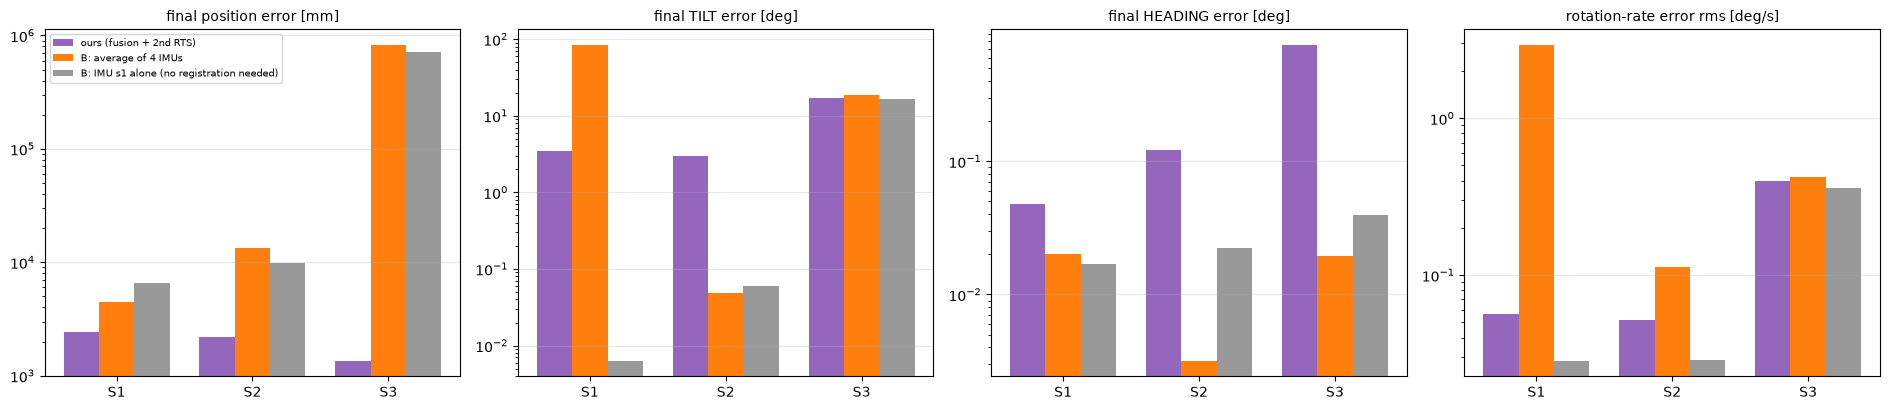

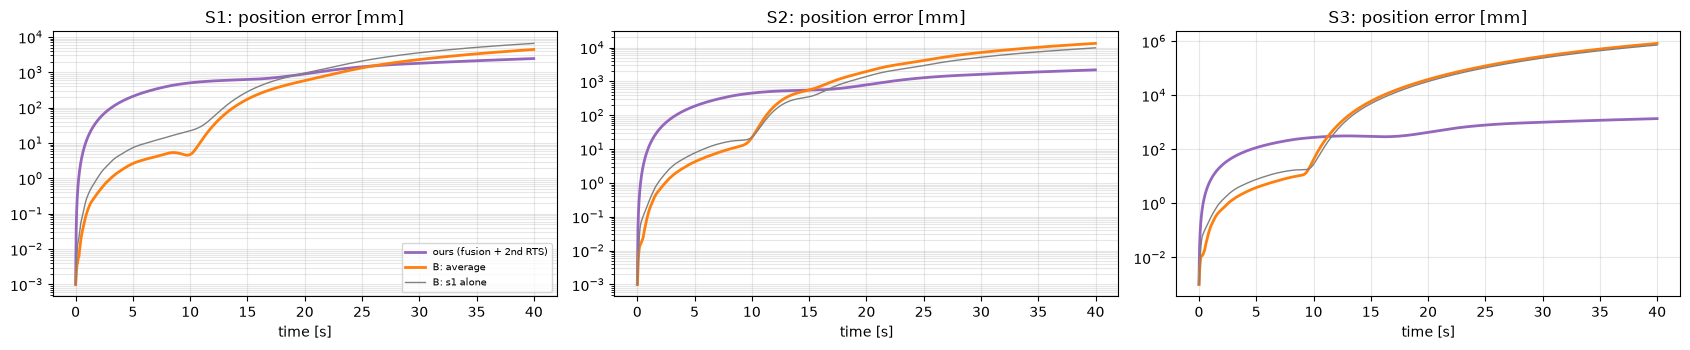

In [103]:
# ======================= summary figure: ours (fused+RTS) vs method B =======================
labels = list(scenarios)
def val(sc, row, col): return scenarios[sc]["table"].loc[row, col]
metrics = [("pos_final_mm", "final position error [mm]"), ("tilt_final_deg", "final TILT error [deg]"),
           ("heading_final_deg", "final HEADING error [deg]"), ("w_rms_dps", "rotation-rate error rms [deg/s]")]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
x = np.arange(len(labels)); w = 0.26
for a, (col, ttl) in zip(ax, metrics):
    a.bar(x - w, [val(s, "ours fused+RTS", col) for s in labels], w, color="tab:purple", label="ours (fusion + 2nd RTS)")
    a.bar(x,     [val(s, "B mean", col) for s in labels], w, color="tab:orange", label="B: average of 4 IMUs")
    a.bar(x + w, [val(s, "B s1", col) for s in labels], w, color="0.6", label="B: IMU s1 alone (no registration needed)")
    a.set_xticks(x); a.set_xticklabels(labels); a.set_yscale("log"); a.set_title(ttl, fontsize=10); a.grid(alpha=0.3, axis="y")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

# position error against time in the three scenarios
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6), sharey=False)
for a, sc in zip(ax, labels):
    t_s = scenarios[sc]["t"]; cv = scenarios[sc]["curves"]
    a.semilogy(t_s, cv["ours fused+RTS"] + 1e-3, "tab:purple", lw=2, label="ours (fusion + 2nd RTS)")
    a.semilogy(t_s, cv["B mean"] + 1e-3, "tab:orange", lw=2, label="B: average")
    a.semilogy(t_s, cv["B s1"] + 1e-3, color="0.5", lw=1, label="B: s1 alone")
    a.set_title(f"{sc}: position error [mm]"); a.set_xlabel("time [s]"); a.grid(alpha=0.3, which="both")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### How to interpret the simulation comparison (rerun at 120 Hz)

Read the registration table and error tables above; old numeric results from the former 104 Hz notebook are intentionally not carried forward.

* **Registration:** under arbitrary mountings, a single static gravity pair cannot identify rotation about gravity. The shortest-rotation method B is therefore not a general 3-D registration method. The board-like case is a special case in which the missing angle may be small because the sensors are already almost parallel.
* **Attitude:** static gyro-bias calibration followed by gyro integration can be competitive when gyro bias and scale are stable. A gyro scale error accumulates with angle and cannot be inferred from a still interval alone.
* **Position:** method B reconstructs gravity from gyro-integrated attitude. A tilt error therefore appears as a false acceleration and is integrated twice. The general pipeline instead estimates gravity in the body frame and continues adapting bias estimates, but its own model errors and assumptions also matter.

The figures here are regenerated with a 120 Hz simulation. Treat the printed numerical tables—not values from an earlier notebook execution—as the current result.


# Chapter 33 — Test 2: the real measurement tests (Part III files)

Now the same comparison on the real data. For every test file of Part III we run method B with the *same* still interval and the *same* $\Delta t=1/120$ s, turn its output into the same track format, and grade it with **exactly the same error functions** (`analyse_static`, `analyse_sine`, `analyse_turns` of Chapter 20).
Our results are taken from Part III (`analysis`), so run Part III first. Method B takes only seconds per file.

For the "angle" column we use the same test-specific angle error as in Chapter 24 (static: final $\lVert\theta\rVert$; sine: rms against the reference; nine turns: closure error).
We also compare the two **registrations** on the real board: the angle between our Wahba $C_i$ and the shortest-rotation $C_i$ from static gravity.

In [104]:
# ======================= method B on every real test, graded with the Part III error functions =======================
def run_method_b_test(test):
    # Returns (t, dt, tracks_B, details) for one test file.
    data, sensors, n = load_csv(test["path"])
    acc, gyro = data[sensors[0]]
    align_s = test.get("align_s") or auto_align_seconds(gyro, DT_VAL)      # same still interval as our pipeline used
    n_still = int(round(align_s / DT_VAL))
    tracks_b, det = method_b_tracks(data, sensors, DT_VAL, n_still)
    return np.arange(n) * DT_VAL, DT_VAL, tracks_b, det

analysis_B, tables_B = {}, {}
for tst in tests:
    if tst["name"] not in analysis: continue                               # only tests already analysed in Part III
    try:
        t_b, dt_b, tr_b, det_b = run_method_b_test(tst)
        table_b, extra_b = ANALYSE[tst["kind"]](t_b, dt_b, tr_b)
        analysis_B[tst["name"]] = (t_b, dt_b, tr_b, table_b, extra_b, det_b)
        tables_B[tst["name"]] = table_b
        print(f"method B done: {tst['name']}")
    except Exception as err:
        print(f"!! method B failed on {tst['name']}: {err}")
if not analysis_B:
    print("no analysed test found: run Part III first (it needs the CSV files in", VAL_DIR.resolve(), ")")

method B done: 20260723_Static_facex
method B done: 20260723_Dinamic_sine_facex_0
method B done: 20260723_Dinamic_sine_face_rotX_0
method B done: 20260723_Dinamic_720degree_face_rotx_2


In [105]:
# ======================= headline comparison: ours vs method B, one line per test =======================
def compare_row(test):
    name = test["name"]
    t_o, dt_o, tr_o, tab_o, ext_o = analysis[name]; t_b, dt_b, tr_b, tab_b, ext_b, det_b = analysis_B[name]
    ours = "fused_rts" if "fused_rts" in tab_o.index else "fused"
    sens_o = [n for n in tab_o.index if n.startswith("s")]; sens_b = [n for n in tab_b.index if n.startswith("s")]
    ang_col, ang_name = {"rest": ("ang_final_deg", "final |theta|"), "sine": ("ang_rms_deg", "rms vs reference"),
                         "turns": ("closure_deg", "closure |theta(T)|")}[test["kind"]]
    row = dict(group=test["title"], axis=test["axis"], angle_metric=ang_name)
    for label, col in (("pos_mm", "pos_final_mm"), ("angle_deg", ang_col)):
        o, b = float(tab_o.loc[ours, col]), float(tab_b.loc["fused", col])
        row[f"{label} ours"] = o
        row[f"{label} B (average)"] = b
        row[f"{label} B/ours"] = b / o if o > 0 else np.nan             # > 1: ours better ; < 1: method B better
        row[f"{label} B s1 alone"] = float(tab_b.loc["s1", col])
    if test["kind"] == "turns":
        row["turns ours"] = float(tab_o.loc[ours, "turns"]); row["turns B"] = float(tab_b.loc["fused", "turns"])
    # registration disagreement between our Wahba C_i and the static-gravity C_i (real board)
    res_o = np.load(npz_paths[name], allow_pickle=True)
    Cb = det_b["B"]
    dis = [reg_error_deg(Cb[s]["C"], res_o[f"{s}_C"]) for s in sens_b[1:]]
    row["registration disagreement max [deg]"] = max(dis) if dis else np.nan
    return row

cmp_names = [tst["name"] for tst in tests if tst["name"] in analysis_B]
cmp_df = pd.DataFrame([compare_row(tst) for tst in tests if tst["name"] in analysis_B], index=cmp_names)
if len(cmp_df):
    cmp_df.to_csv(VAL_OUT / "comparison_ours_vs_B.csv")
    print("B/ours > 1 means OUR pipeline is better; < 1 means method B is better.  pos = final position error [mm]")
    with pd.option_context("display.max_columns", None, "display.width", 260, "display.float_format", "{:,.3f}".format):
        display(cmp_df)

B/ours > 1 means OUR pipeline is better; < 1 means method B is better.  pos = final position error [mm]


,group,axis,angle_metric,pos_mm ours,pos_mm B (average),pos_mm B/ours,pos_mm B s1 alone,angle_deg ours,angle_deg B (average),angle_deg B/ours,angle_deg B s1 alone,registration disagreement max [deg],turns ours,turns B
20260723_Static_facex,A. Static,X,final |theta|,83.512,"19,528.370",233.839,"50,982.838",0.012,0.110,9.179,0.141,16.155,NaN,NaN
20260723_Dinamic_sine_facex_0,"B. Sine, face",X,rms vs reference,626.862,"257,813.601",411.277,"231,807.493",2.998,3.013,1.005,2.993,1.424,NaN,NaN
20260723_Dinamic_sine_face_rotX_0,"C. Sine, rotation axis",X,rms vs reference,725.086,"23,607.061",32.558,"11,382.202",3.044,3.048,1.001,3.082,135.349,NaN,NaN
20260723_Dinamic_720degree_face_rotx_2,"E. Nine turns, rotation axis",X,closure |theta(T)|,384.876,"95,159.909",247.248,"134,728.345",10.041,8.941,0.890,13.522,115.956,2.029,2.026


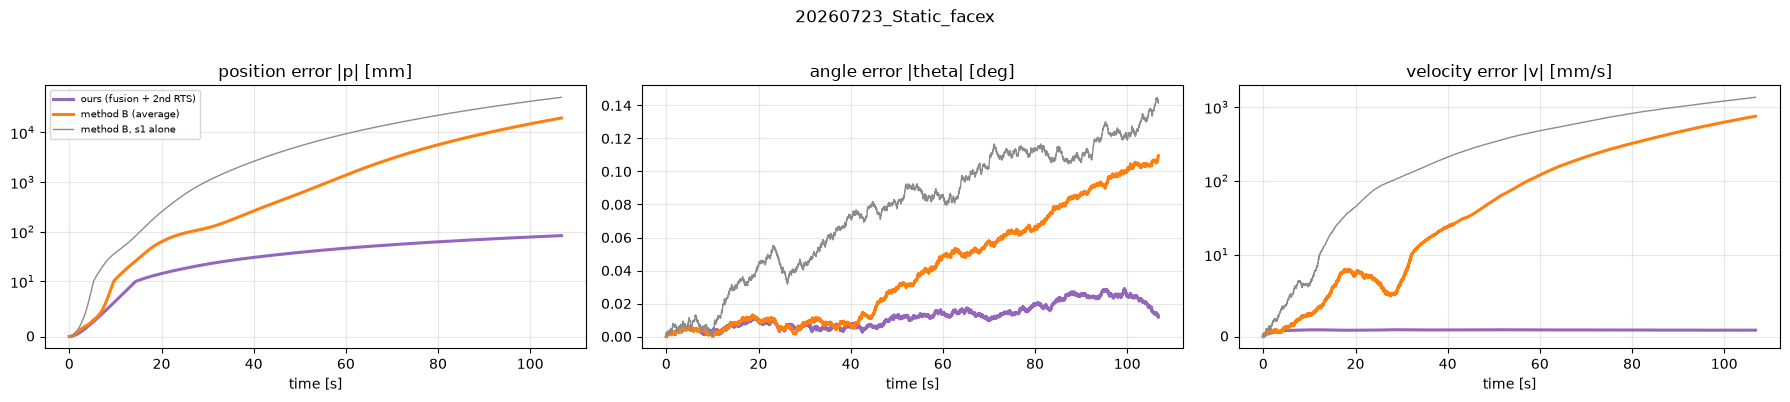

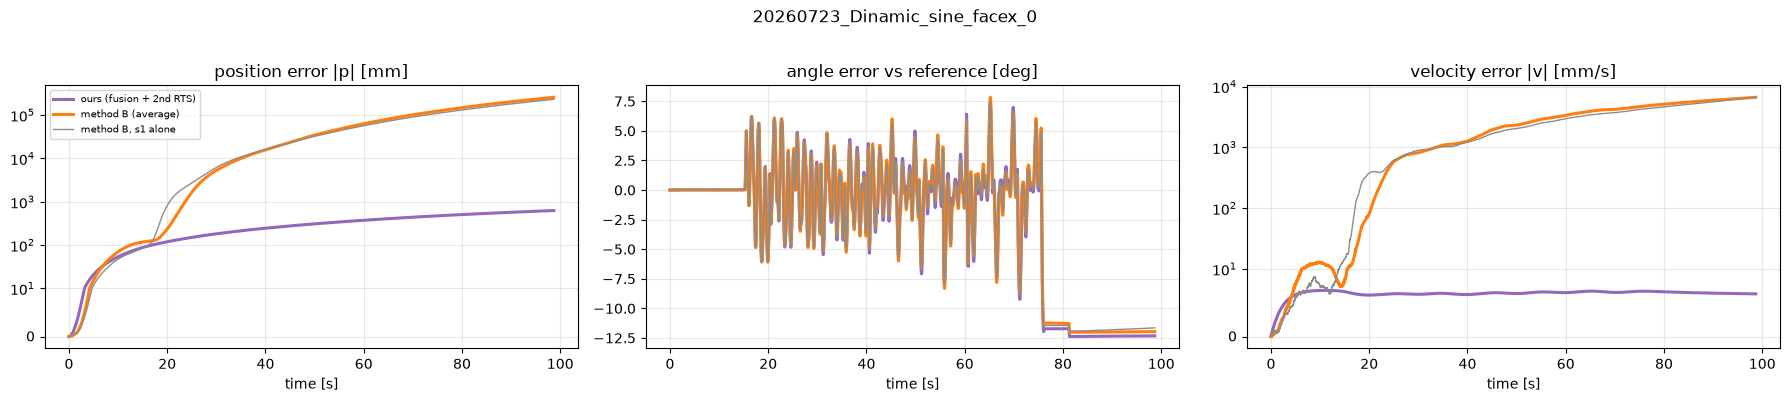

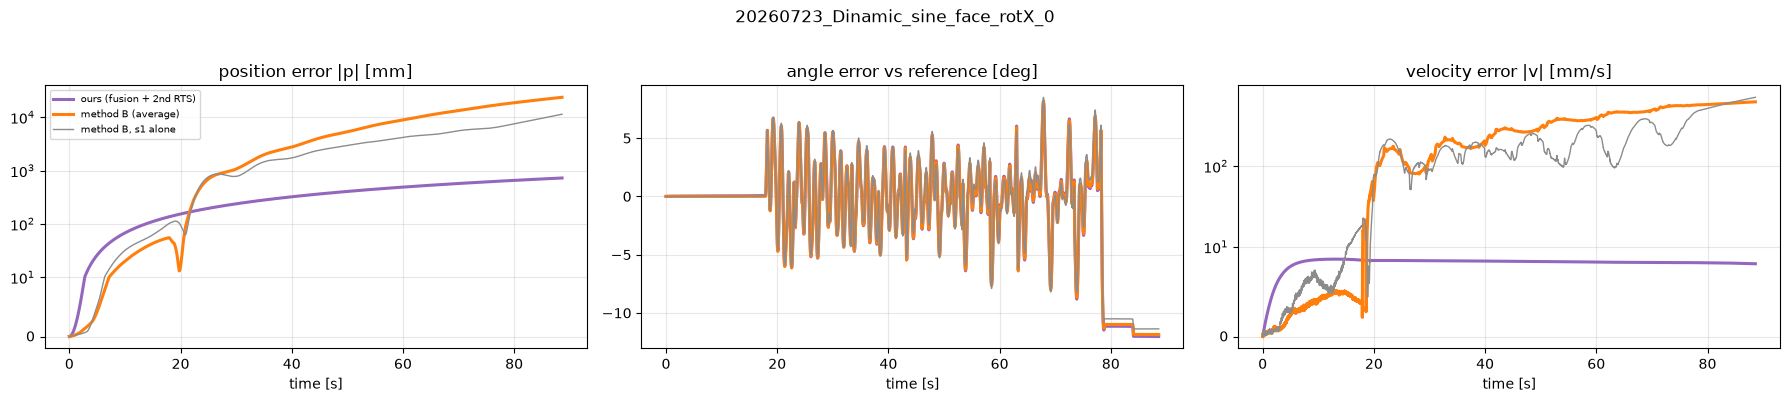

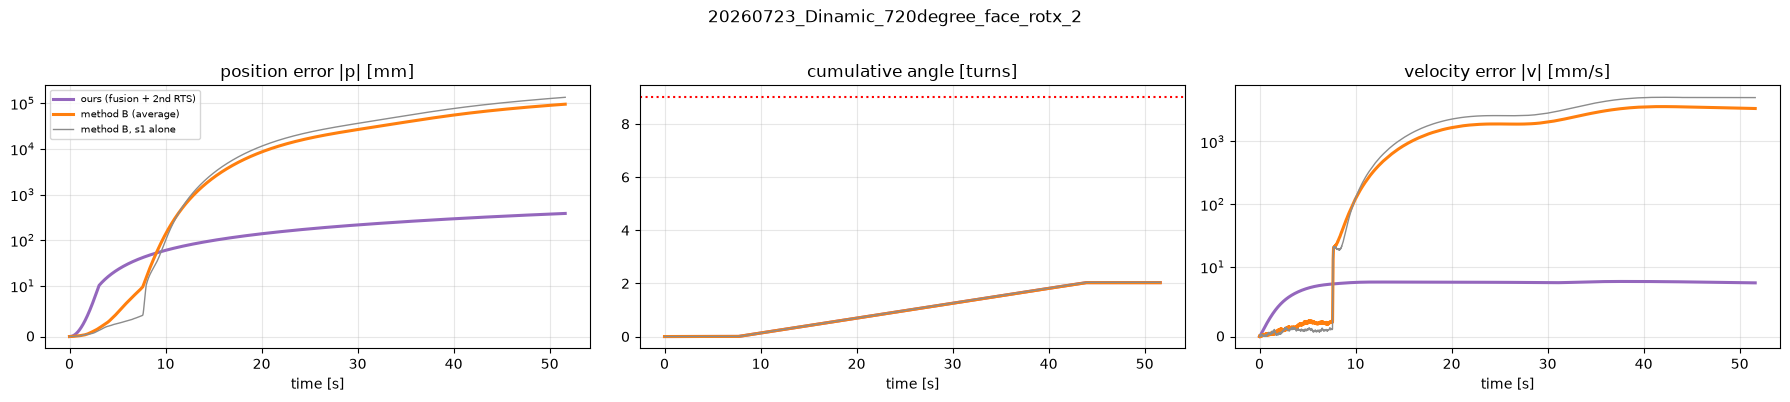

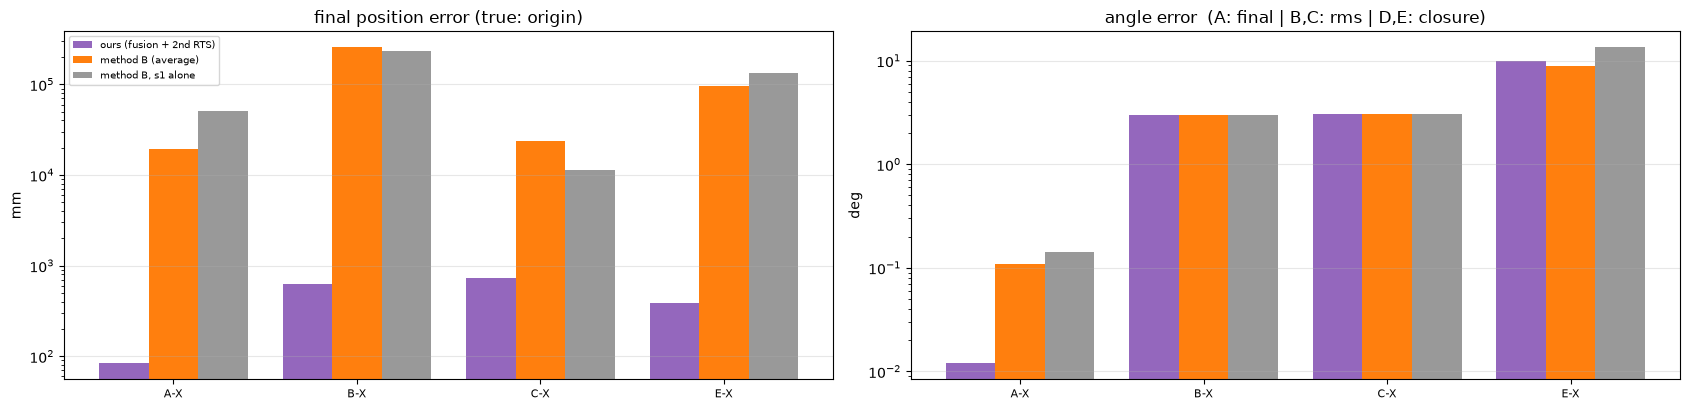

In [106]:
# ======================= figures: per-test curves and an overview =======================
def plot_compare(test):
    name = test["name"]
    t_o, dt_o, tr_o, tab_o, ext_o = analysis[name]; t_b, dt_b, tr_b, tab_b, ext_b, det_b = analysis_B[name]
    ours = "fused_rts" if "fused_rts" in tr_o else "fused"
    ang_key = {"rest": "ang", "sine": "e", "turns": "C"}[test["kind"]]
    scale = 1 / 360.0 if test["kind"] == "turns" else 1.0
    fig, ax = plt.subplots(1, 3, figsize=(18, 3.9))
    for a, key, ttl in ((ax[0], "ep", "position error |p| [mm]"), (ax[1], ang_key, {"rest": "angle error |theta| [deg]", "sine": "angle error vs reference [deg]", "turns": "cumulative angle [turns]"}[test["kind"]]),
                        (ax[2], "ev", "velocity error |v| [mm/s]")):
        a.plot(t_o, ext_o["curves"][ours][key] * (scale if key == ang_key else 1), color="tab:purple", lw=2.2, label="ours (fusion + 2nd RTS)")
        a.plot(t_b, ext_b["curves"]["fused"][key] * (scale if key == ang_key else 1), color="tab:orange", lw=2.2, label="method B (average)")
        a.plot(t_b, ext_b["curves"]["s1"][key] * (scale if key == ang_key else 1), color="0.55", lw=1, label="method B, s1 alone")
        a.set_title(ttl); a.set_xlabel("time [s]"); a.grid(alpha=0.3)
        if key in ("ep", "ev"): a.set_yscale("symlog", linthresh=10)
    if test["kind"] == "turns": ax[1].axhline(TURNS_EXPECTED, color="r", ls=":", label=f"expected {TURNS_EXPECTED} turns")
    ax[0].legend(fontsize=7); fig.suptitle(name, y=1.02)
    plt.tight_layout(); fig.savefig(VAL_OUT / name / "comparison_ours_vs_B.png", dpi=110, bbox_inches="tight"); plt.show()

for tst in tests:
    if tst["name"] in analysis_B: plot_compare(tst)

if len(cmp_df):
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.2)); x = np.arange(len(cmp_df)); w = 0.27
    for a, lab, ttl, unit in ((ax[0], "pos_mm", "final position error (true: origin)", "mm"), (ax[1], "angle_deg", "angle error  (A: final | B,C: rms | D,E: closure)", "deg")):
        a.bar(x - w, cmp_df[f"{lab} ours"], w, color="tab:purple", label="ours (fusion + 2nd RTS)")
        a.bar(x, cmp_df[f"{lab} B (average)"], w, color="tab:orange", label="method B (average)")
        a.bar(x + w, cmp_df[f"{lab} B s1 alone"], w, color="0.6", label="method B, s1 alone")
        a.set_xticks(x); a.set_xticklabels([f"{g.split('.')[0]}-{ax_}" for g, ax_ in zip(cmp_df["group"], cmp_df["axis"])], fontsize=8)
        a.set_yscale("log"); a.set_title(ttl); a.set_ylabel(unit); a.grid(alpha=0.3, axis="y")
    ax[0].legend(fontsize=7); plt.tight_layout(); fig.savefig(VAL_OUT / "comparison_ours_vs_B_overview.png", dpi=110); plt.show()


### How to read the real-test comparison
* **`pos_mm B/ours` ≫ 1** — method B's position drifts much more than ours. Expected from Prediction 3. If it is *astronomically* large (kilometres), suspect the **gyro/accelerometer inconsistency**: the attitude integrated from the gyro and the gravity direction
  measured by the accelerometer disagree (the κ of Chapter 18.5, far from 1), and method B *predicts* gravity from the former.
* **`angle_deg B/ours` < 1** — method B's angle is better (Prediction 2, plausible when the gyro offset is stable). **≈ 1** — the angle error is dominated by something both share (gyro scale error, drift).
* **`turns ours` / `turns B`** — both integrate the same gyro, so they normally agree closely; a common excess over 9 turns is a gyro scale error that no method can see without an external reference.
* **`registration disagreement`** — how far the shortest-rotation shortcut is from our Wahba registration on the *real* board. A small value (about 1° or less) means the real IMUs are mounted almost parallel, so that particular shortcut is acceptable here (Prediction 1).
* **B s1 alone vs B average** — if the average is worse than s1 alone, the equal-weight averaging of badly registered or badly behaved IMUs is hurting.



> **Refresh rule.** Any numeric example produced by a former 104 Hz run is stale after duplicate-row removal and the 120 Hz timing change. Use the current `cmp_df` table and the freshly generated `comparison_ours_vs_B.png` figures above.


# Chapter 34 — Conclusions of the comparison

This is a **structural comparison of assumptions**, not a claim that one estimator wins every data set. The numeric comparison must be regenerated from the 120 Hz, de-duplicated data cells above; all previously cached analysis outputs have been cleared so old 104 Hz numbers are not mistaken for new results.

| Aspect | Likely advantage | Why / condition |
|---|---|---|
| **Simplicity and little tuning** | method B | Static calibration and gyro integration are easy to inspect, but depend on fixed biases and scale. |
| **Rotation angle** | method B can win | A clean, accurately scaled gyro with a stable offset can outperform a model whose filtered angular rate has small systematic error. Verify against the updated tests. |
| **Position on a fixed bench** | Sola ESKF can win | Its zero-position/zero-velocity observation supplies external information that `run_general_*` does not use. This advantage disappears for unconstrained translation or a moving support point. |
| **Position without a support constraint** | `run_general_*` may be more robust than method B | It estimates gravity in body axes and adapts biases, whereas method B predicts gravity from gyro-integrated attitude and freezes the initial offset. |
| **Registration at arbitrary mounting angles** | `run_general_*` or the dynamic-axis ESKF wrapper | A static gravity pair cannot determine rotation about gravity. Wahba uses gravity and angular-rate histories; the ESKF wrapper uses dynamic-axis direction plus gravity-circle phase. |
| **Registration on a nearly parallel board** | method B may be adequate | Its unobserved rotation can be small when the true mountings are already nearly parallel, but this is a geometric assumption. |
| **Time-varying bias and uncertainties** | `run_general_*` / Sola ESKF | These filters update bias estimates and carry covariances. Method B freezes calibration and has no covariance-weighted fusion. |

**Practical recommendation:** first compare the refreshed tables on your actual recordings. Keep the method whose assumptions match the experiment: use the Sola constrained-still ESKF when the support-point constraint is true; use the dynamic-axis alignment only when the recording has enough rotation excitation; and do not rely on static gravity alone for a full relative rotation unless the missing rotation-about-gravity angle is known to be negligible or is supplied from another source.

The simplest gravity-only matrix remains useful as a **starting guess** on a board whose IMUs are already almost parallel. It is not a substitute for a fully observable registration when mounting angles are arbitrary.
